# Do a few early tokens decide the algorithm? — fork-token screen on Qwen3-8B (CPU replay)

**Question.** When Qwen3-8B (bf16, thinking off) is asked to write a path-search function, is the algorithm it
implements (BFS? DFS? Dijkstra? Bellman–Ford?) decided by a few early **"fork" tokens** of its answer, or is it
already fixed by the prompt before the first token is sampled? And does temperature placed on those fork tokens act
as a "creativity knob"?

**Set-up of the original experiment**
* Two coding tasks, each with 40 seeded hidden tests: **T1** path on an unweighted grid (modal answer: BFS) and
  **T2** weighted shortest path (modal answer: Dijkstra).
* Two prompt conditions × 10 paraphrases: a neutral **baseline** and a **ban** prompt
  ("Do not use breadth-first search (BFS)" on T1, "Do not use Dijkstra's algorithm" on T2).
* Every program is labelled by a **sandboxed runtime tracer** (instrumented `heapq` / `deque` / `queue`, order of
  grid-cell reads, passes over the edge list, recursion depth), with **AST rules** as fallback and an OpenRouter LLM
  judge only for tracer/AST disputes.
* Measurements on one shared pool of ~10k labelled generations: (1) algorithm pools at global
  T ∈ {0.3, 0.7, 1.0, 1.3}; (2) a Forking-Paths-style **resampling screen**: 40 base paths are cut after k generated
  tokens, 8 continuations are resampled per cut and labelled, permutation-calibrated multinomial **change points**
  locate where the outcome distribution shifts, and candidate forks are localised to one token and confirmed with
  S = 30 against control pairs; (3) a **prompt swap** at the commitment token; (4) a **fork-window temperature
  knob** against a global-T sweep with random-window and anchored controls; (5) residual-stream **probes**.

**What this notebook runs.** `method.py` orchestrates four phases. `gen1`, `gen2` and `states` need a GPU (vLLM
generation of ~10k samples took about an hour on a 20 GB card; residual states come from HF transformers). This
notebook replays the **CPU half** of the pipeline, with the original code, on the recorded generations shipped in
`mini_demo_data.json`: one dataset of the 40 base-path prompts, each with every labelled generation that belongs to
it.

| step | original command | in this notebook |
|---|---|---|
| S1 hidden tests + reference gate | `python -m tasks.build_tasks` | **re-run** (seeded; time limits re-calibrated on this machine) |
| T2/T3 labeller unit tests | `python tests/test_labeller.py` | **re-run** |
| labelling (sandboxed tracer + AST) | inside `gen1` / `gen2` | **re-run** on the base-path programs |
| `gen1`, `gen2` (vLLM, GPU) | `method.py --phase gen1 / gen2` | replaced by the recorded, labelled generations |
| `states` (HF, GPU) + probes | `method.py --phase states` | states (~1 GB) not shipped, so the probe step finds no states, exactly as in the recorded `method_out.json` |
| `analysis` (judge, T6, screen, swap, knob, verdict, figures) | `method.py --phase analysis` | **re-run** (the recorded OpenRouter judge map is used) |

With the original settings (the defaults below) the notebook reproduces the recorded `method_out.json` of the
experiment, in a few minutes on a CPU-only runtime. That covers the verdict, every screen aggregate, the six confirmed
fork tokens, and the pool, swap, knob and T6 tables. Step 4.7 explains the two small, documented differences.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# numpy, scipy, matplotlib, transformers (+ tokenizers, huggingface_hub) -- pre-installed on Colab, install locally
# only, at Colab's versions (done first so that ruptures below resolves numpy/scipy to these versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'transformers==5.0.0', 'tokenizers==0.22.2',
         'huggingface_hub==1.4.0')

# loguru, ruptures -- NOT pre-installed on Colab, always install (versions of the original environment)
_pip('loguru==0.7.3', 'ruptures==1.1.10')

In [2]:
from __future__ import annotations

# ---- method.py
import argparse
import json
import os
import resource
import sys
import time
from pathlib import Path

from loguru import logger

# ---- analysis/final.py
import ast
import collections
import keyword
import math
import re

import numpy as np

# ---- notebook additions: working folder, the original S1 / unit-test commands, figures
import shutil
import subprocess

import matplotlib.pyplot as plt
from IPython.display import Image, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/experiment-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print("examples (base-path prompts):", len(data["datasets"][0]["examples"]))
print("recorded generations per source file:", data["metadata"]["row_counts"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Do a few early tokens decide the algorithm? -- fork-screen demo data (Qwen3-8B)
examples (base-path prompts): 40
recorded generations per source file: {'pools': 1200, 'screen': 4480, 'localise': 312, 'confirm': 1108, 'swap': 1200, 'knob': 600}


## Configuration

All tunable parameters live here. The defaults are the **original** values of the experiment; the whole notebook then
takes a few minutes on 2 CPUs. Smaller values give a faster, rougher run: `N_EXAMPLES = 4` analyses one paraphrase of
each task × condition, and fewer permutations/bootstraps make p-values and intervals coarser.

In [5]:
N_EXAMPLES = 40          # base-path prompts analysed, of 40 (original: 40 = T1/T2 x baseline/ban x 10 paraphrases)
N_RELABEL = 40           # base-path programs re-labelled in the sandbox (original: every generation, ~10k)
LABEL_WORKERS = 2        # sandbox subprocesses in parallel (original LabelPool(workers=5); Colab has 2 vCPUs)
RUN_LABELLER_UNIT_TESTS = True  # T2/T3: references + bad programs through the sandbox (original: run once)
T6_N_SIM = 200           # simulated paths per effect size in the T6 change-point sensitivity check (original 200)
CPD_N_PERM = 1000        # permutations of the binary-segmentation null (original 1000, pre-registered)
CHI2_N_PERM = 2000       # permutations of the fork-confirmation chi-square test (original 2000, pre-registered)
BOOT_N = 1000            # bootstrap resamples for the swap / knob intervals (original 1000)
BOOT_N_CONTRAST = 2000   # paraphrase-cluster bootstrap resamples for the K1/K4 knob contrasts (original 2000)
DEMO_DIR = "fork_screen_demo"  # working folder that receives the original modules and every output of this run

EXAMPLES = data["datasets"][0]["examples"][:N_EXAMPLES]  # ordered paraphrase-first: [:4] covers all 4 task x condition
print([ex["metadata_bp_id"] for ex in EXAMPLES])

['T1|baseline|0', 'T1|ban|0', 'T2|baseline|0', 'T2|ban|0', 'T1|baseline|1', 'T1|ban|1', 'T2|baseline|1', 'T2|ban|1', 'T1|baseline|2', 'T1|ban|2', 'T2|baseline|2', 'T2|ban|2', 'T1|baseline|3', 'T1|ban|3', 'T2|baseline|3', 'T2|ban|3', 'T1|baseline|4', 'T1|ban|4', 'T2|baseline|4', 'T2|ban|4', 'T1|baseline|5', 'T1|ban|5', 'T2|baseline|5', 'T2|ban|5', 'T1|baseline|6', 'T1|ban|6', 'T2|baseline|6', 'T2|ban|6', 'T1|baseline|7', 'T1|ban|7', 'T2|baseline|7', 'T2|ban|7', 'T1|baseline|8', 'T1|ban|8', 'T2|baseline|8', 'T2|ban|8', 'T1|baseline|9', 'T1|ban|9', 'T2|baseline|9', 'T2|ban|9']


## The original modules

The labeller executes model-written programs in a separate `python -I` subprocess with resource limits (the tracer
monkey-patches `heapq`, `collections.deque` and `queue` globally, and candidate code is untrusted), so its modules
must exist as files. The next cell creates a fresh working folder `fork_screen_demo/` laid out like the original repository;
the `%%writefile` cells after it copy the original source files into it **unchanged**. The analysis code of
`method.py` and `analysis/final.py` is run cell by cell further down.

In [6]:
shutil.rmtree(DEMO_DIR, ignore_errors=True)  # every run starts from a clean folder (no stale caches)
for sub in ("tasks", "harness", "labeller", "analysis", "tests", "logs", "summaries", "figures", "generations",
            "states"):
    os.makedirs(os.path.join(DEMO_DIR, sub), exist_ok=True)
for pkg in ("tasks", "harness", "labeller", "analysis"):
    Path(DEMO_DIR, pkg, "__init__.py").write_text("")
print(sorted(os.listdir(DEMO_DIR)))

['analysis', 'figures', 'generations', 'harness', 'labeller', 'logs', 'states', 'summaries', 'tasks', 'tests']


### `common.py` — paths, logging, seeds and the small statistics used everywhere
`stable_seed` derives every sampling seed from a sha256 of the request (task, condition, paraphrase, arm, prefix
length), `wilson` gives Wilson score intervals as `(p, lo, hi)` tuples, `hill1` is the Hill number of order 1
(exp of the Shannon entropy: the *effective number of algorithms* in a pool), and `tvd` / `js_div` compare outcome
distributions.

In [7]:
%%writefile fork_screen_demo/common.py
"""Shared utilities: paths, logging, hashing, JSONL IO, seeds and the small statistics used everywhere."""

from __future__ import annotations

import hashlib
import json
import math
import sys
import time
from pathlib import Path

import numpy as np
from loguru import logger

ROOT = Path(__file__).resolve().parent
GEN_DIR = ROOT / "generations"
SUM_DIR = ROOT / "summaries"
LOG_DIR = ROOT / "logs"
FIG_DIR = ROOT / "figures"
STATE_DIR = ROOT / "states"
for _d in (GEN_DIR, SUM_DIR, LOG_DIR, FIG_DIR, STATE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen3-8B"
TASKS = ("T1", "T2")
CONDITIONS = ("baseline", "ban")


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def stable_seed(*parts) -> int:
    h = hashlib.sha256(repr(tuple(parts)).encode()).hexdigest()
    return int(h, 16) % (2 ** 31 - 1000)


def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()


def log_hash(name: str, path: Path) -> str:
    h = sha256_file(path)
    with open(LOG_DIR / "hashes.log", "a") as fh:
        fh.write(f"{time.strftime('%Y-%m-%dT%H:%M:%S')}\t{time.time():.3f}\t{name}\t{path.name}\t{h}\n")
    return h


def append_jsonl(path: Path, rows: list[dict]) -> None:
    with open(path, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def read_jsonl(path: Path) -> list[dict]:
    if not Path(path).exists():
        return []
    out = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    continue  # a line still being written by a concurrent appender
    return out


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float, float]:
    if n == 0:
        return (float("nan"), float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (p, max(0.0, c - h), min(1.0, c + h))


def hill1(labels: list) -> float:
    """Hill number of order 1 = exp(Shannon entropy in nats) of the label distribution."""
    if not labels:
        return float("nan")
    _, cnt = np.unique(np.asarray(labels, dtype=object).astype(str), return_counts=True)
    p = cnt / cnt.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def entropy_bits(counts) -> float:
    c = np.asarray(counts, dtype=float)
    if c.sum() <= 0:
        return float("nan")
    p = c[c > 0] / c.sum()
    return float(-(p * np.log2(p)).sum())


def tvd(p, q) -> float:
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    if p.sum() == 0 or q.sum() == 0:
        return float("nan")
    return float(0.5 * np.abs(p / p.sum() - q / q.sum()).sum())


def js_div(p, q) -> float:
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log2(a[mask] / b[mask])).sum())

    return 0.5 * kl(p, m) + 0.5 * kl(q, m)

Writing fork_screen_demo/common.py


### `tasks/t1_grid.py` — T1: unweighted grid path
Task text, the outcome **catalogue** (`BFS, DFS, bidirectional_BFS, IDDFS, astar_greedy, unit_dijkstra` plus
`other` / `no_code`), the banned mode (`BFS`), a seeded generator of 40 hidden tests (edge cases, random grids,
mazes, open grids, serpentines, unreachable goals), the validator and 9 reference solutions (one or more per
catalogue algorithm) that calibrate the time limits and the labeller.

In [8]:
%%writefile fork_screen_demo/tasks/t1_grid.py
"""T1: unweighted grid path. Spec, seeded hidden-test generator, references and validator."""

from __future__ import annotations

import random
from collections import deque

TASK_ID = "T1"
SPEC = (
    "Write a Python function solve(grid, start, goal) that finds a path on a 2-D grid. grid is a list of "
    "equal-length strings in which . is a free cell and # is an obstacle; start and goal are (row, col) tuples. "
    "Moves go up, down, left or right between free cells. Return any valid path as a list of (row, col) tuples "
    "from start to goal inclusive, or [] if the goal is unreachable or either endpoint is blocked. The grid has at "
    "most 30 rows and 30 columns. Use only the Python standard library. Return only one ```python code block "
    "containing the function and its imports."
)

# Catalogue (merged modes). 'other' and 'no_code' complete the outcome space.
CATALOGUE = ["BFS", "DFS", "bidirectional_BFS", "IDDFS", "astar_greedy", "unit_dijkstra"]
BANNED_MODE = "BFS"
CATALOGUE_DEFS = {
    "BFS": "breadth-first search with a FIFO queue (deque.popleft, list.pop(0) or queue.Queue), expanding cells in rings of increasing distance from the start",
    "DFS": "depth-first search with a LIFO stack or recursion (no growing depth limit), following one branch as deep as possible",
    "bidirectional_BFS": "a search with two frontiers grown from start and from goal that meet in the middle",
    "IDDFS": "iterative-deepening depth-first search: repeated depth-limited DFS with a growing depth limit",
    "astar_greedy": "A* or greedy best-first search: a priority queue ordered by a heuristic such as the Manhattan distance to the goal (with or without path cost)",
    "unit_dijkstra": "Dijkstra's algorithm on the grid: a priority queue keyed only by path length / distance from the start (no heuristic)",
    "other": "any other approach (e.g. brute-force enumeration, dynamic programming, flood fill without a queue, wall following)",
}


def free(grid: list[str], cell: tuple[int, int]) -> bool:
    r, c = cell
    return 0 <= r < len(grid) and 0 <= c < len(grid[0]) and grid[r][c] == "."


def bfs_dist(grid: list[str], start: tuple[int, int]) -> dict:
    """Reference BFS distances from start (used by the validator and the tracer)."""
    if not free(grid, start):
        return {}
    dist = {start: 0}
    q = deque([start])
    R, C = len(grid), len(grid[0])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in dist:
                dist[(nr, nc)] = dist[(r, c)] + 1
                q.append((nr, nc))
    return dist


def reachable(grid: list[str], start, goal) -> bool:
    start, goal = tuple(start), tuple(goal)
    if not free(grid, start) or not free(grid, goal):
        return False
    return goal in bfs_dist(grid, start)


def validate(case: dict, out) -> tuple[bool, str]:
    grid, start, goal = case["grid"], tuple(case["start"]), tuple(case["goal"])
    exp_reach = case["reachable"]
    if not isinstance(out, (list, tuple)):
        return False, f"output is {type(out).__name__}, not a list"
    if not exp_reach:
        return (len(out) == 0, "expected [] (unreachable or blocked)" if len(out) else "ok")
    if len(out) == 0:
        return False, "returned [] but goal is reachable"
    try:
        path = [tuple(int(x) for x in cell) for cell in out]
    except (TypeError, ValueError):
        return False, "cells are not (row, col) pairs"
    if any(len(p) != 2 for p in path):
        return False, "cells are not (row, col) pairs"
    if path[0] != start:
        return False, "path does not start at start"
    if path[-1] != goal:
        return False, "path does not end at goal"
    for p in path:
        if not free(grid, p):
            return False, f"cell {p} is a wall or out of bounds"
    for a, b in zip(path, path[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False, f"non-adjacent step {a}->{b}"
    return True, "ok"


# ----------------------------------------------------------------------------- generators
def _rand_grid(rng: random.Random, R: int, C: int, dens: float) -> list[str]:
    return ["".join("#" if rng.random() < dens else "." for _ in range(C)) for _ in range(R)]


def _rand_free(rng: random.Random, grid: list[str]) -> tuple[int, int]:
    cells = [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]
    return rng.choice(cells)


def _maze(rng: random.Random, k: int) -> list[str]:
    """Random-DFS maze on a (2k+1) x (2k+1) grid."""
    n = 2 * k + 1
    g = [["#"] * n for _ in range(n)]
    stack = [(1, 1)]
    g[1][1] = "."
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 < r + dr < n and 0 < c + dc < n and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return ["".join(row) for row in g]


def _serpentine(R: int, C: int, flip: bool) -> list[str]:
    g = [["."] * C for _ in range(R)]
    for i, r in enumerate(range(1, R - 1, 2)):
        gap = (C - 1) if (i % 2 == 0) != flip else 0
        for c in range(C):
            if c != gap:
                g[r][c] = "#"
    return ["".join(row) for row in g]


def make_cases(seed: int = 1234) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name, grid, start, goal):
        cases.append({"name": name, "grid": grid, "start": list(start), "goal": list(goal),
                      "reachable": reachable(grid, start, goal)})

    # 8 edge cases
    add("start_eq_goal", ["....", ".#..", "...."], (1, 2), (1, 2))
    add("start_on_wall", ["....", ".#..", "...."], (1, 1), (2, 3))
    add("goal_on_wall", ["....", ".#..", "...."], (0, 0), (1, 1))
    add("one_by_one", ["."], (0, 0), (0, 0))
    add("corridor_1xN", ["." * 25], (0, 0), (0, 24))
    add("corridor_Nx1", ["."] * 25, (24, 0), (0, 0))
    add("walled_goal", [".....", ".###.", ".#.#.", ".###.", "....."], (0, 0), (2, 2))
    add("enclosed_start", ["###....", "#.#....", "###....", "......."], (1, 1), (3, 6))
    # 12 random grids 10x10..30x30, density 0.10-0.35
    for i in range(12):
        R, C = rng.randint(10, 30), rng.randint(10, 30)
        g = _rand_grid(rng, R, C, rng.uniform(0.10, 0.35))
        s, t = _rand_free(rng, g), _rand_free(rng, g)
        add(f"random_{i}", g, s, t)
    # 6 random-DFS mazes up to 29x29
    for i, k in enumerate([5, 7, 9, 11, 13, 14]):
        g = _maze(rng, k)
        n = len(g)
        add(f"maze_{i}", g, (1, 1), (n - 2, n - 2))
    # 4 open 30x30
    for i in range(4):
        g = ["." * 30] * 30
        add(f"open_{i}", g, (rng.randrange(30), rng.randrange(30)), (rng.randrange(30), rng.randrange(30)))
    # 4 serpentine long-path grids
    for i, (R, C) in enumerate([(29, 29), (30, 30), (27, 30), (30, 25)]):
        g = _serpentine(R, C, flip=bool(i % 2))
        add(f"serpentine_{i}", g, (0, 0), (R - 1, 0 if (len(range(1, R - 1, 2)) % 2 == 0) else C - 1))
    # 6 large unreachable grids (a full wall separates the endpoints)
    for i in range(6):
        g = [list(row) for row in _rand_grid(rng, 30, 30, 0.15)]
        if i % 2 == 0:
            wc = rng.randint(8, 21)
            for r in range(30):
                g[r][wc] = "#"
            s = (rng.randrange(30), rng.randrange(0, wc))
            t = (rng.randrange(30), rng.randrange(wc + 1, 30))
        else:
            wr = rng.randint(8, 21)
            for c in range(30):
                g[wr][c] = "#"
            s = (rng.randrange(0, wr), rng.randrange(30))
            t = (rng.randrange(wr + 1, 30), rng.randrange(30))
        g[s[0]][s[1]] = "."
        g[t[0]][t[1]] = "."
        add(f"unreachable_{i}", ["".join(row) for row in g], s, t)
    # order small -> large so pathological programs fail early on cheap cases
    cases.sort(key=lambda cs: len(cs["grid"]) * len(cs["grid"][0]))
    for i, cs in enumerate(cases):
        cs["idx"] = i
    return cases


def case_args(case: dict) -> tuple:
    return (list(case["grid"]), tuple(case["start"]), tuple(case["goal"]))


# ----------------------------------------------------------------------------- references
REFERENCES: dict[str, tuple[str, str]] = {}

REFERENCES["ref_bfs"] = ("BFS", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    sr, sc = start
    gr, gc = goal
    if grid[sr][sc] == '#' or grid[gr][gc] == '#':
        return []
    parent = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                q.append((nr, nc))
    return []
''')

REFERENCES["ref_bfs_listpop0"] = ("BFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] != '.' or grid[goal[0]][goal[1]] != '.':
        return []
    prev = {start: None}
    frontier = [start]
    while frontier:
        cur = frontier.pop(0)
        if cur == goal:
            out = []
            while cur is not None:
                out.append(cur)
                cur = prev[cur]
            return out[::-1]
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = cur[0] + dr, cur[1] + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                frontier.append((nr, nc))
    return []
''')

REFERENCES["ref_dfs_iter"] = ("DFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    stack = [start]
    parent = {start: None}
    while stack:
        cur = stack.pop()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                stack.append((nr, nc))
    return []
''')

REFERENCES["ref_dfs_rec"] = ("DFS", '''
import sys

def solve(grid, start, goal):
    sys.setrecursionlimit(10000)
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    seen = set()
    path = []

    def dfs(r, c):
        if (r, c) == goal:
            path.append((r, c))
            return True
        seen.add((r, c))
        path.append((r, c))
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in seen:
                if dfs(nr, nc):
                    return True
        path.pop()
        return False

    return path if dfs(start[0], start[1]) else []
''')

REFERENCES["ref_bidir_bfs"] = ("bidirectional_BFS", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    if start == goal:
        return [start]
    par_s = {start: None}
    par_g = {goal: None}
    qs, qg = deque([start]), deque([goal])

    def nbrs(cell):
        r, c = cell
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                yield (nr, nc)

    def build(meet):
        left = []
        cur = meet
        while cur is not None:
            left.append(cur)
            cur = par_s[cur]
        left.reverse()
        cur = par_g[meet]
        while cur is not None:
            left.append(cur)
            cur = par_g[cur]
        return left

    while qs and qg:
        for _ in range(len(qs)):
            cur = qs.popleft()
            for nb in nbrs(cur):
                if nb not in par_s:
                    par_s[nb] = cur
                    if nb in par_g:
                        return build(nb)
                    qs.append(nb)
        for _ in range(len(qg)):
            cur = qg.popleft()
            for nb in nbrs(cur):
                if nb not in par_g:
                    par_g[nb] = cur
                    if nb in par_s:
                        return build(nb)
                    qg.append(nb)
    return []
''')

REFERENCES["ref_iddfs"] = ("IDDFS", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    n_free = sum(row.count('.') for row in grid)
    cut = [False]

    def dls(cell, depth, limit, path, best):
        if cell == goal:
            return True
        if depth == limit:
            cut[0] = True
            return False
        r, c = cell
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            nxt = (nr, nc)
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                if best.get(nxt, 10 ** 9) <= depth + 1:
                    continue
                best[nxt] = depth + 1
                path.append(nxt)
                if dls(nxt, depth + 1, limit, path, best):
                    return True
                path.pop()
        return False

    for limit in range(n_free + 1):
        path = [start]
        cut[0] = False
        if dls(start, 0, limit, path, {start: 0}):
            return path
        if not cut[0]:
            return []
    return []
''')

REFERENCES["ref_astar"] = ("astar_greedy", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []

    def h(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    open_heap = [(h(start), 0, start)]
    g = {start: 0}
    came = {start: None}
    while open_heap:
        f, cost, cur = heapq.heappop(open_heap)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = came[cur]
            return path[::-1]
        if cost > g[cur]:
            continue
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                ng = cost + 1
                if ng < g.get((nr, nc), float('inf')):
                    g[(nr, nc)] = ng
                    came[(nr, nc)] = cur
                    heapq.heappush(open_heap, (ng + h((nr, nc)), ng, (nr, nc)))
    return []
''')

REFERENCES["ref_greedy"] = ("astar_greedy", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    pq = [(abs(start[0] - goal[0]) + abs(start[1] - goal[1]), start)]
    came = {start: None}
    while pq:
        _, cur = heapq.heappop(pq)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = came[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in came:
                came[(nr, nc)] = cur
                heapq.heappush(pq, (abs(nr - goal[0]) + abs(nc - goal[1]), (nr, nc)))
    return []
''')

REFERENCES["ref_unit_dijkstra"] = ("unit_dijkstra", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    dist = {start: 0}
    prev = {start: None}
    pq = [(0, start)]
    while pq:
        d, cur = heapq.heappop(pq)
        if d > dist[cur]:
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                nd = d + 1
                if nd < dist.get((nr, nc), float('inf')):
                    dist[(nr, nc)] = nd
                    prev[(nr, nc)] = cur
                    heapq.heappush(pq, (nd, (nr, nc)))
    return []
''')

# Programs that are expected to FAIL (validator / limit tests), never part of the catalogue references.
BAD_PROGRAMS: dict[str, str] = {
    "bad_nonadjacent": '''
def solve(grid, start, goal):
    if grid[start[0]][start[1]] == '#' or grid[goal[0]][goal[1]] == '#':
        return []
    return [start, goal] if start != goal else [start]
''',
    "bad_always_empty": '''
def solve(grid, start, goal):
    return []
''',
}

Writing fork_screen_demo/tasks/t1_grid.py


### `tasks/t2_wsp.py` — T2: weighted shortest path
Same structure for T2: catalogue `dijkstra, bellman_ford_spfa, bidirectional_dijkstra, floyd_warshall, dial`,
banned mode `dijkstra`, 40 hidden tests (each checked against Dijkstra *and* Floyd–Warshall), 8 references and two
deliberately bad programs.

In [9]:
%%writefile fork_screen_demo/tasks/t2_wsp.py
"""T2: weighted shortest path. Spec, seeded hidden-test generator, references and validator."""

from __future__ import annotations

import heapq
import random

TASK_ID = "T2"
SPEC = (
    "Write a Python function solve(n, edges, s, t) that returns the length of the shortest path from node s to node "
    "t in a directed graph with nodes 0..n-1. edges is a list of (u, v, w) tuples, an edge from u to v with "
    "non-negative integer weight w <= 100; the graph may contain cycles, self-loops and parallel edges, and n <= 100. "
    "Return the shortest distance as an integer, 0 if s == t, or -1 if t is unreachable from s. Use only the Python "
    "standard library. Return only one ```python code block containing the function and its imports."
)

CATALOGUE = ["dijkstra", "bellman_ford_spfa", "bidirectional_dijkstra", "floyd_warshall", "dial"]
BANNED_MODE = "dijkstra"
CATALOGUE_DEFS = {
    "dijkstra": "Dijkstra's algorithm: repeatedly settle the unvisited node with the smallest tentative distance (binary heap / priority queue, or a linear scan for the minimum)",
    "bellman_ford_spfa": "Bellman-Ford (relax all edges repeatedly, up to n-1 rounds or until no change) or SPFA / queue-based label-correcting: a FIFO queue (deque, list or Queue) to which a node is (re-)appended whenever its tentative distance improves via dist[v] > dist[u] + w, so nodes can be processed several times. This counts as bellman_ford_spfa even if the code or its comments call it 'BFS' or '0-1 BFS'",
    "bidirectional_dijkstra": "bidirectional Dijkstra: two Dijkstra searches, forward from s and backward from t on reversed edges, meeting in the middle",
    "floyd_warshall": "Floyd-Warshall: all-pairs dynamic programming with a triple loop d[i][j] = min(d[i][j], d[i][k] + d[k][j])",
    "dial": "Dial's algorithm: Dijkstra with a bucket queue indexed by integer distance",
    "other": "any other approach (e.g. plain BFS that visits each node at most once and ignores weights, DFS enumeration of paths, memoised recursion, a true 0-1 BFS that never re-enqueues a node, A*)",
}


def ref_dijkstra(n: int, edges, s: int, t: int) -> int:
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    dist = [None] * n
    dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if dist[v] is None or nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1


def ref_floyd(n: int, edges, s: int, t: int) -> int:
    INF = float("inf")
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        if w < d[u][v]:
            d[u][v] = w
    for k in range(n):
        dk = d[k]
        for i in range(n):
            dik = d[i][k]
            if dik == INF:
                continue
            di = d[i]
            for j in range(n):
                if dik + dk[j] < di[j]:
                    di[j] = dik + dk[j]
    return -1 if d[s][t] == INF else int(d[s][t])


def validate(case: dict, out) -> tuple[bool, str]:
    exp = case["expected"]
    if isinstance(out, bool) or not isinstance(out, (int, float)):
        return False, f"output is {type(out).__name__}, not an int"
    if out != exp:
        return False, f"wrong distance {out!r} (expected {exp})"
    return True, "ok"


# ----------------------------------------------------------------------------- generators
def _rand_edges(rng: random.Random, n: int, m: int, wmax: int = 100, wmin: int = 0) -> list[tuple[int, int, int]]:
    return [(rng.randrange(n), rng.randrange(n), rng.randint(wmin, wmax)) for _ in range(m)]


def make_cases(seed: int = 4321) -> list[dict]:
    rng = random.Random(seed)
    cases: list[dict] = []

    def add(name, n, edges, s, t):
        e = [list(x) for x in edges]
        exp = ref_dijkstra(n, edges, s, t)
        chk = ref_floyd(n, edges, s, t)
        assert exp == chk, f"reference mismatch on {name}: {exp} vs {chk}"
        cases.append({"name": name, "n": n, "edges": e, "s": s, "t": t, "expected": exp})

    # 9 edge cases
    add("s_eq_t", 4, [(0, 1, 3), (1, 2, 4), (2, 0, 1)], 2, 2)
    add("n_one", 1, [], 0, 0)
    add("no_edges", 5, [], 0, 3)
    add("unreachable", 6, [(0, 1, 2), (1, 2, 2), (3, 4, 1), (4, 5, 1)], 0, 5)
    add("zero_weights", 5, [(0, 1, 0), (1, 2, 0), (2, 3, 5), (0, 3, 6), (3, 4, 0)], 0, 4)
    add("zero_cycle", 5, [(0, 1, 0), (1, 2, 0), (2, 0, 0), (2, 3, 7), (1, 3, 9), (3, 4, 1)], 0, 4)
    add("self_loops", 4, [(0, 0, 5), (0, 1, 2), (1, 1, 0), (1, 2, 2), (2, 2, 1), (2, 3, 2)], 0, 3)
    add("parallel_edges", 4, [(0, 1, 9), (0, 1, 3), (0, 1, 7), (1, 2, 5), (1, 2, 1), (2, 3, 4), (0, 3, 20)], 0, 3)
    add("source_no_out", 5, [(1, 0, 1), (2, 1, 1), (3, 4, 2)], 0, 4)
    # 15 random graphs, n in [5, 100], |E| <= 1000
    for i in range(15):
        n = rng.randint(5, 100)
        m = rng.randint(n, min(1000, 6 * n))
        add(f"random_{i}", n, _rand_edges(rng, n, m), rng.randrange(n), rng.randrange(n))
    # 6 dense graphs, n = 60-100
    for i in range(6):
        n = rng.randint(60, 100)
        m = n * n // 3
        add(f"dense_{i}", n, _rand_edges(rng, n, m, wmin=1), 0, n - 1)
    # 5 long chains, n = 100: a cheap 99-hop chain plus tempting expensive shortcuts and cheap dead ends
    for i in range(5):
        n = 100
        edges = [(k, k + 1, rng.randint(1, 3)) for k in range(n - 1)]
        chain_len = sum(w for _, _, w in edges)
        for _ in range(60):
            a = rng.randrange(0, n - 10)
            b = rng.randrange(a + 2, n)
            seg = sum(edges[k][2] for k in range(a, b))
            edges.append((a, b, min(100, seg + rng.randint(1, 30))))  # never better than the chain
        for _ in range(20):
            a = rng.randrange(n)
            edges.append((a, rng.randrange(n), 0 if rng.random() < 0.3 else rng.randint(0, 2)))  # cheap noise edges
        edges = [e for e in edges if not (e[2] <= 2 and e[1] > e[0] + 1 and e[0] < n - 1)]  # no cheap forward skips
        rng.shuffle(edges)
        add(f"chain_{i}", n, edges, 0, n - 1)
        assert chain_len >= 0
    # 5 graphs with many equal-weight paths (layered grid DAG + back edges)
    for i in range(5):
        L, Wd = rng.randint(6, 10), rng.randint(4, 9)
        n = L * Wd + 2
        edges = []
        w = rng.randint(1, 5)
        for j in range(Wd):
            edges.append((0, 1 + j, w))
            edges.append((1 + (L - 1) * Wd + j, n - 1, w))
        for l in range(L - 1):
            for j in range(Wd):
                for j2 in range(Wd):
                    edges.append((1 + l * Wd + j, 1 + (l + 1) * Wd + j2, w))
        for _ in range(20):
            a, b = rng.randrange(n), rng.randrange(n)
            edges.append((b, a, rng.randint(50, 100)))
        rng.shuffle(edges)
        add(f"equal_paths_{i}", n, edges, 0, n - 1)
    cases.sort(key=lambda cs: cs["n"] + len(cs["edges"]))
    for i, cs in enumerate(cases):
        cs["idx"] = i
    return cases


def case_args(case: dict) -> tuple:
    return (case["n"], [tuple(e) for e in case["edges"]], case["s"], case["t"])


# ----------------------------------------------------------------------------- references
REFERENCES: dict[str, tuple[str, str]] = {}

REFERENCES["ref_dijkstra"] = ("dijkstra", '''
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return -1
''')

REFERENCES["ref_dijkstra_visited"] = ("dijkstra", '''
import heapq
from collections import defaultdict

def solve(n, edges, s, t):
    graph = defaultdict(list)
    for u, v, w in edges:
        graph[u].append((w, v))
    visited = set()
    heap = [(0, s, (s,))]
    while heap:
        cost, node, trail = heapq.heappop(heap)
        if node in visited:
            continue
        visited.add(node)
        if node == t:
            return cost
        for w, nxt in graph[node]:
            if nxt not in visited:
                heapq.heappush(heap, (cost + w, nxt, trail + (nxt,)))
    return -1
''')

REFERENCES["ref_dijkstra_obfuscated"] = ("dijkstra", '''
from heapq import heappush as aa, heappop as bb

def solve(n, edges, s, t):
    qq = {}
    for x, y, z in edges:
        qq.setdefault(x, []).append((y, z))
    zz = {s: 0}
    kk = [(0, s)]
    while kk:
        a1, b1 = bb(kk)
        if a1 > zz.get(b1, a1):
            continue
        if b1 == t:
            return a1
        for c1, d1 in qq.get(b1, ()):
            e1 = a1 + d1
            if e1 < zz.get(c1, e1 + 1):
                zz[c1] = e1
                aa(kk, (e1, c1))
    return 0 if s == t else -1
''')

REFERENCES["ref_bellman_ford"] = ("bellman_ford_spfa", '''
def solve(n, edges, s, t):
    if s == t:
        return 0
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    for _ in range(n - 1):
        changed = False
        for u, v, w in edges:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                changed = True
        if not changed:
            break
    return -1 if dist[t] == INF else dist[t]
''')

REFERENCES["ref_spfa"] = ("bellman_ford_spfa", '''
from collections import deque

def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    in_queue = [False] * n
    q = deque([s])
    in_queue[s] = True
    while q:
        u = q.popleft()
        in_queue[u] = False
        for v, w in adj[u]:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                if not in_queue[v]:
                    q.append(v)
                    in_queue[v] = True
    return -1 if dist[t] == INF else dist[t]
''')

REFERENCES["ref_bidir_dijkstra"] = ("bidirectional_dijkstra", '''
import heapq

def solve(n, edges, s, t):
    if s == t:
        return 0
    fwd = [[] for _ in range(n)]
    bwd = [[] for _ in range(n)]
    for u, v, w in edges:
        fwd[u].append((v, w))
        bwd[v].append((u, w))
    INF = float('inf')
    df = {s: 0}
    db = {t: 0}
    pf = [(0, s)]
    pb = [(0, t)]
    done_f, done_b = set(), set()
    best = INF
    while pf and pb:
        if pf[0][0] + pb[0][0] >= best:
            break
        if pf[0][0] <= pb[0][0]:
            d, u = heapq.heappop(pf)
            if u in done_f:
                continue
            done_f.add(u)
            for v, w in fwd[u]:
                nd = d + w
                if nd < df.get(v, INF):
                    df[v] = nd
                    heapq.heappush(pf, (nd, v))
                if v in db:
                    best = min(best, nd + db[v])
        else:
            d, u = heapq.heappop(pb)
            if u in done_b:
                continue
            done_b.add(u)
            for v, w in bwd[u]:
                nd = d + w
                if nd < db.get(v, INF):
                    db[v] = nd
                    heapq.heappush(pb, (nd, v))
                if v in df:
                    best = min(best, nd + df[v])
    return -1 if best == INF else best
''')

REFERENCES["ref_floyd_warshall"] = ("floyd_warshall", '''
def solve(n, edges, s, t):
    INF = float('inf')
    d = [[INF] * n for _ in range(n)]
    for i in range(n):
        d[i][i] = 0
    for u, v, w in edges:
        if w < d[u][v]:
            d[u][v] = w
    for k in range(n):
        for i in range(n):
            for j in range(n):
                if d[i][k] + d[k][j] < d[i][j]:
                    d[i][j] = d[i][k] + d[k][j]
    return -1 if d[s][t] == INF else d[s][t]
''')

REFERENCES["ref_dial"] = ("dial", '''
def solve(n, edges, s, t):
    if s == t:
        return 0
    adj = [[] for _ in range(n)]
    maxw = 0
    for u, v, w in edges:
        adj[u].append((v, w))
        maxw = max(maxw, w)
    INF = float('inf')
    dist = [INF] * n
    dist[s] = 0
    buckets = [[] for _ in range(maxw * n + 1)]
    buckets[0].append(s)
    done = [False] * n
    for d in range(len(buckets)):
        for u in buckets[d]:
            if done[u] or d != dist[u]:
                continue
            done[u] = True
            if u == t:
                return d
            for v, w in adj[u]:
                if d + w < dist[v]:
                    dist[v] = d + w
                    buckets[d + w].append(v)
    return -1
''')

BAD_PROGRAMS: dict[str, str] = {
    "bad_bruteforce_paths": '''
def solve(n, edges, s, t):
    adj = {}
    for u, v, w in edges:
        adj.setdefault(u, []).append((v, w))
    best = [None]
    def go(u, seen, cost):
        if u == t:
            if best[0] is None or cost < best[0]:
                best[0] = cost
            return
        for v, w in adj.get(u, []):
            if v not in seen:
                seen.add(v)
                go(v, seen, cost + w)
                seen.discard(v)
    go(s, {s}, 0)
    return -1 if best[0] is None else best[0]
''',
    "bad_wrong_distance": '''
def solve(n, edges, s, t):
    return 1 if s != t else 0
''',
}

Writing fork_screen_demo/tasks/t2_wsp.py


### `tasks/build_tasks.py` — S1: hidden-test files and per-case time limits
Runs every reference 3× on every case under a 5-process pool load, sets each case's limit to
`max(1 s, 10 × slowest reference)` and checks that every reference passes its own task (the gate).

In [10]:
%%writefile fork_screen_demo/tasks/build_tasks.py
"""S1: build hidden-test JSON files, time every reference 3x under pool load, derive per-case limits, run the gate.

Usage: .venv/bin/python -m tasks.build_tasks
"""

from __future__ import annotations

import json
import multiprocessing as mp
import sys
import time
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from tasks import t1_grid, t2_wsp  # noqa: E402

MODS = {"T1": t1_grid, "T2": t2_wsp}


def _time_ref(args: tuple) -> tuple[str, str, list[float], list[bool], list[str]]:
    task, name, code, cases = args
    T = MODS[task]
    ns: dict = {"__name__": "ref"}
    exec(compile(code, f"<{name}>", "exec"), ns)  # noqa: S102 - trusted reference code
    sys.setrecursionlimit(20000)
    times, oks, whys = [], [], []
    for case in cases:
        best = 0.0
        ok_all, why = True, "ok"
        for _ in range(3):
            a = T.case_args(case)
            t0 = time.perf_counter()
            out = ns["solve"](*a)
            el = time.perf_counter() - t0
            best = max(best, el)
            ok, w = T.validate(case, out)
            if not ok:
                ok_all, why = False, w
        times.append(best)
        oks.append(ok_all)
        whys.append(why)
    return task, name, times, oks, whys


def main() -> None:
    out_summary: dict = {}
    jobs = []
    all_cases = {}
    for task, T in MODS.items():
        cases = T.make_cases()
        all_cases[task] = cases
        for name, (_, code) in T.REFERENCES.items():
            jobs.append((task, name, code, cases))
    with ProcessPoolExecutor(max_workers=5, mp_context=mp.get_context("spawn")) as ex:
        results = list(ex.map(_time_ref, jobs))
    for task, T in MODS.items():
        cases = all_cases[task]
        per = {name: (times, oks, whys) for (tk, name, times, oks, whys) in results if tk == task}
        slowest = [max(per[n][0][i] for n in per) for i in range(len(cases))]
        limits = [max(1.0, 10.0 * s) for s in slowest]
        gate = {}
        for name, (times, oks, whys) in per.items():
            fails = [(cases[i]["name"], whys[i]) for i in range(len(cases)) if not oks[i] or times[i] > limits[i]]
            gate[name] = {"pass": not fails, "fails": fails[:5], "total_s": round(sum(times), 3),
                          "max_frac_of_limit": round(max(t / l for t, l in zip(times, limits)), 3)}
        (ROOT / "tasks" / f"{task}_cases.json").write_text(json.dumps({"cases": cases, "limits": limits}))
        out_summary[task] = {"n_cases": len(cases), "sum_limits_s": round(sum(limits), 2),
                             "n_reachable_or_expected": sum(1 for c in cases if c.get("reachable", c.get("expected", -1) != -1)),
                             "gate": gate, "limits": [round(x, 3) for x in limits],
                             "case_names": [c["name"] for c in cases]}
        print(task, "cases", len(cases), "sum limits", round(sum(limits), 1))
        for name, g in gate.items():
            print(f"  {name:28s} pass={g['pass']} total={g['total_s']}s maxfrac={g['max_frac_of_limit']} {g['fails'][:2]}")
    (ROOT / "tasks" / "limits.json").write_text(json.dumps({t: out_summary[t]["limits"] for t in out_summary}, indent=1))
    (ROOT / "tasks" / "build_summary.json").write_text(json.dumps(out_summary, indent=1))


if __name__ == "__main__":
    main()

Writing fork_screen_demo/tasks/build_tasks.py


### `harness/extract.py` — first ```` ```python ```` block of a response, and the sha256 used as cache key

In [11]:
%%writefile fork_screen_demo/harness/extract.py
"""Code-block extraction shared by the parent process and the sandboxed child."""

from __future__ import annotations

import hashlib
import re

_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)[ \t]*\r?\n(.*?)(?:\r?\n[ \t]*```|\Z)", re.S)


def extract_code(text: str) -> str | None:
    """First ```python block (closing fence optional: the closing-fence stop string strips it)."""
    m = _FENCE.search(text or "")
    if not m:
        return None
    code = m.group(1)
    return code if code.strip() else None


def sha256(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8", "replace")).hexdigest()

Writing fork_screen_demo/harness/extract.py


### `labeller/evidence.py` — commitment evidence
`commit_idx` is the generated-token index of the first algorithm-revealing lexicon match (`deque`, `heapq`, `stack`,
`Bellman`, …). It is used by the generation phases (to tag samples) and, through `PAT`, by the token-type analysis
of fork tokens.

In [12]:
%%writefile fork_screen_demo/labeller/evidence.py
"""S3d: commitment evidence. commit_idx = generated-token index holding the first character of the first lexicon match."""

from __future__ import annotations

import re

LEX = {
    "T1": ["bfs", "breadth", "queue", "deque", "popleft", "dfs", "depth-first", "depth first", "stack", "recurs",
           "iddfs", "iterative deepening", "a*", "a-star", "astar", "heuristic", "manhattan", "greedy", "best-first",
           "heap", "heapq", "priority", "dijkstra", "bidirectional"],
    "T2": ["dijkstra", "heap", "heapq", "priority", "bellman", "ford", "spfa", "floyd", "warshall", "dial", "bucket",
           "bidirectional", "queue", "deque"],
}
STRICT = {
    "T1": ["bfs", "breadth-first", "breadth first", "dfs", "depth-first", "depth first", "iddfs",
           "iterative deepening", "a*", "a-star", "astar", "greedy", "best-first", "dijkstra", "bidirectional"],
    "T2": ["dijkstra", "bellman", "ford", "spfa", "floyd", "warshall", "dial", "bidirectional"],
}


def _pattern(terms: list[str]) -> re.Pattern:
    alts = []
    for t in sorted(terms, key=len, reverse=True):
        e = re.escape(t)
        if t in ("ford", "dial", "stack", "heap", "queue", "deque", "greedy", "priority", "bucket"):
            e = r"(?<![a-z])" + e  # word-start boundary for short common words ('afford', 'radial')
        alts.append(e)
    return re.compile("|".join(alts), re.I)


PAT = {t: _pattern(v) for t, v in LEX.items()}
PAT_STRICT = {t: _pattern(v) for t, v in STRICT.items()}


def char_to_token(tokenizer, ids: list[int], char_idx: int) -> int | None:
    """Smallest k such that len(decode(ids[:k+1])) > char_idx (cumulative decode lengths)."""
    lo_len = 0
    for k in range(len(ids)):
        L = len(tokenizer.decode(ids[: k + 1], skip_special_tokens=False))
        if L > char_idx:
            return k
        lo_len = L
    return None


def commitment(tokenizer, task: str, gen_ids: list[int], text: str | None = None) -> dict:
    if text is None:
        text = tokenizer.decode(gen_ids, skip_special_tokens=False)
    out = {"commit_idx": None, "evidence_term": None, "commit_char": None,
           "commit_idx_strict": None, "evidence_term_strict": None}
    m = PAT[task].search(text)
    if m:
        out["commit_char"] = m.start()
        out["evidence_term"] = m.group(0)
        out["commit_idx"] = char_to_token(tokenizer, gen_ids, m.start())
    ms = PAT_STRICT[task].search(text)
    if ms:
        out["evidence_term_strict"] = ms.group(0)
        out["commit_idx_strict"] = char_to_token(tokenizer, gen_ids, ms.start())
    return out

Writing fork_screen_demo/labeller/evidence.py


### `labeller/ast_rules.py` — secondary labeller: static AST features → ordered rules
Imports, heap/queue calls, `popleft` / `pop(0)` / `pop()`, self-recursion, iterative-deepening loops,
Floyd–Warshall triple loops, Bellman–Ford edge relaxation, SPFA in-queue flags, bucket queues, two-frontier
searches, Manhattan heuristics, linear min-scans.

In [13]:
%%writefile fork_screen_demo/labeller/ast_rules.py
"""AST labeller (secondary): static feature extraction plus ordered rules mapping features to a catalogue label."""

from __future__ import annotations

import ast
import re

HEUR_NAMES = re.compile(r"(heur|manhattan|^h$|^h_|_h$|estimate|astar|a_star)", re.I)
BIDIR_NAMES = re.compile(r"(bidir|backward|_bwd|bwd_|reverse|_rev|rev_|from_goal|from_end|_b$|_t$|goal_|end_)", re.I)
BUCKET_NAMES = re.compile(r"bucket", re.I)
INQ_NAMES = re.compile(r"(in_?q|in_queue|inqueue|queued|in_que)", re.I)


def _name(node) -> str:
    if isinstance(node, ast.Name):
        return node.id
    if isinstance(node, ast.Attribute):
        return node.attr
    return ""


ALIASES: dict[str, str] = {}


def _call_name(call: ast.Call) -> str:
    nm = _name(call.func)
    return ALIASES.get(nm, nm)


def _loop_vars(node) -> set[str]:
    out = set()
    if isinstance(node, ast.For):
        for n in ast.walk(node.target):
            if isinstance(n, ast.Name):
                out.add(n.id)
    return out


def extract_features(code: str) -> dict:
    f: dict = {"parse_ok": False}
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return f
    f["parse_ok"] = True
    ALIASES.clear()
    for n in ast.walk(tree):
        if isinstance(n, ast.ImportFrom):
            for al in n.names:
                if al.asname:
                    ALIASES[al.asname] = al.name
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    f["has_solve"] = "solve" in funcs
    imports = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imports.add(a.name)
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imports.add(f"{n.module}.{a.name}")
    f["imports"] = sorted(imports)
    f["imp_heapq"] = any(i.startswith("heapq") for i in imports)
    f["imp_deque"] = any(i in ("collections.deque",) for i in imports) or ("collections" in imports)
    f["imp_queue"] = sorted(i for i in imports if i.startswith("queue"))
    calls = [n for n in ast.walk(tree) if isinstance(n, ast.Call)]
    cn = [_call_name(c) for c in calls]
    f["heappush"] = sum(1 for c in cn if c in ("heappush", "heappushpop", "heapreplace"))
    f["heappop"] = cn.count("heappop")
    heap_vars = set()
    for c in calls:
        if _call_name(c) in ("heappush", "heappop", "heappushpop", "heapreplace", "heapify") and c.args:
            heap_vars.add(ast.unparse(c.args[0]))
    f["n_heap_vars"] = len(heap_vars)
    f["pq_class"] = any(c in ("PriorityQueue",) for c in cn)
    f["fifo_queue_class"] = any(c == "Queue" for c in cn)
    f["lifo_queue_class"] = any(c == "LifoQueue" for c in cn)
    f["popleft"] = cn.count("popleft")
    f["appendleft"] = cn.count("appendleft")
    pop0 = popn = 0
    for c in calls:
        if isinstance(c.func, ast.Attribute) and c.func.attr == "pop":
            if not c.args:
                popn += 1
            elif isinstance(c.args[0], ast.Constant) and c.args[0].value == 0:
                pop0 += 1
            elif isinstance(c.args[0], ast.UnaryOp) and isinstance(c.args[0].op, ast.USub):
                popn += 1
    f["pop0"], f["pop_end"] = pop0, popn
    n_deque_ctor = sum(1 for c in cn if c == "deque")
    f["n_deque_ctor"] = n_deque_ctor
    # self recursion
    rec_funcs = set()
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and _call_name(n) == name and n is not fn:
                rec_funcs.add(name)
    f["recursive_funcs"] = sorted(rec_funcs)
    # IDDFS: an outer loop whose loop var is passed to a recursive (or depth-limited) function
    iddfs = False
    inside_rec = set()
    for name in rec_funcs:
        for n in ast.walk(funcs[name]):
            inside_rec.add(id(n))
    for loop in [n for n in ast.walk(tree) if isinstance(n, (ast.For, ast.While))]:
        if id(loop) in inside_rec:
            continue  # a loop inside the recursive function itself is DFS neighbour expansion, not deepening
        lv = _loop_vars(loop)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and _call_name(n) in rec_funcs:
                argnames = {a.id for a in ast.walk(n) if isinstance(a, ast.Name)}
                if lv & argnames:
                    iddfs = True
    lower = code.lower()
    if re.search(r"iddfs|iterative[_ ]deepening|depth[_ ]limit(ed)?", lower) and (rec_funcs or "limit" in lower):
        iddfs = True
    f["iddfs"] = iddfs
    # Floyd-Warshall triple loop with d[i][k] + d[k][j]
    fw = False
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            l, r = n.left, n.right
            if (isinstance(l, ast.Subscript) and isinstance(r, ast.Subscript) and isinstance(l.value, ast.Subscript)
                    and isinstance(r.value, ast.Subscript)):
                try:
                    li, lk = ast.unparse(l.value.slice), ast.unparse(l.slice)
                    rk, rj = ast.unparse(r.value.slice), ast.unparse(r.slice)
                except Exception:  # noqa: BLE001
                    continue
                if lk == rk and li != lk and rj != rk:
                    fw = True
    nested3 = False
    for a in ast.walk(tree):
        if isinstance(a, ast.For):
            for b in ast.walk(a):
                if b is not a and isinstance(b, ast.For):
                    for c in ast.walk(b):
                        if c is not b and isinstance(c, ast.For):
                            nested3 = True
    f["floyd"] = fw and nested3
    # Bellman-Ford: loop over range(n-1)/range(n)/while-changed containing a loop over the edges list
    bf = False
    for loop in [n for n in ast.walk(tree) if isinstance(n, (ast.For, ast.While))]:
        outer_ok = False
        if isinstance(loop, ast.For) and isinstance(loop.iter, ast.Call) and _call_name(loop.iter) == "range":
            outer_ok = True
        if isinstance(loop, ast.While):
            src = ast.unparse(loop.test)
            if re.search(r"(chang|updat|relax|improv|modif)", src, re.I) or src.strip() == "True":
                outer_ok = True
        if not outer_ok:
            continue
        has_inner_loop = False
        relax = False
        for inner in ast.walk(loop):
            if inner is not loop and isinstance(inner, ast.For):
                has_inner_loop = True
                it = ast.unparse(inner.iter)
                if re.fullmatch(r"(edges|edge_list|E|graph_edges|all_edges)", it.strip()):
                    bf = True
            if isinstance(inner, ast.Compare) and len(inner.comparators) == 1:
                sides = [inner.left, inner.comparators[0]]
                if any(isinstance(sd, ast.BinOp) and isinstance(sd.op, ast.Add) for sd in sides) and \
                        any(isinstance(sd, ast.Subscript) for sd in sides):
                    relax = True
        if has_inner_loop and relax and isinstance(loop, ast.For):
            rng_src = ast.unparse(loop.iter)
            if re.search(r"range\((n|V|num_nodes|len\(\w+\))\s*(-\s*1)?\)", rng_src):
                bf = True
        if has_inner_loop and relax and isinstance(loop, ast.While):
            bf = True
    f["bellman_ford"] = bf
    # SPFA: FIFO queue with in-queue flags or a membership test on the queue
    inq = bool(re.search(r"\b(in_?q\w*|in_queue\w*|inqueue\w*|queued\w*)\b", code, re.I))
    memb_q = False
    for n in ast.walk(tree):
        if isinstance(n, ast.Compare) and any(isinstance(o, (ast.In, ast.NotIn)) for o in n.ops):
            rhs = ast.unparse(n.comparators[0])
            if re.fullmatch(r"(q|queue|dq|que|deq|fifo)\w*", rhs.strip(), re.I):
                memb_q = True
    f["spfa"] = (f["popleft"] > 0 or pop0 > 0 or f["fifo_queue_class"]) and (inq or memb_q or "spfa" in lower)
    # queue-based label-correcting (SPFA without flags): a while loop with a FIFO pop, a weighted relaxation test
    # and an append of the relaxed node inside it
    relax_fifo = False
    for loop in [n for n in ast.walk(tree) if isinstance(n, ast.While)]:
        sub = list(ast.walk(loop))
        fifo_pop = any(isinstance(n, ast.Call) and (_call_name(n) in ("popleft", "get") or (
            isinstance(n.func, ast.Attribute) and n.func.attr == "pop" and n.args and
            isinstance(n.args[0], ast.Constant) and n.args[0].value == 0)) for n in sub)
        relax = any(isinstance(n, ast.Compare) and len(n.comparators) == 1 and any(
            isinstance(sd, ast.BinOp) and isinstance(sd.op, ast.Add) for sd in (n.left, n.comparators[0]))
            for n in sub)
        app = any(isinstance(n, ast.Call) and _call_name(n) in ("append", "put", "appendleft") for n in sub)
        if fifo_pop and relax and app:
            relax_fifo = True
    f["relax_fifo"] = relax_fifo
    f["bucket"] = bool(BUCKET_NAMES.search(code)) or bool(re.search(r"\bdial\b", lower))
    # bidirectional: two heaps / two FIFO queues / names
    two_q = n_deque_ctor >= 2 and f["popleft"] >= 2
    f["bidirectional"] = (f["n_heap_vars"] >= 2 and f["heappop"] >= 2) or two_q or bool(
        re.search(r"bidirection|bi_direction|bi-direction|meet[_ ]in[_ ]the[_ ]middle", lower))
    # heuristic (Manhattan) in the priority
    manh = False
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            if (isinstance(n.left, ast.Call) and _call_name(n.left) == "abs" and isinstance(n.right, ast.Call)
                    and _call_name(n.right) == "abs"):
                manh = True
    heur_fn = any(HEUR_NAMES.search(nm) for nm in funcs)
    f["heuristic"] = manh or heur_fn or bool(re.search(r"heuristic|manhattan|a\*|astar|a_star|best[-_ ]first|greedy",
                                                          lower))
    # min-scan Dijkstra (no heap)
    f["min_scan"] = any(c == "min" for c in cn) and bool(re.search(r"(visited|unvisited|done|settled|processed|"
                                                                     r"finalized|used)", lower))
    f["dijkstra_word"] = "dijkstra" in lower
    return f


def label_t1(f: dict) -> str:
    if not f.get("parse_ok") or not f.get("has_solve"):
        return "no_code"
    if f["bidirectional"]:
        return "bidirectional_BFS"
    if f["heappush"] or f["pq_class"]:
        return "astar_greedy" if f["heuristic"] else "unit_dijkstra"
    if f["iddfs"]:
        return "IDDFS"
    if f["popleft"] or f["pop0"] or f["fifo_queue_class"]:
        return "BFS"
    if f["recursive_funcs"] or f["pop_end"] or f["lifo_queue_class"]:
        return "DFS"
    return "other"


def label_t2(f: dict) -> str:
    if not f.get("parse_ok") or not f.get("has_solve"):
        return "no_code"
    if f["floyd"]:
        return "floyd_warshall"
    if f["bidirectional"] and (f["heappush"] or f["pq_class"]):
        return "bidirectional_dijkstra"
    if f["heappush"] or f["pq_class"]:
        return "dijkstra"
    if f["bucket"]:
        return "dial"
    if f["bellman_ford"] or f["spfa"] or f.get("relax_fifo"):
        return "bellman_ford_spfa"
    if f["min_scan"]:
        return "dijkstra"
    if (f["popleft"] or f["pop0"] or f["fifo_queue_class"]) and not f["appendleft"]:
        return "other"
    return "other"


def ast_label(task: str, code: str) -> tuple[str, dict]:
    f = extract_features(code)
    return (label_t1(f) if task == "T1" else label_t2(f)), f

Writing fork_screen_demo/labeller/ast_rules.py


### `labeller/tracer.py` — primary labeller: what the program *does* at runtime
Before the candidate is executed, `heapq`, `collections.deque` and `queue.*` are replaced by recording versions; grid
rows are wrapped so every cell read is logged (T1) and the edge list counts how often it is traversed (T2). The
candidate's `solve()` then runs on crafted inputs (open grids, a maze, a detour grid; graphs of growing size and a
graph that provokes re-enqueueing). Ordered signature rules map the recorded traffic to one catalogue label, e.g.
two frontiers → bidirectional, heap with priorities that grow with the distance to the goal → A*/greedy,
FIFO pops → BFS, LIFO pops or deep recursion → DFS, ring-ordered cell reads → BFS; on T2 heap → Dijkstra,
FIFO with re-enqueued nodes → SPFA, a cubic line-count exponent → Floyd–Warshall.

In [14]:
%%writefile fork_screen_demo/labeller/tracer.py
"""Runtime tracer (primary labeller). Runs INSIDE the sandboxed harness subprocess.

Instruments heapq / collections.deque / queue.* before the candidate code is executed, then calls the candidate
solve() on crafted inputs while recording container traffic, grid-cell reads (T1), edge-list passes (T2), the call
depth of candidate functions (recursion), builtin min() calls and line events (growth exponent). The recorded
features are mapped to one catalogue label by explicit, ordered signature rules; None means 'unresolved' and the
caller falls back to the AST label.
"""

from __future__ import annotations

import builtins
import collections
import heapq
import math
import queue
import random
import signal
import sys

CAND_FILE = "<candidate>"
MAX_ITEMS = 6000
MAX_READS = 40000


class TraceTimeout(BaseException):
    """Raised by SIGALRM inside candidate code; BaseException so `except Exception` cannot swallow it."""


class Rec:
    def __init__(self) -> None:
        self.reset()

    def reset(self) -> None:
        self.on = False
        self.heap_push = 0
        self.heap_pop = 0
        self.heap_ids: dict[int, int] = {}
        self.heap_items: list = []
        self.deques: dict[int, dict] = {}
        self.deque_items: list = []
        self.q = {"fifo_put": 0, "fifo_get": 0, "lifo_put": 0, "lifo_get": 0, "pq_put": 0, "pq_get": 0}
        self.q_ids: dict[int, int] = {}
        self.pq_items: list = []
        self.reads: list = []
        self.edge_iters = 0
        self.edge_getitem = 0
        self.depth = 0
        self.max_depth = 0
        self.code_depth: dict = {}
        self.self_rec_max = 0
        self.top_calls: dict[str, int] = {}
        self.lines = 0
        self.min_calls = 0

    def dq(self, d, op: str, x=None) -> None:
        st = self.deques.get(id(d))
        if st is None:
            st = {"append": 0, "appendleft": 0, "pop": 0, "popleft": 0}
            self.deques[id(d)] = st
        st[op] += 1
        if x is not None and op in ("append", "appendleft") and len(self.deque_items) < MAX_ITEMS:
            self.deque_items.append((id(d), x))


REC = Rec()

# --------------------------------------------------------------------------- instrumentation
_orig = {
    "heappush": heapq.heappush, "heappop": heapq.heappop, "heappushpop": heapq.heappushpop,
    "heapreplace": heapq.heapreplace, "heapify": heapq.heapify,
}


def _hp_push(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heappush"](h, item)


def _hp_pop(h):
    if REC.on:
        REC.heap_pop += 1
    return _orig["heappop"](h)


def _hp_pushpop(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_pop += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heappushpop"](h, item)


def _hp_replace(h, item):
    if REC.on:
        REC.heap_push += 1
        REC.heap_pop += 1
        REC.heap_ids[id(h)] = REC.heap_ids.get(id(h), 0) + 1
        if len(REC.heap_items) < MAX_ITEMS:
            REC.heap_items.append((id(h), item))
    return _orig["heapreplace"](h, item)


def _hp_heapify(h):
    return _orig["heapify"](h)


_Deque = collections.deque


class RecDeque(_Deque):
    def append(self, x):
        if REC.on:
            REC.dq(self, "append", x)
        return _Deque.append(self, x)

    def appendleft(self, x):
        if REC.on:
            REC.dq(self, "appendleft", x)
        return _Deque.appendleft(self, x)

    def pop(self):
        if REC.on:
            REC.dq(self, "pop")
        return _Deque.pop(self)

    def popleft(self):
        if REC.on:
            REC.dq(self, "popleft")
        return _Deque.popleft(self)

    def extend(self, it):
        it = list(it)
        if REC.on:
            for x in it:
                REC.dq(self, "append", x)
        return _Deque.extend(self, it)


def _make_q(base, kind):
    class _Q(base):
        def put(self, item, block=True, timeout=None):
            if REC.on:
                REC.q[f"{kind}_put"] += 1
                REC.q_ids[id(self)] = REC.q_ids.get(id(self), 0) + 1
                if kind == "pq" and len(REC.pq_items) < MAX_ITEMS:
                    REC.pq_items.append((id(self), item))
                if kind == "fifo" and len(REC.deque_items) < MAX_ITEMS:
                    REC.deque_items.append((id(self), item))
            return base.put(self, item, block, timeout)

        def get(self, block=True, timeout=None):
            if REC.on:
                REC.q[f"{kind}_get"] += 1
            return base.get(self, block, timeout)

    _Q.__name__ = base.__name__
    _Q.__qualname__ = base.__qualname__
    return _Q


_installed = False


def install() -> None:
    global _installed
    if _installed:
        return
    heapq.heappush = _hp_push
    heapq.heappop = _hp_pop
    heapq.heappushpop = _hp_pushpop
    heapq.heapreplace = _hp_replace
    heapq.heapify = _hp_heapify
    collections.deque = RecDeque
    queue.Queue = _make_q(queue.Queue, "fifo")
    queue.LifoQueue = _make_q(queue.LifoQueue, "lifo")
    queue.PriorityQueue = _make_q(queue.PriorityQueue, "pq")
    _installed = True


# --------------------------------------------------------------------------- tracked inputs
class TRow(str):
    def __new__(cls, s: str, r: int):
        obj = str.__new__(cls, s)
        obj._r = r
        return obj

    def __getitem__(self, c):
        if REC.on and isinstance(c, int) and len(REC.reads) < MAX_READS:
            REC.reads.append((self._r, c if c >= 0 else c + len(self)))
        return str.__getitem__(self, c)


class TEdges(list):
    def __iter__(self):
        if REC.on:
            REC.edge_iters += 1
        return list.__iter__(self)

    def __getitem__(self, i):
        if REC.on:
            REC.edge_getitem += 1
        return list.__getitem__(self, i)


# --------------------------------------------------------------------------- profiling hooks
def _prof(frame, event, arg):
    if event == "call":
        code = frame.f_code
        if code.co_filename == CAND_FILE:
            REC.depth += 1
            if REC.depth > REC.max_depth:
                REC.max_depth = REC.depth
            cnt = REC.code_depth.get(code, 0) + 1
            REC.code_depth[code] = cnt
            if cnt > REC.self_rec_max:
                REC.self_rec_max = cnt
            if cnt == 1:
                REC.top_calls[code.co_name] = REC.top_calls.get(code.co_name, 0) + 1
    elif event == "return":
        code = frame.f_code
        if code.co_filename == CAND_FILE:
            REC.depth -= 1
            REC.code_depth[code] = REC.code_depth.get(code, 1) - 1
    elif event == "c_call":
        if arg is builtins.min and frame.f_code.co_filename == CAND_FILE:
            REC.min_calls += 1


def _ltrace(frame, event, arg):
    if event == "line":
        REC.lines += 1
    return _ltrace


def _gtrace(frame, event, arg):
    if frame.f_code.co_filename == CAND_FILE:
        return _ltrace
    return None


def _on_alarm(signum, frame):
    raise TraceTimeout()


def run_traced(fn, args: tuple, time_limit: float, lines: bool = False) -> dict:
    """Call fn(*args) with recording on; returns a snapshot of the recorder (kept even on timeout/crash)."""
    REC.reset()
    old = signal.signal(signal.SIGALRM, _on_alarm)
    status = "ok"
    out = None
    try:
        signal.setitimer(signal.ITIMER_REAL, time_limit)
        sys.setprofile(_prof)
        if lines:
            sys.settrace(_gtrace)
        REC.on = True
        out = fn(*args)
    except TraceTimeout:
        status = "timeout"
    except RecursionError:
        status = "recursion_error"
    except BaseException as e:  # noqa: BLE001 - candidate code may raise anything
        status = f"error:{type(e).__name__}"
    finally:
        REC.on = False
        sys.setprofile(None)
        sys.settrace(None)
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, old)
    snap = {k: getattr(REC, k) for k in (
        "heap_push", "heap_pop", "heap_ids", "heap_items", "deques", "deque_items", "q", "q_ids", "pq_items",
        "reads", "edge_iters", "edge_getitem", "max_depth", "self_rec_max", "top_calls", "lines", "min_calls")}
    snap = dict(snap)
    snap["status"] = status
    snap["out"] = out
    return snap


# --------------------------------------------------------------------------- helpers
def _first_num(x, depth=0):
    if isinstance(x, bool):
        return None
    if isinstance(x, (int, float)):
        return float(x)
    if isinstance(x, (tuple, list)) and x and depth < 2:
        return _first_num(x[0], depth + 1)
    return None


def _is_cell(x) -> bool:
    return (isinstance(x, (tuple, list)) and len(x) == 2 and all(isinstance(v, int) and not isinstance(v, bool)
                                                                  for v in x))


def _find_cell(item, depth=0):
    if _is_cell(item):
        return tuple(item)
    if isinstance(item, (tuple, list)) and depth < 3:
        for el in item:
            c = _find_cell(el, depth + 1)
            if c is not None:
                return c
        ints = [v for v in item if isinstance(v, int) and not isinstance(v, bool)]
        if len(ints) >= 3 and isinstance(item[-1], int) and isinstance(item[-2], int):
            return (item[-2], item[-1])
    return None


def _node_of(item):
    if isinstance(item, bool):
        return None
    if isinstance(item, int):
        return item
    if isinstance(item, (tuple, list)) and item:
        ints = [v for v in item if isinstance(v, int) and not isinstance(v, bool)]
        if ints:
            return ints[-1]
    return None


def _spearman(a: list, b: list) -> float:
    n = len(a)
    if n < 5:
        return float("nan")

    def ranks(v):
        order = sorted(range(n), key=lambda i: v[i])
        r = [0.0] * n
        i = 0
        while i < n:
            j = i
            while j + 1 < n and v[order[j + 1]] == v[order[i]]:
                j += 1
            avg = (i + j) / 2.0
            for k in range(i, j + 1):
                r[order[k]] = avg
            i = j + 1
        return r

    ra, rb = ranks(a), ranks(b)
    ma, mb = sum(ra) / n, sum(rb) / n
    cov = sum((x - ma) * (y - mb) for x, y in zip(ra, rb))
    va = math.sqrt(sum((x - ma) ** 2 for x in ra))
    vb = math.sqrt(sum((y - mb) ** 2 for y in rb))
    if va == 0 or vb == 0:
        return float("nan")
    return cov / (va * vb)


def _lstsq3(rows: list[tuple[float, float, float]]):
    """Least squares p = a*x + b*y + c; returns (a, b, c) or None if rank deficient."""
    n = len(rows)
    if n < 6:
        return None
    sx = sy = sp = sxx = syy = sxy = sxp = syp = 0.0
    for x, y, p in rows:
        sx += x; sy += y; sp += p
        sxx += x * x; syy += y * y; sxy += x * y
        sxp += x * p; syp += y * p
    m = [[sxx, sxy, sx], [sxy, syy, sy], [sx, sy, float(n)]]
    v = [sxp, syp, sp]
    # Gaussian elimination
    for i in range(3):
        piv = max(range(i, 3), key=lambda r: abs(m[r][i]))
        if abs(m[piv][i]) < 1e-9:
            return None
        m[i], m[piv] = m[piv], m[i]
        v[i], v[piv] = v[piv], v[i]
        for r in range(3):
            if r != i:
                f = m[r][i] / m[i][i]
                for c in range(3):
                    m[r][c] -= f * m[i][c]
                v[r] -= f * v[i]
    return tuple(v[i] / m[i][i] for i in range(3))


# --------------------------------------------------------------------------- T1 crafted inputs + rules
def _t1_inputs() -> dict:
    open15 = ["." * 15 for _ in range(15)]
    rng = random.Random(7)
    k = 7
    n = 2 * k + 1
    g = [["#"] * n for _ in range(n)]
    st = [(1, 1)]
    g[1][1] = "."
    while st:
        r, c = st[-1]
        nb = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
              if 0 < r + dr < n and 0 < c + dc < n and g[r + dr][c + dc] == "#"]
        if not nb:
            st.pop()
            continue
        nr, nc, wr, wc = rng.choice(nb)
        g[wr][wc] = "."
        g[nr][nc] = "."
        st.append((nr, nc))
    maze = ["".join(row) for row in g]
    open11 = ["." * 11 for _ in range(11)]
    return {
        "O1": (open15, (0, 0), (14, 14)),
        "O2": (open15, (7, 1), (7, 13)),
        "M": (maze, (1, 1), (n - 2, n - 2)),
        "D": (open11, (5, 2), (5, 8)),
    }


def _bfs_d(grid, start):
    R, C = len(grid), len(grid[0])
    d = {start: 0}
    q = _Deque([start])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d


def _t1_features(snap: dict, grid, start, goal) -> dict:
    ds = _bfs_d(grid, start)
    f: dict = {"status": snap["status"]}
    f["heap_push"] = snap["heap_push"] + snap["q"]["pq_put"]
    f["n_heaps"] = sum(1 for v in snap["heap_ids"].values() if v >= 3) + sum(
        1 for i, v in snap["q_ids"].items() if v >= 3 and any(qi == i for qi, _ in snap["pq_items"][:50]))
    fifo_deques = [st for st in snap["deques"].values() if st["popleft"] >= 3]
    f["n_fifo_deques"] = len(fifo_deques)
    f["fifo_pops"] = sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"]
    f["lifo_pops"] = sum(st["pop"] for st in snap["deques"].values()) + snap["q"]["lifo_get"]
    f["self_rec_max"] = snap["self_rec_max"]
    f["top_calls_max_rec"] = 0
    f["n_reads"] = len(snap["reads"])
    # first-read order
    first: dict = {}
    counts: dict = {}
    for i, cell in enumerate(snap["reads"]):
        counts[cell] = counts.get(cell, 0) + 1
        if cell not in first:
            first[cell] = i
    f["n_cells_read"] = len(first)
    cells = [c for c in first if c in ds]
    if len(cells) >= 8:
        order = [first[c] for c in cells]
        dist = [ds[c] for c in cells]
        f["spearman_ring"] = _spearman(order, dist)
    else:
        f["spearman_ring"] = float("nan")
    dg = ds.get(tuple(goal))
    if dg is not None and dg >= 4:
        inner = [c for c in ds if ds[c] <= dg - 2]
        f["coverage"] = sum(1 for c in inner if c in first) / max(1, len(inner))
    else:
        f["coverage"] = float("nan")
    near_start = [counts[c] for c in counts if c in ds and ds[c] <= 1]
    f["max_reread_near_start"] = max(near_start) if near_start else 0
    f["max_reread_any"] = max(counts.values()) if counts else 0
    # bidirectional: cells adjacent to goal (not the goal) first read within the first 20% of reads
    total = len(snap["reads"])
    near_goal = [first[c] for c in first if abs(c[0] - goal[0]) + abs(c[1] - goal[1]) == 1]
    f["near_goal_early"] = bool(total >= 20 and near_goal and min(near_goal) < 0.2 * total and
                                abs(start[0] - goal[0]) + abs(start[1] - goal[1]) >= 8)
    # heap priority regression p = a*d_start + b*d_goal + c
    rows = []
    items = snap["heap_items"] + snap["pq_items"]
    for _, item in items:
        p = _first_num(item)
        cell = _find_cell(item[1:] if isinstance(item, (tuple, list)) and len(item) > 1 else item)
        if p is None or cell is None or cell not in ds:
            continue
        rows.append((float(ds[cell]), float(abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])), p))
    f["n_prio_rows"] = len(rows)
    reg = _lstsq3(rows)
    f["prio_a"], f["prio_b"] = (reg[0], reg[1]) if reg else (None, None)
    return f


def classify_t1(feats: dict) -> tuple[str | None, str]:
    """Ordered signature rules. Returns (label or None, rule name)."""
    o2 = feats.get("O2") or {}
    o1 = feats.get("O1") or {}
    allf = [feats[k] for k in ("O2", "O1", "M", "D") if feats.get(k)]
    if not allf:
        return None, "no_trace"
    heap = max(f.get("heap_push", 0) for f in allf)
    n_heaps = max(f.get("n_heaps", 0) for f in allf)
    n_fifo_dq = max(f.get("n_fifo_deques", 0) for f in allf)
    fifo = sum(f.get("fifo_pops", 0) for f in allf)
    lifo = sum(f.get("lifo_pops", 0) for f in allf)
    rec = max(f.get("self_rec_max", 0) for f in allf)
    reread = max(o1.get("max_reread_near_start", 0), o2.get("max_reread_near_start", 0))
    bidir_reads = bool(o2.get("near_goal_early")) or bool(o1.get("near_goal_early"))
    if n_heaps >= 2 or n_fifo_dq >= 2 or bidir_reads:
        return "bidirectional_BFS", "two_frontiers"
    if heap >= 3:
        for f in (o2, o1, feats.get("D") or {}):
            if f.get("prio_b") is not None:
                return ("astar_greedy", "heap_prio_goal") if f["prio_b"] > 0.3 else ("unit_dijkstra", "heap_prio_len")
        return None, "heap_no_prio"
    if reread >= 12:
        return "IDDFS", "rereads_start"
    if fifo >= 3 and fifo >= lifo:
        return "BFS", "fifo"
    if lifo >= 3 or rec >= 5:
        return "DFS", "lifo_or_recursion"
    sp = o2.get("spearman_ring", float("nan"))
    if sp != sp:
        sp = o1.get("spearman_ring", float("nan"))
    cov = o2.get("coverage", float("nan"))
    if cov != cov:
        cov = o1.get("coverage", float("nan"))
    if sp == sp and max(f.get("n_reads", 0) for f in allf) >= 20:
        if sp >= 0.85 and cov == cov and cov >= 0.9:
            return "BFS", "ring_order"
        return "DFS", "non_ring_order"
    return None, "unresolved"


def trace_t1(solve, time_limit: float = 2.0) -> dict:
    out: dict = {"inputs": {}}
    for name, (grid, s, g) in _t1_inputs().items():
        tgrid = [TRow(row, r) for r, row in enumerate(grid)]
        snap = run_traced(solve, (tgrid, s, g), time_limit)
        out["inputs"][name] = _t1_features(snap, grid, s, g)
    lab, rule = classify_t1(out["inputs"])
    out["runtime_label"], out["rule"] = lab, rule
    return out


# --------------------------------------------------------------------------- T2 crafted inputs + rules
def _t2_graph(n: int, seed: int):
    rng = random.Random(seed)
    edges = [(i, i + 1, 50) for i in range(n - 1)]
    edges += [(rng.randrange(n), rng.randrange(n), rng.randint(1, 20)) for _ in range(4 * n)]
    rng.shuffle(edges)
    return edges


def trace_t2(solve, time_limit: float = 2.0) -> dict:
    out: dict = {"inputs": {}}
    lines = {}
    for n in (10, 20, 40):
        edges = _t2_graph(n, 100 + n)
        snap = run_traced(solve, (n, TEdges(edges), 0, n - 1), time_limit, lines=True)
        m = len(edges)
        dq_nodes: dict = {}
        for did, item in snap["deque_items"]:
            node = _node_of(item)
            if node is not None:
                dq_nodes[(did, node)] = dq_nodes.get((did, node), 0) + 1
        f = {
            "status": snap["status"],
            "heap_push": snap["heap_push"] + snap["q"]["pq_put"],
            "n_heaps": sum(1 for v in snap["heap_ids"].values() if v >= 3),
            "fifo_pops": sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"],
            "lifo_pops": sum(st["pop"] for st in snap["deques"].values()) + snap["q"]["lifo_get"],
            "appendleft": sum(st["appendleft"] for st in snap["deques"].values()),
            "reenqueue": sum(1 for v in dq_nodes.values() if v >= 2),
            "edge_passes": snap["edge_iters"] + snap["edge_getitem"] / max(1, m),
            "self_rec_max": snap["self_rec_max"],
            "min_calls": snap["min_calls"],
            "lines": snap["lines"],
        }
        out["inputs"][f"G{n}"] = f
        if snap["status"] == "ok":
            lines[n] = max(1, snap["lines"])
    # re-enqueue provoking graph
    re_edges = [(0, 1, 1), (1, 2, 1), (2, 3, 1), (0, 3, 10), (3, 4, 1)]
    snap = run_traced(solve, (5, TEdges(re_edges), 0, 4), time_limit)
    dq_nodes = {}
    for did, item in snap["deque_items"]:
        node = _node_of(item)
        if node is not None:
            dq_nodes[(did, node)] = dq_nodes.get((did, node), 0) + 1
    out["inputs"]["RE"] = {"status": snap["status"], "reenqueue": sum(1 for v in dq_nodes.values() if v >= 2),
                           "fifo_pops": sum(st["popleft"] for st in snap["deques"].values()) + snap["q"]["fifo_get"]}
    if len(lines) >= 2:
        xs = [math.log(k) for k in sorted(lines)]
        ys = [math.log(lines[k]) for k in sorted(lines)]
        mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
        den = sum((x - mx) ** 2 for x in xs)
        out["exponent"] = sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / den if den else None
    else:
        out["exponent"] = None
    lab, rule = classify_t2(out)
    out["runtime_label"], out["rule"] = lab, rule
    return out


def classify_t2(tr: dict) -> tuple[str | None, str]:
    ins = tr["inputs"]
    g = ins.get("G40") or ins.get("G20") or ins.get("G10")
    if g is None:
        return None, "no_trace"
    allg = [ins[k] for k in ("G10", "G20", "G40") if k in ins]
    timeouts = [k for k in ("G10", "G20", "G40") if ins.get(k, {}).get("status") == "timeout"]
    heap = max(f["heap_push"] for f in allg)
    n_heaps = max(f["n_heaps"] for f in allg)
    fifo = max(f["fifo_pops"] for f in allg)
    reenq = max([f["reenqueue"] for f in allg] + [ins.get("RE", {}).get("reenqueue", 0)])
    passes = max(f["edge_passes"] for f in allg)
    rec = max(f["self_rec_max"] for f in allg)
    expo = tr.get("exponent")
    if n_heaps >= 2:
        return "bidirectional_dijkstra", "two_heaps"
    if heap >= 3:
        return "dijkstra", "heap"
    if fifo >= 3 and reenq >= 1 and max(f["appendleft"] for f in allg) == 0:
        return "bellman_ford_spfa", "fifo_reenqueue"
    if timeouts or rec >= 3:
        return None, "timeout_or_recursion"
    if expo is not None and expo >= 2.6:
        return "floyd_warshall", "cubic"
    if g["min_calls"] >= 10:
        return "dijkstra", "min_scan"
    if passes >= 2:
        return "bellman_ford_spfa", "multi_edge_pass"
    return None, "unresolved"

Writing fork_screen_demo/labeller/tracer.py


### `harness/run_program.py` — the sandboxed child process
`python -I harness/run_program.py --task T1 --code FILE --out FILE`: address-space and CPU rlimits, AST label,
tracer label (falls back to the AST label when the tracer is unresolved), then all 40 hidden tests with per-case
`SIGALRM` limits (fail fast after 3 failures or one timeout).

In [15]:
%%writefile fork_screen_demo/harness/run_program.py
"""Sandboxed runner: `python -I harness/run_program.py --task T1 --code FILE --out FILE`.

Extracts the first ```python block, installs the runtime tracer, executes the candidate, traces solve() on crafted
inputs, runs the hidden tests with per-case limits, computes the AST label and writes one JSON result.
"""

from __future__ import annotations

import argparse
import builtins
import io
import json
import resource
import signal
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))

from harness.extract import extract_code  # noqa: E402
from labeller import tracer  # noqa: E402
from labeller.ast_rules import ast_label  # noqa: E402


class CaseTimeout(BaseException):
    pass


def _alarm(signum, frame):
    raise CaseTimeout()


def _set_limits() -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (4 * 1024 ** 3, 4 * 1024 ** 3))
        resource.setrlimit(resource.RLIMIT_CPU, (120, 125))
    except (ValueError, OSError):
        pass
    sys.setrecursionlimit(20000)


def _jsonable(x, depth=0):
    if depth > 4:
        return str(x)[:200]
    if isinstance(x, (str, int, float, bool)) or x is None:
        return x
    if isinstance(x, dict):
        return {str(k): _jsonable(v, depth + 1) for k, v in list(x.items())[:200]}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v, depth + 1) for v in list(x)[:200]]
    return str(x)[:200]


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--task", required=True, choices=["T1", "T2"])
    ap.add_argument("--code", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--no-tests", action="store_true")
    ap.add_argument("--raw", action="store_true", help="file holds bare code, not a model response")
    args = ap.parse_args()
    _set_limits()
    t0 = time.perf_counter()
    text = Path(args.code).read_text()
    code = text if args.raw else extract_code(text)
    res: dict = {"passed": False, "wall_s": None, "n_failed": None, "n_run": 0, "first_error": None,
                 "tracer_features": None, "runtime_label": None, "runtime_rule": None, "ast_label": None,
                 "label": None, "labeller_source": None, "exec_error": None}
    if code is None:
        res.update(label="no_code", labeller_source="no_block", ast_label="no_code", runtime_label="no_code",
                   first_error="no ```python block")
        Path(args.out).write_text(json.dumps(res))
        return
    alab, afeat = ast_label(args.task, code)
    res["ast_label"] = alab
    res["ast_features"] = {k: v for k, v in afeat.items() if k != "imports"}
    tracer.install()
    real_stdout, real_stderr = sys.stdout, sys.stderr
    sink = io.StringIO()
    ns: dict = {"__name__": "candidate", "__builtins__": builtins}
    signal.signal(signal.SIGALRM, _alarm)
    try:
        compiled = compile(code, tracer.CAND_FILE, "exec")
        sys.stdout = sys.stderr = sink
        signal.setitimer(signal.ITIMER_REAL, 5.0)
        exec(compiled, ns)  # noqa: S102 - sandboxed child process with rlimits
    except CaseTimeout:
        res["exec_error"] = "timeout at import"
    except BaseException as e:  # noqa: BLE001
        res["exec_error"] = f"{type(e).__name__}: {str(e)[:200]}"
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        sys.stdout, sys.stderr = real_stdout, real_stderr
    solve = ns.get("solve")
    if not callable(solve):
        res.update(label="no_code", labeller_source="no_solve", runtime_label="no_code", ast_label="no_code",
                   first_error=res["exec_error"] or "no callable solve")
        Path(args.out).write_text(json.dumps(res))
        return
    # ---------------- tracer phase
    try:
        sys.stdout = sys.stderr = io.StringIO()
        tr = tracer.trace_t1(solve) if args.task == "T1" else tracer.trace_t2(solve)
    except BaseException as e:  # noqa: BLE001
        tr = {"runtime_label": None, "rule": f"tracer_crash:{type(e).__name__}"}
    finally:
        sys.stdout, sys.stderr = real_stdout, real_stderr
    res["runtime_label"] = tr.get("runtime_label")
    res["runtime_rule"] = tr.get("rule")
    res["tracer_features"] = _jsonable({k: v for k, v in tr.items() if k not in ("runtime_label", "rule")})
    if res["runtime_label"] is not None:
        res["label"], res["labeller_source"] = res["runtime_label"], "runtime"
    else:
        res["label"], res["labeller_source"] = alab, "ast_fallback"
    # ---------------- hidden tests
    if not args.no_tests:
        if args.task == "T1":
            from tasks import t1_grid as T
        else:
            from tasks import t2_wsp as T
        spec = json.loads((ROOT / "tasks" / f"{args.task}_cases.json").read_text())
        cases, limits = spec["cases"], spec["limits"]
        n_failed = 0
        n_run = 0
        tt = time.perf_counter()
        for case, lim in zip(cases, limits):
            n_run += 1
            a = T.case_args(case)
            ok, why = False, ""
            try:
                sys.stdout = sys.stderr = io.StringIO()
                signal.signal(signal.SIGALRM, _alarm)
                c0 = time.perf_counter()
                signal.setitimer(signal.ITIMER_REAL, lim)
                out = solve(*a)
                signal.setitimer(signal.ITIMER_REAL, 0)
                el = time.perf_counter() - c0
                if el > lim:
                    ok, why = False, f"case {case['name']}: over limit {el:.2f}s > {lim:.2f}s"
                else:
                    ok, why = T.validate(case, out)
                    if not ok:
                        why = f"case {case['name']}: {why}"
            except CaseTimeout:
                ok, why = False, f"case {case['name']}: timeout > {lim:.2f}s"
            except RecursionError:
                ok, why = False, f"case {case['name']}: RecursionError"
            except BaseException as e:  # noqa: BLE001
                ok, why = False, f"case {case['name']}: {type(e).__name__}: {str(e)[:160]}"
            finally:
                signal.setitimer(signal.ITIMER_REAL, 0)
                sys.stdout, sys.stderr = real_stdout, real_stderr
            if not ok:
                n_failed += 1
                if res["first_error"] is None:
                    res["first_error"] = why
                if "timeout" in why or "over limit" in why or n_failed >= 3:
                    break  # fail fast: pathological programs must not hold a worker
        res["n_failed"] = n_failed
        res["n_run"] = n_run
        res["n_cases"] = len(cases)
        res["passed"] = n_failed == 0 and n_run == len(cases)
        res["test_wall_s"] = time.perf_counter() - tt
    res["wall_s"] = time.perf_counter() - t0
    Path(args.out).write_text(json.dumps(res))


if __name__ == "__main__":
    main()

Writing fork_screen_demo/harness/run_program.py


### `harness/pool.py` — parent-side labelling pool
One sandboxed subprocess per distinct program, results cached on disk by code sha256; AST labels are recomputed in
the parent with the current rules.

In [16]:
%%writefile fork_screen_demo/harness/pool.py
"""Parent-side labelling pool: one sandboxed subprocess per distinct program, cached by code sha256."""

from __future__ import annotations

import json
import subprocess
import sys
import tempfile
import threading
from concurrent.futures import Future, ThreadPoolExecutor
from pathlib import Path

from loguru import logger

from harness.extract import extract_code, sha256

ROOT = Path(__file__).resolve().parent.parent
RUNNER = ROOT / "harness" / "run_program.py"
CACHE_DIR = ROOT / "scratch" / "label_cache"
TMP_DIR = ROOT / "scratch" / "tmp"


def _wall_timeout(task: str) -> float:
    spec = json.loads((ROOT / "tasks" / f"{task}_cases.json").read_text())
    return float(sum(spec["limits"])) + 30.0


class LabelPool:
    """Thread pool launching `python -I harness/run_program.py` subprocesses; results cached on disk."""

    def __init__(self, workers: int = 5) -> None:
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        TMP_DIR.mkdir(parents=True, exist_ok=True)
        self.ex = ThreadPoolExecutor(max_workers=workers)
        self.lock = threading.Lock()
        self.inflight: dict[str, Future] = {}
        self.wall = {t: _wall_timeout(t) for t in ("T1", "T2")}
        self.n_run = 0
        self.n_cache = 0

    def _run(self, task: str, code: str, key: str) -> dict:
        cpath = CACHE_DIR / f"{key}.json"
        if cpath.exists():
            try:
                return json.loads(cpath.read_text())
            except json.JSONDecodeError:
                pass
        with tempfile.NamedTemporaryFile("w", suffix=".py", dir=TMP_DIR, delete=False) as fh:
            fh.write(code)
            code_file = fh.name
        out_file = code_file + ".json"
        try:
            proc = subprocess.run([sys.executable, "-I", str(RUNNER), "--task", task, "--code", code_file, "--out",
                                   out_file, "--raw"], capture_output=True, timeout=self.wall[task], text=True)
            if Path(out_file).exists():
                res = json.loads(Path(out_file).read_text())
            else:
                res = {"passed": False, "label": None, "labeller_source": "crash", "runtime_label": None,
                       "ast_label": None, "first_error": f"runner died rc={proc.returncode}: {proc.stderr[-300:]}"}
        except subprocess.TimeoutExpired:
            res = {"passed": False, "label": None, "labeller_source": "wall_timeout", "runtime_label": None,
                   "ast_label": None, "first_error": "wall timeout"}
        finally:
            for p in (code_file, out_file):
                try:
                    Path(p).unlink()
                except FileNotFoundError:
                    pass
        if res.get("label") is None:
            # child died before labelling (e.g. os._exit, segfault, wall timeout): fall back to AST in the parent
            from labeller.ast_rules import ast_label
            lab, _ = ast_label(task, code)
            res["ast_label"] = res.get("ast_label") or lab
            res["label"], res["labeller_source"] = res["ast_label"], "ast_fallback_crash"
        cpath.write_text(json.dumps(res))
        with self.lock:
            self.n_run += 1
        return res

    def submit(self, task: str, text: str) -> Future:
        """Label one model response (full text). Returns a Future of the result dict (with code + sha)."""
        code = extract_code(text)
        if code is None:
            fut: Future = Future()
            fut.set_result({"passed": False, "label": "no_code", "labeller_source": "no_block",
                            "runtime_label": "no_code", "ast_label": "no_code", "code": None, "code_sha256": None,
                            "first_error": "no ```python block", "wall_s": 0.0})
            return fut
        key = f"{task}_{sha256(code)}"
        with self.lock:
            if key in self.inflight:
                self.n_cache += 1
                return self.inflight[key]
            fut = self.ex.submit(self._wrap, task, code, key)
            self.inflight[key] = fut
        return fut

    def _wrap(self, task: str, code: str, key: str) -> dict:
        try:
            res = self._run(task, code, key)
        except Exception as e:  # noqa: BLE001
            logger.exception(f"label job failed: {e}")
            res = {"passed": False, "label": "other", "labeller_source": "pool_error", "first_error": str(e)}
        res = dict(res)
        # AST labels are recomputed in the parent with the current rules (cache entries may predate a rule fix)
        from labeller.ast_rules import ast_label
        if res.get("labeller_source") not in ("no_solve", "no_block"):
            alab, _ = ast_label(task, code)
            res["ast_label"] = alab
            if res.get("labeller_source") in ("ast_fallback", "ast_fallback_crash"):
                res["label"] = alab
        res["code"] = code
        res["code_sha256"] = key.split("_", 1)[1]
        return res

    def shutdown(self) -> None:
        self.ex.shutdown(wait=True)

Writing fork_screen_demo/harness/pool.py


### `tests/test_labeller.py` — T2/T3 unit tests of labeller and harness
Every reference must pass its hidden tests **and** receive its own label from both tracer and AST rules; bad
programs, an infinite loop, a 10^8 loop, a response without a code block and code without `solve` must fail cleanly;
a repeated submission must hit the cache.

In [17]:
%%writefile fork_screen_demo/tests/test_labeller.py
"""T2/T3 unit tests: references through the sandboxed harness (tracer + AST), bad programs, harness limits, cache."""
import json
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))
from harness.pool import LabelPool  # noqa: E402
from tasks import t1_grid, t2_wsp  # noqa: E402

pool = LabelPool(workers=8)
jobs = []
for task, T in (("T1", t1_grid), ("T2", t2_wsp)):
    for name, (lab, code) in T.REFERENCES.items():
        jobs.append((task, name, lab, "```python\n" + code + "\n```", True))
    for name, code in T.BAD_PROGRAMS.items():
        jobs.append((task, name, "FAIL", "```python\n" + code + "\n```", False))
jobs.append(("T1", "infinite_loop", "FAIL", "```python\ndef solve(grid, start, goal):\n    while True:\n        pass\n```", False))
jobs.append(("T1", "big_loop", "FAIL", "```python\ndef solve(grid, start, goal):\n    x = 0\n    for i in range(10**8):\n        x += i\n    return []\n```", False))
jobs.append(("T1", "no_block", "no_code", "def solve(grid, start, goal):\n    return []", False))
jobs.append(("T1", "no_solve", "no_code", "```python\ndef foo():\n    return 1\n```", False))
t0 = time.time()
futs = [(j, pool.submit(j[0], j[3])) for j in jobs]
summary = []
ok_all = True
for (task, name, lab, text, should_pass), fut in futs:
    r = fut.result()
    if lab == "FAIL":
        good = not r["passed"]
    elif lab == "no_code":
        good = r["label"] == "no_code" and not r["passed"]
    else:
        good = r["passed"] and r["runtime_label"] == lab and r["ast_label"] == lab
    ok_all &= good
    print(f"{'OK ' if good else 'BAD'} {task} {name:26s} exp={lab:22s} rt={r.get('runtime_label')!s:22s} "
          f"ast={r.get('ast_label')!s:22s} pass={r['passed']} rule={r.get('runtime_rule')} wall={r.get('wall_s')} err={str(r.get('first_error'))[:70]}")
    summary.append({"task": task, "name": name, "expected": lab, "runtime_label": r.get("runtime_label"),
                    "ast_label": r.get("ast_label"), "passed": r["passed"], "ok": good})
# cache test
f2 = pool.submit("T1", jobs[0][3]).result()
print("cache hit (n_cache>0):", pool.n_cache > 0, "elapsed", round(time.time() - t0, 1))
pool.shutdown()
(ROOT / "logs" / "test_labeller.json").write_text(json.dumps({"all_ok": ok_all, "rows": summary}, indent=1))
print("ALL_OK", ok_all)

Writing fork_screen_demo/tests/test_labeller.py


### `analysis/cpd.py` — S8 change points and the S9 test
The outcome of a base path at prefix length k is a multinomial over the catalogue. `split_stats` computes, for every
split of the position sequence, the multinomial likelihood-ratio statistic G = 2·N·JS (nats); `binseg` runs binary
segmentation with a **permutation null** (continuation labels permuted across the segment's positions, keeping
per-position sample sizes; threshold = 95th percentile of the permuted max G; up to 3 change points). `perm_chi2` is
the permutation chi-square test used to confirm a fork between two adjacent tokens, and `pelt_cv` is the
`ruptures` PELT sensitivity analysis with a cross-validated penalty.

In [18]:
%%writefile fork_screen_demo/analysis/cpd.py
"""S8 change points + S9 tests.

Binary segmentation on G(i) = 2 * N_seg * JS_w(P_left, P_right) (nats) -- the multinomial likelihood-ratio statistic --
with a permutation null (continuation labels permuted across the segment's positions, sizes kept). PELT with a custom
multinomial cost (ruptures) is the Forking-Fast-aligned sensitivity analysis.
"""

from __future__ import annotations

import numpy as np


def _xlogx(c: np.ndarray) -> np.ndarray:
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(c > 0, c * np.log(np.where(c > 0, c, 1.0)), 0.0)


def seg_loglik(counts: np.ndarray) -> np.ndarray:
    """Max multinomial log-likelihood of pooled counts (..., K): sum c log(c/N)."""
    n = counts.sum(-1)
    return _xlogx(counts).sum(-1) - _xlogx(n)


def split_stats(C: np.ndarray) -> np.ndarray:
    """G for every split of the (npos, K) matrix into [:i] and [i:], i = 1..npos-1. Shape (..., npos-1)."""
    cum = np.cumsum(C, axis=-2)
    left = cum[..., :-1, :]
    total = cum[..., -1:, :]
    right = total - left
    return 2.0 * (seg_loglik(left) + seg_loglik(right) - seg_loglik(total))


def perm_max_g(C: np.ndarray, n_perm: int, rng: np.random.Generator) -> np.ndarray:
    """Null distribution of max_i G(i): permute individual labels across positions, keeping per-position sizes."""
    npos, K = C.shape
    sizes = C.sum(1).astype(int)
    labels = np.repeat(np.arange(K), C.sum(0).astype(int))
    N = labels.size
    if N == 0 or npos < 2:
        return np.zeros(n_perm)
    perms = np.argsort(rng.random((n_perm, N)), axis=1)
    pl = labels[perms]  # (n_perm, N)
    onehot = np.zeros((n_perm, N, K), dtype=np.float64)
    np.put_along_axis(onehot, pl[..., None], 1.0, axis=2)
    bounds = np.cumsum(sizes)[:-1]
    cum = np.cumsum(onehot, axis=1)  # (n_perm, N, K)
    left = cum[:, bounds - 1, :]  # (n_perm, npos-1, K)
    total = cum[:, -1:, :]
    right = total - left
    g = 2.0 * (seg_loglik(left) + seg_loglik(right) - seg_loglik(total))
    # splits at positions with zero size are ill-defined; sizes > 0 here by construction
    return g.max(1)


def binseg(C: np.ndarray, n_perm: int = 1000, alpha: float = 0.05, max_cp: int = 3,
           seed: int = 0) -> list[dict]:
    """Permutation-calibrated binary segmentation. Returns change points as indices i (split between i-1 and i)."""
    rng = np.random.default_rng(seed)
    found: list[dict] = []
    stack = [(0, C.shape[0])]
    while stack and len(found) < max_cp:
        a, b = stack.pop(0)
        if b - a < 2:
            continue
        sub = C[a:b]
        if sub.sum() == 0:
            continue
        g = split_stats(sub)
        i = int(np.argmax(g))
        gmax = float(g[i])
        null = perm_max_g(sub, n_perm, rng)
        thr = float(np.quantile(null, 1 - alpha))
        p = float((1 + (null >= gmax).sum()) / (1 + n_perm))
        if gmax > thr and gmax > 1e-9:
            cp = a + i + 1
            found.append({"index": cp, "G": gmax, "threshold": thr, "p_perm": p, "segment": [a, b]})
            stack.append((a, cp))
            stack.append((cp, b))
    return sorted(found, key=lambda d: d["index"])


def perm_chi2(c1, c2, n_perm: int = 2000, seed: int = 0) -> float:
    """Monte-Carlo permutation p-value of the chi-square statistic for two count vectors."""
    c1 = np.asarray(c1, float)
    c2 = np.asarray(c2, float)
    K = len(c1)
    keep = (c1 + c2) > 0
    c1, c2 = c1[keep], c2[keep]
    if len(c1) < 2 or c1.sum() == 0 or c2.sum() == 0:
        return 1.0

    def chi(a, b):
        tot = a + b
        n1, n2 = a.sum(-1, keepdims=True), b.sum(-1, keepdims=True)
        N = n1 + n2
        e1 = tot * n1 / N
        e2 = tot * n2 / N
        with np.errstate(divide="ignore", invalid="ignore"):
            return np.nansum((a - e1) ** 2 / np.where(e1 > 0, e1, 1) + (b - e2) ** 2 / np.where(e2 > 0, e2, 1), -1)

    obs = float(chi(c1[None], c2[None])[0])
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(len(c1)), (c1 + c2).astype(int))
    n1 = int(c1.sum())
    perms = np.argsort(rng.random((n_perm, labels.size)), axis=1)
    pl = labels[perms]
    a = np.stack([(pl[:, :n1] == k).sum(1) for k in range(len(c1))], 1).astype(float)
    b = np.stack([(pl[:, n1:] == k).sum(1) for k in range(len(c1))], 1).astype(float)
    null = chi(a, b)
    del K
    return float((1 + (null >= obs - 1e-12).sum()) / (1 + n_perm))


def pelt_cv(C: np.ndarray, label_lists: list[list[int]], K: int, seed: int = 0,
            pens: tuple = (1, 2, 4, 6, 8, 12, 16, 24, 32)) -> dict:
    """PELT with a custom multinomial cost; penalty chosen by 5-fold CV over continuations (held-out log-lik)."""
    import ruptures as rpt
    from ruptures.base import BaseCost

    class MultiCost(BaseCost):
        model = "multinomial"
        min_size = 1

        def fit(self, signal):
            self.cum = np.vstack([np.zeros((1, signal.shape[1])), np.cumsum(signal, 0)])
            return self

        def error(self, start, end):
            c = self.cum[end] - self.cum[start]
            return float(-2.0 * seg_loglik(c))

    rng = np.random.default_rng(seed)
    folds = [[rng.integers(0, 5, size=len(ll)) for ll in label_lists]]
    best_pen, best_ll = None, -np.inf
    npos = C.shape[0]
    for pen in pens:
        ll_tot = 0.0
        for f in range(5):
            tr = np.zeros((npos, K))
            te = []
            for j, ll in enumerate(label_lists):
                fo = folds[0][j]
                for lab, ff in zip(ll, fo):
                    if ff == f:
                        te.append((j, lab))
                    else:
                        tr[j, lab] += 1
            if tr.sum() == 0:
                continue
            algo = rpt.Pelt(custom_cost=MultiCost(), min_size=1, jump=1).fit(tr)
            bks = algo.predict(pen=pen)
            seg_of = np.zeros(npos, int)
            start = 0
            for si, e in enumerate(bks):
                seg_of[start:e] = si
                start = e
            seg_counts = {}
            for si in set(seg_of):
                seg_counts[si] = tr[seg_of == si].sum(0) + 0.5
            for j, lab in te:
                pc = seg_counts[seg_of[j]]
                ll_tot += np.log(pc[lab] / pc.sum())
        if ll_tot > best_ll:
            best_ll, best_pen = ll_tot, pen
    algo = rpt.Pelt(custom_cost=MultiCost(), min_size=1, jump=1).fit(C)
    bks = algo.predict(pen=best_pen)
    return {"penalty": best_pen, "breakpoints": [int(b) for b in bks[:-1]], "cv_loglik": float(best_ll)}

Writing fork_screen_demo/analysis/cpd.py


### `analysis/probes.py` and `analysis/states.py` — S12 residual-stream probes
`states.py` (GPU) stores residual states of Qwen3-8B at 8 positions (R = last prompt token, k = 8/16/32/64,
the fork, and just before / after the commitment token) × decoder blocks 8–28 for the G1 + G2 samples; `probes.py`
fits position × layer multinomial probes (StandardScaler + PCA(64) + logistic regression, nested CV) and scores them
as **information gain over a prompt-only predictor**, against label-shuffle and within-prompt permutation nulls.
The ~1 GB of states is not part of this demo, so `load_state_parts` finds no files and the probe readout stays empty,
which is also what the recorded `method_out.json` contains.

In [19]:
%%writefile fork_screen_demo/analysis/probes.py
"""S12 probes (CPU): position x layer multinomial probes scored as information gain over a prompt-only predictor.

Per cell: StandardScaler + PCA(64) fit in-fold, LogisticRegression (C in {0.01, 0.1, 1} by inner 3-fold CV), outer
StratifiedKFold(5, shuffle, seed 0). Nulls: global label shuffles and within-(condition, paraphrase) permutations
(fixed C, same folds). 95% CI of IG by clustered bootstrap over prompt clusters.
"""

from __future__ import annotations

import multiprocessing as mp
import warnings
from concurrent.futures import ProcessPoolExecutor

import numpy as np

CS = (0.01, 0.1, 1.0)
N_NULL = 20


def _prep_folds(X: np.ndarray, y: np.ndarray, folds) -> list:
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler
    out = []
    for tr, te in folds:
        sc = StandardScaler().fit(X[tr])
        k = int(min(64, len(tr) - 1, X.shape[1]))
        pca = PCA(n_components=k, random_state=0).fit(sc.transform(X[tr]))
        out.append((tr, te, pca.transform(sc.transform(X[tr])), pca.transform(sc.transform(X[te]))))
    return out


def _fit_predict(Ztr, ytr, Zte, C: float, n_classes: int) -> np.ndarray:
    from sklearn.linear_model import LogisticRegression
    P = np.zeros((len(Zte), n_classes))
    cls = np.unique(ytr)
    if len(cls) == 1:
        P[:, cls[0]] = 1.0
        return P
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = LogisticRegression(C=C, max_iter=300).fit(Ztr, ytr)
    P[:, m.classes_] = m.predict_proba(Zte)
    return P


def _choose_C(Ztr, ytr, n_classes) -> float:
    from sklearn.model_selection import StratifiedKFold
    best, bc = np.inf, 0.1
    mincount = np.bincount(ytr).min() if len(np.unique(ytr)) > 1 else 0
    if mincount < 3:
        return 0.1
    skf = StratifiedKFold(3, shuffle=True, random_state=1)
    for C in CS:
        ce = 0.0
        for a, b in skf.split(Ztr, ytr):
            P = _fit_predict(Ztr[a], ytr[a], Ztr[b], C, n_classes)
            ce += -np.log2(np.clip(P[np.arange(len(b)), ytr[b]], 1e-3, 1)).sum()
        if ce < best:
            best, bc = ce, C
    return bc


def prompt_only(y: np.ndarray, groups: np.ndarray, folds, n_classes: int) -> np.ndarray:
    P = np.zeros((len(y), n_classes))
    for tr, te in folds:
        for g in np.unique(groups[te]):
            m_tr = tr[groups[tr] == g]
            cnt = np.bincount(y[m_tr], minlength=n_classes) + 0.5
            P[te[groups[te] == g]] = cnt / cnt.sum()
    return P


def cell(args: tuple) -> dict:
    X, y, groups, n_classes, seed, do_null = args
    from sklearn.model_selection import StratifiedKFold
    skf = StratifiedKFold(5, shuffle=True, random_state=0)
    folds = list(skf.split(X, y))
    prep = _prep_folds(X, y, folds)
    P = np.zeros((len(y), n_classes))
    Cs = []
    for tr, te, Ztr, Zte in prep:
        C = _choose_C(Ztr, y[tr], n_classes)
        Cs.append(C)
        P[te] = _fit_predict(Ztr, y[tr], Zte, C, n_classes)
    Pp = prompt_only(y, groups, folds, n_classes)
    ce_s = -np.log2(np.clip(P[np.arange(len(y)), y], 1e-3, 1))
    ce_p = -np.log2(np.clip(Pp[np.arange(len(y)), y], 1e-3, 1))
    pred = P.argmax(1)
    acc = float((pred == y).mean())
    bal = float(np.mean([(pred[y == c] == c).mean() for c in np.unique(y)]))
    res = {"acc": acc, "bal_acc": bal, "ce_probe": float(ce_s.mean()), "ce_prompt": float(ce_p.mean()),
           "ig": float(ce_p.mean() - ce_s.mean()), "C": float(np.median(Cs)),
           "ig_per_sample": (ce_p - ce_s).tolist()}
    if do_null:
        rng = np.random.default_rng(seed)
        Cfix = float(np.median(Cs))
        nulls = {"global": [], "within": []}
        for kind in ("global", "within"):
            for _ in range(N_NULL):
                yp = y.copy()
                if kind == "global":
                    yp = rng.permutation(y)
                else:
                    for g in np.unique(groups):
                        idx = np.where(groups == g)[0]
                        yp[idx] = rng.permutation(y[idx])
                Pn = np.zeros((len(y), n_classes))
                for tr, te, Ztr, Zte in prep:
                    Pn[te] = _fit_predict(Ztr, yp[tr], Zte, Cfix, n_classes)
                Ppn = prompt_only(yp, groups, folds, n_classes)
                cs = -np.log2(np.clip(Pn[np.arange(len(y)), yp], 1e-3, 1)).mean()
                cp = -np.log2(np.clip(Ppn[np.arange(len(y)), yp], 1e-3, 1)).mean()
                nulls[kind].append(float(cp - cs))
        res["null_global"] = nulls["global"]
        res["null_within"] = nulls["within"]
        res["significant"] = bool(res["ig"] > max(nulls["within"]))
    return res


def cluster_ci(ig_per_sample: list, groups: np.ndarray, n_boot: int = 1000, seed: int = 0) -> tuple:
    v = np.asarray(ig_per_sample)
    gs = np.unique(groups)
    rng = np.random.default_rng(seed)
    sums = np.array([v[groups == g].sum() for g in gs])
    cnts = np.array([(groups == g).sum() for g in gs])
    bs = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(gs), len(gs))
        bs.append(sums[pick].sum() / max(1, cnts[pick].sum()))
    return float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))


def run_grid(X: np.ndarray, mask: np.ndarray, y: np.ndarray, groups: np.ndarray, pos_names: list, layers: list,
             workers: int = 10, null_every: int = 2, subset_fn=None) -> list[dict]:
    """X: [n, P, L, D]; returns one dict per (position, layer) cell."""
    jobs, keys = [], []
    for pi, pn in enumerate(pos_names):
        sel = mask[:, pi] if subset_fn is None else (mask[:, pi] & subset_fn(pi))
        idx = np.where(sel)[0]
        if len(idx) < 20:
            continue
        yy = y[idx]
        cls, cnt = np.unique(yy, return_counts=True)
        if (cnt >= 10).sum() < 2:
            continue
        remap = {c: i for i, c in enumerate(cls)}
        yr = np.array([remap[c] for c in yy])
        if np.bincount(yr).min() < 5:
            continue
        for li, ln in enumerate(layers):
            jobs.append((X[idx, pi, li, :].astype(np.float32), yr, groups[idx], len(cls), 1000 * pi + li,
                         li % null_every == 0))
            keys.append((pn, ln, idx))
    out = []
    if not jobs:
        return out
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as ex:
        for (pn, ln, idx), r in zip(keys, ex.map(cell, jobs, chunksize=2)):
            lo, hi = cluster_ci(r["ig_per_sample"], groups[idx])
            r.pop("ig_per_sample")
            r.update({"position": pn, "layer": int(ln), "n": int(len(idx)), "ig_ci": [lo, hi]})
            out.append(r)
    return out

Writing fork_screen_demo/analysis/probes.py


In [20]:
%%writefile fork_screen_demo/analysis/states.py
"""S12 (HF process, after vLLM exited): residual-stream states at 8 positions x decoder blocks 8..28.

Position k = state that predicts generated token k = absolute index prompt_len - 1 + k.
Positions: R (k=0), k=8, 16, 32, 64, k_fork, k_pre = commit_idx, k_post = commit_idx + 1.
"""

from __future__ import annotations

import json
import time

import numpy as np
from loguru import logger

from common import GEN_DIR, LOG_DIR, ROOT, STATE_DIR, SUM_DIR, read_jsonl

LAYERS = list(range(8, 29))
POS_NAMES = ["R", "k8", "k16", "k32", "k64", "k_fork", "k_pre", "k_post"]


class StopForward(Exception):
    pass


PART_SIZE = 60  # samples per part: 60 x 8 x 21 x 4096 float16 = 83 MB (< 100 MB GitHub limit)


def save_state_parts(task: str, X: np.ndarray, mask: np.ndarray, ks: np.ndarray) -> None:
    for old in STATE_DIR.glob(f"{task}_part_*.npz"):
        old.unlink()
    for i, a in enumerate(range(0, len(X), PART_SIZE)):
        np.savez(STATE_DIR / f"{task}_part_{i + 1:03d}.npz", X=X[a:a + PART_SIZE], mask=mask[a:a + PART_SIZE],
                 ks=ks[a:a + PART_SIZE])


def load_state_parts(task: str) -> tuple[np.ndarray, np.ndarray, np.ndarray] | None:
    parts = sorted(STATE_DIR.glob(f"{task}_part_*.npz"))
    if not parts:
        return None
    ds = [np.load(f) for f in parts]
    return (np.concatenate([d["X"] for d in ds]), np.concatenate([d["mask"] for d in ds]),
            np.concatenate([d["ks"] for d in ds]))


def _fork_index_map() -> tuple[dict, dict]:
    """first confirmed fork per base path (provisional), and per task x condition median."""
    p = SUM_DIR / "gen2_provisional.json"
    first, med = {}, {}
    if not p.exists():
        return first, med
    prov = json.loads(p.read_text())
    for c in prov.get("candidates", []):
        if c.get("confirmed"):
            bp = c["bp_id"]
            first[bp] = min(first.get(bp, 10 ** 9), int(c["t"]))
    by = {}
    for bp, t in first.items():
        task, cond, _ = bp.split("|")
        by.setdefault((task, cond), []).append(t)
    med = {k: int(np.median(v)) for k, v in by.items()}
    return first, med


def run_states() -> None:
    import torch
    from transformers import AutoModelForCausalLM

    prompts = json.loads((ROOT / "prompts" / "prompts.json").read_text())
    pools = read_jsonl(GEN_DIR / "pools.jsonl")
    first, med = _fork_index_map()
    t0 = time.time()
    model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen3-8B", torch_dtype=torch.bfloat16,
                                                 attn_implementation="sdpa").cuda().eval()
    logger.info(f"HF model loaded in {time.time() - t0:.0f}s")
    layers = model.model.layers
    checks = {}
    for task in ("T1", "T2"):
        rows = [r for r in pools if r["task"] == task and r["arm"] in ("G1", "G2")]
        n = len(rows)
        X = np.zeros((n, len(POS_NAMES), len(LAYERS), model.config.hidden_size), dtype=np.float16)
        mask = np.zeros((n, len(POS_NAMES)), dtype=bool)
        ks = np.full((n, len(POS_NAMES)), -1, dtype=np.int32)
        items = []
        for i, r in enumerate(rows):
            P = prompts[f"{task}|{r['condition']}|{r['paraphrase_id']}"]["prompt_token_ids"]
            g = r["gen_token_ids"]
            bp = f"{task}|{r['condition']}|{r['paraphrase_id']}"
            kf = first.get(bp, med.get((task, r["condition"])))
            kp = r["commit_idx"]
            kk = [0, 8, 16, 32, 64, kf, kp, None if kp is None else kp + 1]
            pos = []
            for j, k in enumerate(kk):
                if k is not None and 0 <= k <= len(g):
                    mask[i, j] = True
                    ks[i, j] = k
                    pos.append(len(P) - 1 + k)
                else:
                    pos.append(len(P) - 1)
            maxk = max([k for k in kk if k is not None and k <= len(g)] + [0])
            items.append((i, P + g[:maxk], pos))
        bs = 8
        i0 = 0
        while i0 < len(items):
            batch = items[i0:i0 + bs]
            L = max(len(x[1]) for x in batch)
            ids = torch.zeros((len(batch), L), dtype=torch.long)
            att = torch.zeros((len(batch), L), dtype=torch.long)
            for b, (_, seq, _) in enumerate(batch):
                ids[b, :len(seq)] = torch.tensor(seq)
                att[b, :len(seq)] = 1
            pos_t = torch.tensor([x[2] for x in batch], dtype=torch.long).cuda()
            cap = {}

            def mk(li):
                def hook(mod, inp, out):
                    h = out[0] if isinstance(out, tuple) else out
                    cap[li] = h[torch.arange(h.shape[0], device=h.device)[:, None], pos_t].float().cpu().numpy()
                    if li == LAYERS[-1]:
                        raise StopForward()
                return hook

            hs = [layers[li].register_forward_hook(mk(li)) for li in LAYERS]
            try:
                with torch.no_grad():
                    model.model(input_ids=ids.cuda(), attention_mask=att.cuda())
            except StopForward:
                pass
            except torch.cuda.OutOfMemoryError:
                for h in hs:
                    h.remove()
                torch.cuda.empty_cache()
                bs = max(1, bs // 2)
                logger.warning(f"OOM: batch -> {bs}")
                continue
            finally:
                for h in hs:
                    h.remove()
            for b, (i, _, _) in enumerate(batch):
                for li_idx, li in enumerate(LAYERS):
                    X[i, :, li_idx, :] = cap[li][b].astype(np.float16)
            i0 += len(batch)
        # sanity: R states identical across samples of one prompt
        cos = []
        for (cond, pid) in {(r["condition"], r["paraphrase_id"]) for r in rows}:
            idx = [i for i, r in enumerate(rows) if r["condition"] == cond and r["paraphrase_id"] == pid]
            a = X[idx, 0, -1, :].astype(np.float32)
            a0 = a[0]
            for v in a[1:]:
                cos.append(float(v @ a0 / (np.linalg.norm(v) * np.linalg.norm(a0) + 1e-9)))
        checks[f"{task}_R_cos_min"] = float(np.min(cos)) if cos else None
        checks[f"{task}_positions_in_range"] = bool(all(0 <= p for _, s, ps in items for p in ps))
        meta = {"rows": [{"arm": r["arm"], "condition": r["condition"], "paraphrase_id": r["paraphrase_id"],
                          "sample_id": r["sample_id"], "label": r["label"], "commit_idx": r["commit_idx"]}
                         for r in rows], "layers": LAYERS, "positions": POS_NAMES}
        save_state_parts(task, X, mask, ks)
        (STATE_DIR / f"{task}_meta.json").write_text(json.dumps(meta))
        logger.info(f"{task}: states {X.shape} saved; R cos min {checks[f'{task}_R_cos_min']}")
        del X
    # next-token distributions (T=1.0) at fork candidates and control positions (full softmax; top-20 renormalised)
    items_p = SUM_DIR / "next_token_items.json"
    if items_p.exists():
        items = json.loads(items_p.read_text())
        base = {f"{r['task']}|{r['condition']}|{r['paraphrase_id']}": r for r in pools
                if r["sample_id"] == 0 and r["arm"] in ("G1", "G2")}
        from transformers import AutoTokenizer
        tk = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
        res = []
        for it in items:
            r = base[it["bp_id"]]
            task, cond, pid = it["bp_id"].split("|")
            P = prompts[f"{task}|{cond}|{pid}"]["prompt_token_ids"]
            g = r["gen_token_ids"]
            p = int(it["p"])
            with torch.no_grad():
                hs = model.model(input_ids=torch.tensor([P + g[:p]]).cuda()).last_hidden_state[0, -1]
                logits = model.lm_head(hs).float()
                lp = torch.log_softmax(logits, -1)
            top = torch.topk(lp, 20)
            q = torch.softmax(top.values, -1).cpu().numpy()
            full_p = lp.exp()
            ent_full = float(-(full_p * lp).sum().item() / np.log(2))
            res.append({"bp_id": it["bp_id"], "p": p, "kind": it["kind"],
                        "entropy_bits_top20": float(-(q * np.log2(np.clip(q, 1e-12, 1))).sum()),
                        "entropy_bits_full": ent_full, "top20_mass": float(top.values.exp().sum().item()),
                        "actual_token": tk.decode([g[p]]) if p < len(g) else None,
                        "actual_token_prob": float(full_p[g[p]].item()) if p < len(g) else None,
                        "top": [(tk.decode([int(i)]), float(v)) for v, i in zip(top.values[:10].tolist(),
                                                                                  top.indices[:10].tolist())]})
        (SUM_DIR / "next_token.json").write_text(json.dumps(res, indent=1))
        logger.info(f"next-token distributions: {len(res)} positions")
    # sanity: LM-head argmax vs generated token on 5 T=0.3 samples
    agree = []
    rows03 = [r for r in pools if r["arm"] == "G3_T0.3"][:5]
    for r in rows03:
        P = prompts[f"{r['task']}|baseline|{r['paraphrase_id']}"]["prompt_token_ids"]
        g = r["gen_token_ids"][:40]
        with torch.no_grad():
            out = model(input_ids=torch.tensor([P + g]).cuda())
        logits = out.logits[0, len(P) - 1: len(P) - 1 + len(g)]
        pred = logits.argmax(-1).cpu().numpy()
        agree.append(float(np.mean(pred == np.array(g))))
    checks["lm_head_argmax_agreement_T0.3"] = agree
    (LOG_DIR / "test_states.json").write_text(json.dumps(checks, indent=1))
    logger.info(f"S12 checks: {checks}")

Writing fork_screen_demo/analysis/states.py


## 1. The orchestrator — `method.py`

Four resumable phases, each normally its own process: `gen1` (vLLM: engine tests T4/T5, S6 pools), `gen2` (vLLM:
S7 screen, S8 change points, S9 localise + confirm, S10 prompt swap, S11 knob), `states` (HF transformers: S12
residual states) and `analysis` (CPU: judge adjudication, probes, S13 readouts, verdict, figures, `method_out.json`).
The cell below is the original file. The GPU phases are defined but not called: they need the `gen/` package
(vLLM 0.11, Qwen3-8B, a 20 GB GPU), and their outputs, the labelled generations, are what `mini_demo_data.json`
provides. `phase_analysis()` simply calls `run_analysis()` of `analysis/final.py`; its helper functions are defined
in section 3 and its body is executed step by step in section 4.

In [21]:
ROOT = Path(DEMO_DIR).resolve()  # notebook: the working folder written above (was Path(__file__).parent)
sys.path.insert(0, str(ROOT))

from loguru import logger  # noqa: E402

from common import LOG_DIR, log_hash, setup_logging  # noqa: E402


def _ram_limit(gb: float) -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024 ** 3), int(gb * 1024 ** 3)))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def _prompts(tok) -> dict:
    from prompts.build_prompts import build
    p = ROOT / "prompts" / "prompts.json"
    if not p.exists():
        p.write_text(json.dumps(build(tok), indent=1))
        log_hash("prompts", p)
    return json.loads(p.read_text())


def _ensure_prereg() -> None:
    hl = LOG_DIR / "hashes.log"
    if not hl.exists() or "prereg" not in hl.read_text():
        log_hash("prereg", ROOT / "prereg.json")


@logger.catch(reraise=True)
def phase_gen1() -> None:
    from transformers import AutoTokenizer

    from gen.engine import load_engine
    from gen.stages_pool import run_s6, run_t45
    from harness.pool import LabelPool
    _ensure_prereg()
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    prompts = _prompts(tok)
    pool = LabelPool(workers=5)
    llm = load_engine()
    t0 = time.time()
    if not (LOG_DIR / "test_engine.json").exists():
        run_t45(llm, tok, prompts, pool)
    run_s6(llm, tok, prompts, pool, stage_tag="stage1", limit_paras=1)
    logger.info(f"S6 stage1 done at {time.time() - t0:.0f}s")
    run_s6(llm, tok, prompts, pool, stage_tag="full")
    logger.info(f"S6 full done at {time.time() - t0:.0f}s")
    pool.shutdown()


@logger.catch(reraise=True)
def phase_gen2() -> None:
    from transformers import AutoTokenizer

    from gen.engine import load_engine
    from gen.stages_screen import run_gen2
    from harness.pool import LabelPool
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")
    prompts = _prompts(tok)
    pool = LabelPool(workers=5)
    llm = load_engine()
    run_gen2(llm, tok, prompts, pool)
    pool.shutdown()


@logger.catch(reraise=True)
def phase_states() -> None:
    from analysis.states import run_states
    run_states()


@logger.catch(reraise=True)
def phase_analysis() -> None:
    from analysis.final import run_analysis
    run_analysis()


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--phase", default="analysis", choices=["gen1", "gen2", "states", "analysis"])
    args = ap.parse_args()
    setup_logging(f"method_{args.phase}")
    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
    if args.phase == "analysis":  # CUDA needs large virtual reservations: no RLIMIT_AS on GPU phases
        _ram_limit(40)
    logger.info(f"phase {args.phase} start")
    {"gen1": phase_gen1, "gen2": phase_gen2, "states": phase_states, "analysis": phase_analysis}[args.phase]()
    logger.info(f"phase {args.phase} done")


# Notebook: main() runs one phase per process via argparse. Here we only replay what main() does for
# `--phase analysis` (logging, env, RAM cap); the analysis itself follows cell by cell below.
setup_logging("method_analysis")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
_ram_limit(40)
logger.info(f"working folder: {ROOT.name}/ (LOG_DIR = {LOG_DIR.relative_to(ROOT.parent)})")

09:11:41|INFO   |working folder: fork_screen_demo/ (LOG_DIR = fork_screen_demo/logs)


## 2. Tasks and labeller (S1 and the T2/T3 unit tests, then re-labelling)

### S1 — build the hidden tests and run the reference gate
The original command `python -m tasks.build_tasks`. The cases are generated from fixed seeds, so they are identical
to the original run; the time limits are re-measured on this machine (10× the slowest reference, at least 1 s).

In [22]:
res = subprocess.run([sys.executable, "-m", "tasks.build_tasks"], cwd=ROOT, capture_output=True, text=True)
print(res.stdout)
print(res.stderr[-2000:])
res.check_returncode()

T1 cases 40 sum limits 69.2
  ref_bfs                      pass=True total=0.034s maxfrac=0.005 []
  ref_bfs_listpop0             pass=True total=0.033s maxfrac=0.005 []
  ref_dfs_iter                 pass=True total=0.042s maxfrac=0.007 []
  ref_dfs_rec                  pass=True total=0.039s maxfrac=0.006 []
  ref_bidir_bfs                pass=True total=0.058s maxfrac=0.006 []
  ref_iddfs                    pass=True total=4.117s maxfrac=0.1 []
  ref_astar                    pass=True total=0.053s maxfrac=0.009 []
  ref_greedy                   pass=True total=0.026s maxfrac=0.006 []
  ref_unit_dijkstra            pass=True total=0.115s maxfrac=0.013 []
T2 cases 40 sum limits 40.0
  ref_dijkstra                 pass=True total=0.023s maxfrac=0.009 []
  ref_dijkstra_visited         pass=True total=0.023s maxfrac=0.004 []
  ref_dijkstra_obfuscated      pass=True total=0.03s maxfrac=0.008 []
  ref_bellman_ford             pass=True total=0.03s maxfrac=0.01 []
  ref_spfa                

### T2/T3 — labeller and harness unit tests
The original command `python tests/test_labeller.py`. The expected outcome is **one** failure:
the T2 Dial reference has no runtime signature, so the tracer leaves it unresolved and the label falls back to the
AST rule (a declared deviation of the original run; its recorded `test_labeller.json` shows the same failure).

In [23]:
if RUN_LABELLER_UNIT_TESTS:
    t0 = time.time()
    res = subprocess.run([sys.executable, "tests/test_labeller.py"], cwd=ROOT, capture_output=True, text=True)
    print("\n".join(line[:150] for line in res.stdout.splitlines()))
    print(res.stderr[-2000:])
    print(f"unit tests took {time.time() - t0:.1f}s")

OK  T1 ref_bfs                    exp=BFS                    rt=BFS                    ast=BFS                    pass=True rule=fifo wall=0.126144459
OK  T1 ref_bfs_listpop0           exp=BFS                    rt=BFS                    ast=BFS                    pass=True rule=ring_order wall=0.081
OK  T1 ref_dfs_iter               exp=DFS                    rt=DFS                    ast=DFS                    pass=True rule=non_ring_order wall=0
OK  T1 ref_dfs_rec                exp=DFS                    rt=DFS                    ast=DFS                    pass=True rule=lifo_or_recursion wal
OK  T1 ref_bidir_bfs              exp=bidirectional_BFS      rt=bidirectional_BFS      ast=bidirectional_BFS      pass=True rule=two_frontiers wall=0.
OK  T1 ref_iddfs                  exp=IDDFS                  rt=IDDFS                  ast=IDDFS                  pass=True rule=rereads_start wall=10
OK  T1 ref_astar                  exp=astar_greedy           rt=astar_greedy           ast=ast

### Re-label recorded model outputs with the sandboxed labeller
Each example's `output` is the program of its base path (sample 0 of the prompt, generated by Qwen3-8B at T = 1.0).
`LabelPool.submit` runs it through `harness/run_program.py` exactly as during generation. The recorded labels came
from the original machine, and the comparison checks that tracer label, AST label and hidden-test verdict are
reproduced here.

In [24]:
from harness.pool import LabelPool  # noqa: E402  (the module written above)

pool = LabelPool(workers=LABEL_WORKERS)
t0 = time.time()
jobs = []
for ex in EXAMPLES[:N_RELABEL]:
    rec = next(r for r in ex["metadata_rows"]["pools"] if r["sample_id"] == 0 and r["arm"] in ("G1", "G2"))
    jobs.append((ex, rec, pool.submit(ex["metadata_task"], "```python\n" + ex["output"] + "\n```")))
relabel = []
for ex, rec, fut in jobs:
    r = fut.result()
    relabel.append({"bp_id": ex["metadata_bp_id"], "recorded": (rec["label"], rec["runtime_label"], rec["ast_label"],
                                                                rec["passed"]),
                    "relabelled": (r["label"], r["runtime_label"], r["ast_label"], r["passed"]),
                    "rule": r.get("runtime_rule"), "wall_s": r.get("wall_s")})
pool.shutdown()
print(f"{'base path':16s} {'recorded (label, tracer, AST, passed)':48s} {'re-labelled here':48s} rule")
for x in relabel:
    print(f"{x['bp_id']:16s} {str(x['recorded']):48s} {str(x['relabelled']):48s} {x['rule']}"
          f"{'' if x['recorded'] == x['relabelled'] else '   <-- differs'}")
n_same = sum(x["recorded"] == x["relabelled"] for x in relabel)
print(f"\n{n_same}/{len(relabel)} programs re-labelled identically (label, tracer, AST, pass/fail) "
      f"in {time.time() - t0:.1f}s")

base path        recorded (label, tracer, AST, passed)            re-labelled here                                 rule
T1|baseline|0    ('BFS', 'BFS', 'BFS', True)                      ('BFS', 'BFS', 'BFS', True)                      fifo
T1|ban|0         ('DFS', 'DFS', 'DFS', True)                      ('DFS', 'DFS', 'DFS', True)                      non_ring_order
T2|baseline|0    ('dijkstra', 'dijkstra', 'dijkstra', True)       ('dijkstra', 'dijkstra', 'dijkstra', True)       heap
T2|ban|0         ('dijkstra', 'dijkstra', 'dijkstra', True)       ('dijkstra', 'dijkstra', 'dijkstra', True)       heap
T1|baseline|1    ('BFS', 'BFS', 'BFS', True)                      ('BFS', 'BFS', 'BFS', True)                      fifo
T1|ban|1         ('DFS', 'DFS', 'DFS', False)                     ('DFS', 'DFS', 'DFS', False)                     lifo_or_recursion
T2|baseline|1    ('dijkstra', 'dijkstra', 'dijkstra', True)       ('dijkstra', 'dijkstra', 'dijkstra', True)       heap
T2|ban|1         

## 3. The analysis phase — `analysis/final.py`

`method.py --phase analysis` calls `run_analysis()`. Its helper functions are defined first, each in its own
cell (original code; the only edits are marked `# demo:` or swap a hard-coded permutation/bootstrap count for the
config variable); then the body of `run_analysis()` is executed step by step.

The first cell holds the module's imports (now resolved from the working folder), the outcome space of each task
(catalogue + `other` + `no_code`), the screen grids (every 4th token up to 92 for ban paths;
4/8/16/32/64 for baseline paths) and the seven knob arms.

In [25]:
import ast
import collections
import json
import keyword
import math
import re
import time
from pathlib import Path

import numpy as np
from loguru import logger

from analysis.cpd import binseg, pelt_cv, perm_chi2
from common import (FIG_DIR, GEN_DIR, LOG_DIR, ROOT, STATE_DIR, SUM_DIR, entropy_bits, hill1, js_div, read_jsonl,
                    sha256_file, stable_seed, tvd, wilson)
from labeller.evidence import PAT
from tasks import t1_grid, t2_wsp

CATS = {"T1": t1_grid.CATALOGUE + ["other", "no_code"], "T2": t2_wsp.CATALOGUE + ["other", "no_code"]}
BANNED = {"T1": t1_grid.BANNED_MODE, "T2": t2_wsp.BANNED_MODE}
TASKN = {"T1": "T1_unweighted_grid_path", "T2": "T2_weighted_shortest_path"}
GRID_FULL = list(range(4, 93, 4))
GRID_BASELINE = [4, 8, 16, 32, 64]
KNOB_ARMS = [("global_T0.3", "G3_T0.3"), ("global_T0.7", "G3_T0.7"), ("global_T1.0", "G1"),
             ("global_T1.3", "G3_T1.3"), ("FORK", "A4_FORK"), ("RANDOM_WINDOW", "A4_RANDOM_WINDOW"),
             ("ANCHORED", "A4_ANCHORED")]


def counts_of(task, labels):
    c = np.zeros(len(CATS[task]))
    for lab in labels:
        c[CATS[task].index(lab if lab in CATS[task] else "other")] += 1
    return c

### Final labels
The tracer label is primary. Programs where tracer and AST disagree, or that are labelled `other`, were sent to an
OpenRouter judge (two judges plus an adjudicator, gated on a gold set of references); `apply_final_labels` writes the
judged label into `label_final` for the confirmation, swap, knob and G1/G2 pool sets. (`adjudicate()` itself calls
paid APIs and is not re-run, see step 4.2.)

In [26]:
def apply_final_labels(rows_by_file: dict, jmap: dict) -> None:
    for fname, rows in rows_by_file.items():
        for r in rows:
            r["label_final"] = r["label"]
            disputed = r.get("runtime_label") and r.get("ast_label") and r["runtime_label"] != r["ast_label"]
            key = f"{r['task']}|{r.get('code_sha256')}"
            judged_set = fname in ("confirm", "swap", "knob") or (fname == "pools" and r["arm"] in ("G1", "G2"))
            if judged_set and key in jmap and (disputed or r["label"] == "other"):
                r["judge_label"] = jmap[key]
                r["label_final"] = jmap[key]
                r["labeller_source_final"] = "judge"
            elif disputed:
                r["labeller_source_final"] = "runtime_unadjudicated" if fname in ("screen", "localise") else \
                    (r.get("labeller_source") or "runtime")
            else:
                r["labeller_source_final"] = r.get("labeller_source")

### T6 — sensitivity of the change-point test on simulated paths
23 positions × S = 8 continuations with a change of known size (total-variation distance 0 / 0.2 / 0.3 / 0.5)
planted at a random position. `detect_right_bracket` is the share of runs in which binary segmentation puts a change
point exactly at the planted position, and `any_cp` at tv = 0 is the false-positive rate of the permutation null.

In [27]:
def t6_sensitivity(n_sim: int = 200) -> dict:
    p = SUM_DIR / "t6_sensitivity.json"
    if p.exists():
        return json.loads(p.read_text())
    rng = np.random.default_rng(6)
    out = {}
    for tv in (0.0, 0.2, 0.3, 0.5):
        hit = anycp = 0
        for s in range(n_sim):
            p0 = np.array([0.7, 0.3, 0.0, 0.0])
            p1 = np.array([0.7 - tv, 0.3, tv, 0.0])
            cut = int(rng.integers(3, 21))
            C = np.stack([rng.multinomial(8, p0 if i < cut else p1) for i in range(23)])
            cps = binseg(C, n_perm=CPD_N_PERM, seed=s)
            anycp += len(cps) > 0
            hit += any(c["index"] == cut for c in cps)
        out[str(tv)] = {"detect_right_bracket": hit / n_sim, "any_cp": anycp / n_sim}
    out["note"] = "23 positions x S=8, planted change at a random position; 1000 permutations; tv=0 is the null FP rate"
    p.write_text(json.dumps(out, indent=1))
    return out

### S13 screen readouts — agreement curves, change points, fork tokens
For each base path, `o_0` (the other pool samples of the same prompt, i.e. resampling at prefix length 0) and the
continuations resampled after k tokens give an outcome-count matrix C (positions × catalogue). The readouts are:
* **agreement** a_k = share of continuations that end in the base path's own final algorithm; **R0_decided** = a_0 ≥ 0.8
  (the algorithm is already decided by the prompt); **fixed_by[k]** = a ≥ 7/8 at every position ≥ k;
* **change points** of C by permutation-calibrated binary segmentation (with and without o_0), plus PELT;
* **forks**: each candidate bracket was localised to the token t that maximises TVD(o_t, o_t+1); a fork is
  **confirmed** if the permutation chi-square p < 0.05, TVD ≥ 0.20 and sharpness (token-level TVD / bracket TVD)
  ≥ 0.5. Control pairs at random tokens estimate the false-positive rate F3; the fork token is decoded with the
  Qwen3 tokenizer and typed (keyword, identifier, import, lexicon term, …).

In [28]:
def token_type(tok_str: str, prefix_text: str, task: str) -> str:
    s = tok_str.strip()
    if "```" in tok_str:
        return "code_fence"
    if s == "":
        return "whitespace_newline"
    if s in ("import", "from"):
        return "import_token"
    if PAT[task].search(s) and len(s) >= 3:
        return "lexicon_term"
    if keyword.iskeyword(s):
        return "python_keyword"
    if re.fullmatch(r"[0-9.]+", s):
        return "number"
    if re.fullmatch(r"[^\w\s]+", s):
        return "punctuation"
    in_code = "```python" in prefix_text and prefix_text.count("```") % 2 == 1
    if s.isidentifier() or re.fullmatch(r"\w+", s):
        return "identifier" if in_code else "natural_language_word"
    return "punctuation"


def screen_readouts(R: dict, tok) -> dict:
    pools = R["pools"]
    by_pos = collections.defaultdict(list)
    for fname in ("screen", "localise", "confirm"):
        for r in R.get(fname, []):
            if fname == "confirm" and r.get("is_control"):
                by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
            else:
                by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
    # demo: the S8/S9 provisional candidates + controls and the next-token distributions come from
    # mini_demo_data.json (originally summaries/gen2_provisional.json and summaries/next_token.json)
    prov = PROVISIONAL
    nts = NEXT_TOKEN
    ntmap = {(x["bp_id"], x["p"], x["kind"]): x for x in nts}
    paths = []
    for r in pools:
        if r["sample_id"] != 0 or not ((r["arm"] == "G1") or r["arm"] == "G2"):
            continue
        bp = f"{r['task']}|{r['condition']}|{r['paraphrase_id']}"
        o0 = [x["label_final"] for x in pools if x["arm"] == r["arm"] and x["task"] == r["task"]
              and x["paraphrase_id"] == r["paraphrase_id"] and x["sample_id"] != 0]
        final = r["label_final"]
        grid = [p for p in (GRID_FULL if r["condition"] == "ban" else GRID_BASELINE) if (bp, p) in by_pos]
        if not grid:
            continue
        a = {0: float(np.mean([x == final for x in o0]))}
        for p in grid:
            labs = by_pos[(bp, p)]
            a[p] = float(np.mean([x == final for x in labs]))
        positions = [0] + grid
        C = np.stack([counts_of(r["task"], o0 + by_pos.get((bp, 0), []))] +
                     [counts_of(r["task"], by_pos[(bp, p)]) for p in grid])
        cps = binseg(C, n_perm=CPD_N_PERM, seed=stable_seed(bp, "final") % 2 ** 32)
        cps_no0 = binseg(C[1:], n_perm=CPD_N_PERM, seed=stable_seed(bp, "final0") % 2 ** 32) if len(grid) > 1 else []
        lab_lists = [[CATS[r["task"]].index(l if l in CATS[r["task"]] else "other") for l in (o0 if i == 0 else
                      by_pos[(bp, positions[i])])] for i in range(len(positions))]
        try:
            pelt = pelt_cv(C, lab_lists, len(CATS[r["task"]]), seed=1)
        except Exception as e:  # noqa: BLE001
            pelt = {"error": str(e)}
        fixed_by = {}
        for k in (0, 8, 16, 32, 64):
            ps = [p for p in positions if p >= k]
            fixed_by[k] = bool(ps) and all(a[p] >= 7 / 8 for p in ps)
        paths.append({"bp_id": bp, "task": r["task"], "condition": r["condition"], "pid": r["paraphrase_id"],
                      "final_label": final, "commit_idx": r["commit_idx"], "evidence_term": r["evidence_term"],
                      "agreement": {str(k): v for k, v in a.items()}, "o0_counts": counts_of(r["task"], o0).tolist(),
                      "R0_decided": a[0] >= 0.8, "fixed_by": fixed_by,
                      "change_points": [{"bracket": [positions[c["index"] - 1], positions[c["index"]]],
                                         "G": c["G"], "threshold": c["threshold"], "p_perm": c["p_perm"]} for c in cps],
                      "change_points_without_o0": [{"bracket": [grid[c["index"] - 1], grid[c["index"]]],
                                                    "p_perm": c["p_perm"]} for c in cps_no0],
                      "pelt": pelt, "gen_ids": r["gen_token_ids"],
                      "tvd_o0_final": tvd(counts_of(r["task"], o0), counts_of(r["task"], [final]))})
    pmap = {p["bp_id"]: p for p in paths}

    def o_at(bp, p):
        labs = list(by_pos.get((bp, p), []))
        if p == 0:
            pr = pools_o0.get(bp, [])
            labs = pr + labs
        return counts_of(bp.split("|")[0], labs)

    pools_o0 = {}
    for r in pools:
        if r["arm"] in ("G1", "G2") and r["sample_id"] != 0:
            pools_o0.setdefault(f"{r['task']}|{r['condition']}|{r['paraphrase_id']}", []).append(r["label_final"])
    forks = []
    for c in prov.get("candidates", []):
        bp, t = c["bp_id"], int(c["t"])
        a_, b_ = o_at(bp, t), o_at(bp, t + 1)
        v = tvd(a_, b_)
        pv = perm_chi2(a_, b_, n_perm=CHI2_N_PERM, seed=stable_seed(bp, t) % 2 ** 32)
        lo, hi = c["bracket"]
        coarse = tvd(o_at(bp, lo), o_at(bp, hi))
        sharp = v / coarse if coarse and coarse > 0 else float("nan")
        p = pmap.get(bp)
        gen_ids = p["gen_ids"] if p else []
        tok_str = tok.decode([gen_ids[t]]) if t < len(gen_ids) else ""
        prefix_text = tok.decode(gen_ids[:t]) if gen_ids else ""
        nt = ntmap.get((bp, t, "fork_candidate"), {})
        rec = {"bp_id": bp, "task": bp.split("|")[0], "condition": bp.split("|")[1], "bracket": [lo, hi], "t": t,
               "token": tok_str, "token_type": token_type(tok_str, prefix_text, bp.split("|")[0]),
               "n_t": int(a_.sum()), "n_t1": int(b_.sum()), "tvd": v, "p_perm": pv, "coarse_tvd": coarse,
               "sharpness": sharp, "commit_idx": p["commit_idx"] if p else None,
               "precedes_commit": (p["commit_idx"] is not None and t < p["commit_idx"]) if p else None,
               "is_commit_token": (p["commit_idx"] == t) if p else None,
               "next_token_entropy_bits": nt.get("entropy_bits_top20"), "next_token_top": nt.get("top"),
               "outcome_entropy_before_bits": entropy_bits(a_), "outcome_entropy_after_bits": entropy_bits(b_),
               "o_t": a_.tolist(), "o_t1": b_.tolist()}
        for thr in (0.10, 0.15, 0.20, 0.30):
            rec[f"confirmed_tvd{thr:.2f}"] = bool(pv < 0.05 and v >= thr and sharp == sharp and sharp >= 0.5)
        rec["confirmed"] = rec["confirmed_tvd0.20"]
        forks.append(rec)
    controls = []
    for c in prov.get("controls", []):
        bp, q = c["bp_id"], int(c["q"])
        a_, b_ = o_at(bp, q), o_at(bp, q + 1)
        v = tvd(a_, b_)
        pv = perm_chi2(a_, b_, n_perm=CHI2_N_PERM, seed=stable_seed(bp, q) % 2 ** 32)
        nt = ntmap.get((bp, q, "control"), {})
        controls.append({"bp_id": bp, "q": q, "tvd": v, "p_perm": pv, "n_q": int(a_.sum()), "n_q1": int(b_.sum()),
                         "false_positive": bool(pv < 0.05 and v >= 0.20),
                         "next_token_entropy_bits": nt.get("entropy_bits_top20")})
    for p in paths:
        p["confirmed_forks"] = [f["t"] for f in forks if f["bp_id"] == p["bp_id"] and f["confirmed"]]
    # aggregate readouts
    agg = {}
    groups = {f"{t}|{c}": [p for p in paths if p["task"] == t and p["condition"] == c]
              for t in ("T1", "T2") for c in ("baseline", "ban")}
    groups["pooled|baseline"] = [p for p in paths if p["condition"] == "baseline"]
    groups["pooled|ban"] = [p for p in paths if p["condition"] == "ban"]
    for g, ps in groups.items():
        n = len(ps)
        if n == 0:
            continue
        r0 = sum(p["R0_decided"] for p in ps)
        nonfixed = [p for p in ps if not p["fixed_by"][0]]
        f1n = sum(1 for p in nonfixed if p["confirmed_forks"])
        f2 = []
        for p in ps:
            fs = [f for f in forks if f["bp_id"] == p["bp_id"] and f["confirmed"]]
            if fs and p["tvd_o0_final"] and p["tvd_o0_final"] > 0:
                f2.append(min(1.0, sum(f["tvd"] for f in fs) / p["tvd_o0_final"]))
        cond = g.split("|")[1]
        ctl = [c for c in controls if c["bp_id"].split("|")[1] == cond and (g.startswith("pooled") or
                                                                           c["bp_id"].startswith(g.split("|")[0]))]
        agg[g] = {"n_paths": n, "R0": wilson(r0, n), "R0_k": r0,
                  "fixed_by": {str(k): wilson(sum(p["fixed_by"][k] for p in ps), n) for k in (0, 8, 16, 32, 64)},
                  "n_nonfixed": len(nonfixed), "F1": wilson(f1n, len(nonfixed)) if nonfixed else None,
                  "F1_k": f1n, "F2_median": float(np.median(f2)) if f2 else None, "F2_n": len(f2),
                  "F3": wilson(sum(c["false_positive"] for c in ctl), len(ctl)) if ctl else None,
                  "n_controls": len(ctl), "n_candidates": sum(1 for f in forks if f["bp_id"] in {p["bp_id"] for p in ps}),
                  "n_confirmed": sum(1 for f in forks if f["confirmed"] and f["bp_id"] in {p["bp_id"] for p in ps}),
                  "n_paths_with_cp": sum(1 for p in ps if p["change_points"]),
                  "n_paths_with_cp_pelt": sum(1 for p in ps if p["pelt"].get("breakpoints")),
                  "label_counts_final": dict(collections.Counter(p["final_label"] for p in ps))}
    tt = collections.Counter((f["token_type"], f["confirmed"]) for f in forks)
    fork_nt = [f["next_token_entropy_bits"] for f in forks if f["confirmed"] and f["next_token_entropy_bits"] is not None]
    ctl_nt = [c["next_token_entropy_bits"] for c in controls if c["next_token_entropy_bits"] is not None]
    ent = {"fork_next_token_entropy_mean_bits": float(np.mean(fork_nt)) if fork_nt else None,
           "control_next_token_entropy_mean_bits": float(np.mean(ctl_nt)) if ctl_nt else None,
           "n_fork": len(fork_nt), "n_control": len(ctl_nt),
           "outcome_entropy_drop_mean_bits": float(np.mean([f["outcome_entropy_before_bits"] -
                                                            f["outcome_entropy_after_bits"] for f in forks
                                                            if f["confirmed"]])) if any(f["confirmed"] for f in forks) else None}
    for p in paths:
        p.pop("gen_ids", None)
    return {"paths": paths, "forks": forks, "controls": controls, "aggregate": agg,
            "token_type_table": {f"{k[0]}|{'confirmed' if k[1] else 'unconfirmed'}": v for k, v in tt.items()},
            "entropy": ent}

### S10 swap readouts — is the algorithm locked in at the commitment token?
Baseline base paths were cut just **before** (`pre`) and just **after** (`post`) their commitment token, and
continued under the ban prompt (20×) and the baseline prompt (10×). If the commitment token locks the algorithm in,
the ban should work much better at `pre` than at `post`.

In [29]:
def swap_readouts(R: dict) -> dict:
    rows = R.get("swap", [])
    by = collections.defaultdict(list)
    for r in rows:
        by[(r["base_path_id"], r["swap_side"], r["swap_prompt"])].append(r["label_final"])
    paths = sorted({r["base_path_id"] for r in rows})
    out = []
    for bp in paths:
        task = bp.split("|")[0]
        ban_lab = BANNED[task]
        rec = {"bp_id": bp, "task": task}
        cut = next(r["cut"] for r in rows if r["base_path_id"] == bp)
        rec["cut"] = cut
        rec["cut_source"] = next(r["cut_source"] for r in rows if r["base_path_id"] == bp)
        for side in ("pre", "post"):
            bl = by[(bp, side, "ban")]
            bs = by[(bp, side, "baseline")]
            rec[f"{side}_ban_banned_share"] = float(np.mean([x == ban_lab for x in bl])) if bl else None
            rec[f"{side}_base_banned_share"] = float(np.mean([x == ban_lab for x in bs])) if bs else None
            rec[f"{side}_js_ban_vs_base"] = js_div(counts_of(task, bl), counts_of(task, bs)) if bl and bs else None
            rec[f"{side}_ban_effect"] = (rec[f"{side}_base_banned_share"] - rec[f"{side}_ban_banned_share"]) \
                if bl and bs else None
            rec[f"{side}_n_ban"], rec[f"{side}_n_base"] = len(bl), len(bs)
        rec["lock_in"] = rec["post_ban_banned_share"]
        out.append(rec)
    agg = {}
    rng = np.random.default_rng(10)
    for g in ("T1", "T2", "pooled"):
        ps = [p for p in out if g == "pooled" or p["task"] == g]
        if not ps:
            continue
        d = {}
        for key in ("pre_ban_effect", "post_ban_effect", "pre_ban_banned_share", "post_ban_banned_share",
                    "pre_js_ban_vs_base", "post_js_ban_vs_base"):
            v = np.array([p[key] for p in ps if p[key] is not None], float)
            if len(v):
                bs = [rng.choice(v, len(v)).mean() for _ in range(BOOT_N)]
                d[key] = {"mean": float(v.mean()), "ci": [float(np.quantile(bs, .025)), float(np.quantile(bs, .975))],
                          "n": int(len(v))}
        diff = np.array([p["pre_ban_effect"] - p["post_ban_effect"] for p in ps
                         if p["pre_ban_effect"] is not None and p["post_ban_effect"] is not None])
        if len(diff):
            bs = [rng.choice(diff, len(diff)).mean() for _ in range(BOOT_N)]
            d["pre_minus_post_effect"] = {"mean": float(diff.mean()), "ci": [float(np.quantile(bs, .025)),
                                                                            float(np.quantile(bs, .975))]}
            d["prediction_pre_gt_post_holds"] = bool(diff.mean() > 0 and np.quantile(bs, .025) > 0)
        d["lock_in_rate"] = d.get("post_ban_banned_share")
        agg[g] = d
    return {"paths": out, "aggregate": agg}

### S11 knob table — is temperature a creativity knob?
Seven sampling arms on the baseline prompts: global T = 0.3 / 0.7 / 1.0 / 1.3, **FORK** (T = 1.3 on a 5-token window
around the most frequent fork / commitment indices, 0.3 elsewhere), **RANDOM_WINDOW** (same number of hot windows at
random places) and **ANCHORED** (hot for 5 tokens right after the opening code fence). Per arm: pass rate, the
algorithm Hill number over correct programs (`hill_cc`, the effective number of distinct algorithms) with sample and
paraphrase-cluster bootstrap intervals, and a *phrasing* diversity: connected components of AST 4-gram shingles at
Jaccard ≥ 0.7 / 0.8 / 0.9 within each algorithm. Contrasts: K1 = Hill(FORK) − Hill(RANDOM_WINDOW),
K2 = FORK against the global-T frontier, K3 = phrasing, K4 = ANCHORED − FORK.

In [30]:
def shingles(code: str) -> set:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return set()
    toks = []
    for node in ast.walk(tree):
        if isinstance(node, ast.Expr) and isinstance(getattr(node, "value", None), ast.Constant) and \
                isinstance(node.value.value, str):
            continue
        if isinstance(node, ast.Constant):
            toks.append("CONST")
        elif isinstance(node, ast.Name):
            toks.append("ID")
        elif isinstance(node, ast.Attribute):
            toks.append(f"Attr.{node.attr}")
        elif isinstance(node, (ast.FunctionDef, ast.arg)):
            toks.append(type(node).__name__)
        else:
            toks.append(type(node).__name__)
    return {tuple(toks[i:i + 4]) for i in range(max(0, len(toks) - 3))}


def components(sh: list[set], theta: float) -> list[int]:
    n = len(sh)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for i in range(n):
        for j in range(i + 1, n):
            a, b = sh[i], sh[j]
            if not a or not b:
                continue
            jac = len(a & b) / len(a | b)
            if jac >= theta:
                parent[find(i)] = find(j)
    return [find(i) for i in range(n)]


def phrasing(rows: list[dict], theta: float, rng) -> dict:
    ok = [r for r in rows if r["passed"] and r.get("code")]
    by_mode = collections.defaultdict(list)
    for r in ok:
        by_mode[r["label_final"]].append(shingles(r["code"]))
    n_clusters = 0
    hills = []
    for mode, sh in by_mode.items():
        comp = components(sh, theta)
        cnt = collections.Counter(comp)
        n_clusters += len(cnt)
        hills.append((len(sh), hill1(comp)))
    tot = sum(n for n, _ in hills)
    wh = sum(n * h for n, h in hills) / tot if tot else float("nan")
    rare = []
    if len(ok) >= 20:
        allsh = [(r["label_final"], shingles(r["code"])) for r in ok]
        for _ in range(30):
            pick = rng.choice(len(allsh), 20, replace=False)
            sub = collections.defaultdict(list)
            for i in pick:
                sub[allsh[i][0]].append(allsh[i][1])
            rare.append(sum(len(set(components(v, theta))) for v in sub.values()))
    return {"n_clusters": n_clusters, "within_mode_phrasing_hill": wh,
            "rarefied_clusters_n20": float(np.mean(rare)) if rare else None}


def knob_table(R: dict) -> dict:
    pools = R["pools"]
    knob = R.get("knob", [])
    rng = np.random.default_rng(11)
    table = {}
    arm_rows = {}
    for task in ("T1", "T2"):
        table[task] = {}
        for name, arm in KNOB_ARMS:
            src = pools if arm.startswith("G") else knob
            rows = [r for r in src if r["task"] == task and r["arm"] == arm and (arm != "G1" or r["sample_id"] < 10)]
            if not rows:
                continue
            arm_rows[(task, name)] = rows
            passed = [r for r in rows if r["passed"]]
            labs_cc = [r["label_final"] for r in passed]
            labs_all = [r["label_final"] for r in rows]
            pids = sorted({r["paraphrase_id"] for r in rows})
            bs_s, bs_c, bs_raw = [], [], []
            for _ in range(BOOT_N):
                pick = rng.integers(0, len(rows), len(rows))
                sub = [rows[i] for i in pick]
                bs_s.append(hill1([r["label_final"] for r in sub if r["passed"]]))
                cp = rng.choice(pids, len(pids))
                subc = [r for p in cp for r in rows if r["paraphrase_id"] == p]
                bs_c.append(hill1([r["label_final"] for r in subc if r["passed"]]))
                bs_raw.append(hill1([r["label_final"] for r in subc]))
            ph = {str(th): phrasing(rows, th, rng) for th in (0.7, 0.8, 0.9)}
            table[task][name] = {
                "n": len(rows), "pass_rate": wilson(len(passed), len(rows)),
                "hill_cc": hill1(labs_cc), "hill_cc_ci_sample": [float(np.nanquantile(bs_s, .025)),
                                                                float(np.nanquantile(bs_s, .975))],
                "hill_cc_ci_cluster": [float(np.nanquantile(bs_c, .025)), float(np.nanquantile(bs_c, .975))],
                "hill_raw": hill1(labs_all), "hill_raw_ci_cluster": [float(np.nanquantile(bs_raw, .025)),
                                                                     float(np.nanquantile(bs_raw, .975))],
                "label_counts": dict(collections.Counter(labs_all)),
                "label_counts_correct": dict(collections.Counter(labs_cc)), "phrasing": ph,
                "mean_len": float(np.mean([r["n_gen_tokens"] for r in rows]))}
    contrasts = {}
    for task in ("T1", "T2"):
        if (task, "FORK") not in arm_rows or (task, "RANDOM_WINDOW") not in arm_rows:
            continue

        def cl_diff(a_name, b_name):
            A, B = arm_rows[(task, a_name)], arm_rows[(task, b_name)]
            pa = sorted({r["paraphrase_id"] for r in A})
            pb = sorted({r["paraphrase_id"] for r in B})
            d = []
            for _ in range(BOOT_N_CONTRAST):
                ca, cb = rng.choice(pa, len(pa)), rng.choice(pb, len(pb))
                ha = hill1([r["label_final"] for p in ca for r in A if r["paraphrase_id"] == p and r["passed"]])
                hb = hill1([r["label_final"] for p in cb for r in B if r["paraphrase_id"] == p and r["passed"]])
                d.append(ha - hb)
            obs = hill1([r["label_final"] for r in A if r["passed"]]) - hill1([r["label_final"] for r in B if r["passed"]])
            lo, hi = float(np.nanquantile(d, .025)), float(np.nanquantile(d, .975))
            return {"diff": obs, "ci": [lo, hi], "excludes_0_favouring_first": bool(lo > 0)}
        k1 = cl_diff("FORK", "RANDOM_WINDOW")
        k4 = cl_diff("ANCHORED", "FORK") if (task, "ANCHORED") in arm_rows else None
        # K2 frontier: global arms ordered by T, linear interpolation of hill_cc at FORK's pass rate
        pts = sorted([(table[task][n]["pass_rate"][0], table[task][n]["hill_cc"]) for n in
                      ("global_T0.3", "global_T0.7", "global_T1.0", "global_T1.3") if n in table[task]])
        fp, fh = table[task]["FORK"]["pass_rate"][0], table[task]["FORK"]["hill_cc"]
        xs = np.array([p[0] for p in pts])
        ys = np.array([p[1] for p in pts])
        order = np.argsort(xs)
        frontier_h = float(np.interp(fp, xs[order], ys[order])) if len(xs) else float("nan")
        k3 = {th: {"FORK": table[task]["FORK"]["phrasing"][th]["within_mode_phrasing_hill"],
                   "global_T1.3": table[task]["global_T1.3"]["phrasing"][th]["within_mode_phrasing_hill"],
                   "global_T0.3": table[task]["global_T0.3"]["phrasing"][th]["within_mode_phrasing_hill"]}
              for th in ("0.7", "0.8", "0.9")}
        contrasts[task] = {"K1_fork_minus_random_window": k1, "K2_fork_vs_frontier": {
            "fork_pass": fp, "fork_hill_cc": fh, "frontier_hill_cc_at_fork_pass": frontier_h,
            "fork_minus_frontier": fh - frontier_h}, "K3_phrasing_hill": k3, "K4_anchored_minus_fork": k4,
            "pred_fork_pass_ge_global_T1.0": bool(fp >= table[task]["global_T1.0"]["pass_rate"][0]),
            "pred_fork_phrasing_lt_T1.3": bool(k3["0.8"]["FORK"] < k3["0.8"]["global_T1.3"])}
    return {"table": table, "contrasts": contrasts}

### S12 probe readouts
Original code. Without `states/*.npz` in the working folder, `load_state_parts` returns `None` for both tasks and
the readout is empty.

In [31]:
def probe_readouts() -> dict:
    from analysis.probes import run_grid
    out = {}
    for task in ("T1", "T2"):
        from analysis.states import load_state_parts
        mp_ = STATE_DIR / f"{task}_meta.json"
        loaded = load_state_parts(task)
        if loaded is None or not mp_.exists():
            continue
        X, mask, ks = loaded
        meta = json.loads(mp_.read_text())
        rows = meta["rows"]
        labels = np.array([r["label"] for r in rows])
        conds = np.array([r["condition"] for r in rows])
        groups = np.array([hash((r["condition"], r["paraphrase_id"])) % 100000 for r in rows])
        commit = np.array([r["commit_idx"] if r["commit_idx"] is not None else 10 ** 6 for r in rows])
        res = {}
        for pool_name, sel in (("pooled", np.ones(len(rows), bool)), ("baseline", conds == "baseline"),
                               ("ban", conds == "ban")):
            idx = np.where(sel)[0]
            lab = labels[idx]
            cls, cnt = np.unique(lab, return_counts=True)
            lab2 = np.array([l if cnt[list(cls).index(l)] >= 5 else "rare" for l in lab])
            if (np.unique(lab2, return_counts=True)[1] >= 10).sum() < 2:
                res[pool_name] = {"undefined": True, "label_counts": dict(zip(cls.tolist(), cnt.tolist()))}
                continue
            y = np.array([str(l) for l in lab2])
            cells = run_grid(X[idx], mask[idx], y, groups[idx], meta["positions"], meta["layers"], workers=10)
            res[pool_name] = {"cells": cells, "label_counts": dict(zip(cls.tolist(), cnt.tolist()))}
            # latent subset: samples with commit_idx > k at k = 8, 16, 32, 64
            lat = {}
            for pi, pn in enumerate(meta["positions"]):
                if pn not in ("k8", "k16", "k32", "k64"):
                    continue
                k = int(pn[1:])
                sub = np.where(commit[idx] > k)[0]
                if len(sub) >= 20:
                    yy = y[sub]
                    if (np.unique(yy, return_counts=True)[1] >= 10).sum() >= 2:
                        cl = run_grid(X[idx][sub][:, [pi]], mask[idx][sub][:, [pi]], yy, groups[idx][sub], [pn],
                                      meta["layers"], workers=10, null_every=4)
                        lat[pn] = cl
                lat.setdefault(pn, {"undefined": True, "n_latent": int(len(sub))})
            res[pool_name]["latent"] = lat
        out[task] = res
        del X
    return out


def summarize_probes(pr: dict) -> dict:
    summ = {}
    for task, res in pr.items():
        for pool_name, r in res.items():
            if r.get("undefined"):
                summ[f"{task}|{pool_name}"] = {"undefined": True, "label_counts": r.get("label_counts")}
                continue
            cells = r["cells"]
            best = {}
            for c in cells:
                b = best.get(c["position"])
                if b is None or c["ig"] > b["ig"]:
                    best[c["position"]] = c
            sig = {}
            for c in cells:
                if "significant" in c:
                    sig.setdefault(c["position"], []).append(bool(c["significant"]))
            summ[f"{task}|{pool_name}"] = {
                "best_by_position": {p: {k: b[k] for k in ("layer", "ig", "ig_ci", "acc", "bal_acc", "n")}
                                     for p, b in best.items()},
                "any_significant_by_position": {p: any(v) for p, v in sig.items()},
                "n_significant_cells_by_position": {p: int(sum(v)) for p, v in sig.items()},
                "label_counts": r.get("label_counts")}
            for anchor in ("k_fork", "k_pre"):
                if anchor in best and "R" in best:
                    summ[f"{task}|{pool_name}"][f"locus_gain_{anchor}_over_R"] = {
                        "ig": best[anchor]["ig"] - best["R"]["ig"], "acc": best[anchor]["acc"] - best["R"]["acc"]}
    return summ

### Pre-registered verdict
`SUPPORTED` needs, on the ban condition pooled over tasks, F1 ≥ 0.5 (share of non-fixed paths with a confirmed
fork), F3 ≤ 0.15, F2 ≥ 0.5 (share of the outcome shift realised at confirmed forks), a significant probe locus (D1)
**and** a K1 interval excluding 0 in favour of FORK on at least one task. `REFUTED` if R0 ≥ 0.8 in all four
task × conditions, or F1 < 0.25 with K1 null on both tasks; `PARTIAL-*` if only one half holds; otherwise
`INCONCLUSIVE`.

In [32]:
def verdict(scr: dict, knob: dict, probe_summ: dict) -> dict:
    agg = scr["aggregate"]
    ban = agg.get("pooled|ban", {})
    F1 = ban.get("F1")[0] if ban.get("F1") else None
    F3 = ban.get("F3")[0] if ban.get("F3") else None
    F2 = ban.get("F2_median")
    D1 = False
    for key, s in probe_summ.items():
        if key.endswith("|ban") or key.endswith("|pooled"):
            for anchor in ("k_pre", "k_fork"):
                if s.get("any_significant_by_position", {}).get(anchor):
                    D1 = True
    k1 = {t: c["K1_fork_minus_random_window"] for t, c in knob.get("contrasts", {}).items()}
    K1_pass = any(v["excludes_0_favouring_first"] for v in k1.values())
    K1_null_both = len(k1) == 2 and all(not v["excludes_0_favouring_first"] for v in k1.values())
    r0_all = [agg[g]["R0"][0] for g in ("T1|baseline", "T1|ban", "T2|baseline", "T2|ban") if g in agg]
    fork_ok = (F1 is not None and F1 >= 0.5 and F3 is not None and F3 <= 0.15 and F2 is not None and F2 >= 0.5
               and D1)
    trace = {"F1_ban_pooled": F1, "F3_ban_pooled": F3, "F2_ban_pooled": F2, "D1": D1, "K1": k1,
             "K1_pass_any_task": K1_pass, "R0_by_task_condition": {g: agg[g]["R0"][0] for g in agg if "|" in g},
             "fork_criteria_pass": fork_ok}
    if fork_ok and K1_pass:
        v = "SUPPORTED"
    elif (len(r0_all) == 4 and all(x >= 0.8 for x in r0_all)) or (F1 is not None and F1 < 0.25 and K1_null_both):
        v = "REFUTED"
    elif fork_ok and not K1_pass:
        v = "PARTIAL-LOCUS"
    elif K1_pass and not fork_ok:
        v = "PARTIAL-KNOB"
    else:
        v = "INCONCLUSIVE"
    trace["rule_applied"] = v
    return {"verdict": v, "trace": trace}

### Figures (original `figures()`)
Writes `fig1`–`fig6` as PNG files into `figures/` of the working folder (the Agg backend is selected inside the
function; the PNGs are displayed after the run).

In [33]:
def figures(R: dict, scr: dict, swap: dict, knob: dict, pr: dict) -> list[str]:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    made = []
    plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42})
    # 1 modal fraction vs T
    fig, ax = plt.subplots(figsize=(4.2, 3))
    for task, mode, col in (("T1", "BFS", "#1f77b4"), ("T2", "dijkstra", "#d62728")):
        xs, ys, lo, hi = [], [], [], []
        for T, arm in ((0.3, "G3_T0.3"), (0.7, "G3_T0.7"), (1.0, "G1"), (1.3, "G3_T1.3")):
            rows = [r for r in R["pools"] if r["task"] == task and r["arm"] == arm]
            if not rows:
                continue
            p, l, h = wilson(sum(r["label_final"] == mode for r in rows), len(rows))
            xs.append(T); ys.append(p); lo.append(max(0.0, p - l)); hi.append(max(0.0, h - p))
        ax.errorbar(xs, ys, yerr=[lo, hi], marker="o", capsize=3, color=col, label=f"{task}: share {mode}")
    ax.set_xlabel("global temperature"); ax.set_ylabel("modal-algorithm share (baseline prompt)")
    ax.set_ylim(0, 1.05); ax.legend(frameon=False); fig.tight_layout()
    fig.savefig(FIG_DIR / "fig1_modal_share_vs_T.png", dpi=200); plt.close(fig); made.append("fig1_modal_share_vs_T.png")
    # 2 agreement curves
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    for ax, task in zip(axes, ("T1", "T2")):
        for p in scr["paths"]:
            if p["task"] != task:
                continue
            ks = sorted(int(k) for k in p["agreement"])
            ax.plot(ks, [p["agreement"][str(k)] for k in ks], color="#d62728" if p["condition"] == "ban" else
                    "#7f7f7f", alpha=0.6, lw=1)
        ax.set_title(f"{task} (red = ban, grey = baseline)"); ax.set_xlabel("prefix length k (generated tokens)")
    axes[0].set_ylabel("a_k: agreement with path's final label"); fig.tight_layout()
    fig.savefig(FIG_DIR / "fig2_agreement_curves.png", dpi=200); plt.close(fig); made.append("fig2_agreement_curves.png")
    # 3 fork index histogram by token type
    forks = [f for f in scr["forks"]]
    if forks:
        fig, ax = plt.subplots(figsize=(5, 3))
        types = sorted({f["token_type"] for f in forks})
        bins = np.arange(0, 96, 2)
        data = [[f["t"] for f in forks if f["token_type"] == t and f["confirmed"]] for t in types]
        ax.hist(data, bins=bins, stacked=True, label=types)
        ax.set_xlabel("fork token index t (confirmed forks)"); ax.set_ylabel("count"); ax.legend(frameon=False, fontsize=7)
        fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_fork_index_hist.png", dpi=200); plt.close(fig)
        made.append("fig3_fork_index_hist.png")
    # 4 IG heatmaps
    for task, res in pr.items():
        for pool_name, r in res.items():
            if r.get("undefined") or pool_name == "baseline":
                continue
            cells = r["cells"]
            pos = [p for p in ["R", "k8", "k16", "k32", "k64", "k_fork", "k_pre", "k_post"]
                   if any(c["position"] == p for c in cells)]
            lays = sorted({c["layer"] for c in cells})
            M = np.full((len(pos), len(lays)), np.nan)
            for c in cells:
                M[pos.index(c["position"]), lays.index(c["layer"])] = c["ig"]
            fig, ax = plt.subplots(figsize=(6, 2.8))
            im = ax.imshow(M, aspect="auto", cmap="viridis")
            ax.set_yticks(range(len(pos))); ax.set_yticklabels(pos)
            ax.set_xticks(range(0, len(lays), 2)); ax.set_xticklabels(lays[::2])
            for c in cells:
                if c.get("significant"):
                    ax.text(lays.index(c["layer"]), pos.index(c["position"]), "*", ha="center", va="center",
                            color="w", fontsize=8)
            ax.set_xlabel("layer"); ax.set_title(f"{task} {pool_name}: IG over prompt-only (bits); * > within-prompt null")
            fig.colorbar(im, ax=ax); fig.tight_layout()
            fn = f"fig4_ig_heatmap_{task}_{pool_name}.png"
            fig.savefig(FIG_DIR / fn, dpi=200); plt.close(fig); made.append(fn)
    # 5 knob frontier
    if knob.get("table"):
        fig, axes = plt.subplots(1, 2, figsize=(8, 3))
        for ax, task in zip(axes, ("T1", "T2")):
            tb = knob["table"].get(task, {})
            for name, v in tb.items():
                ax.scatter(v["pass_rate"][0], v["hill_cc"], label=name, s=25)
                ax.annotate(name, (v["pass_rate"][0], v["hill_cc"]), fontsize=6)
            ax.set_xlabel("pass rate"); ax.set_ylabel("Hill_cc (correct programs)"); ax.set_title(task)
        fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_knob_frontier.png", dpi=200); plt.close(fig)
        made.append("fig5_knob_frontier.png")
    # 6 swap bars
    if swap.get("aggregate"):
        fig, ax = plt.subplots(figsize=(4.5, 3))
        names, vals, errs = [], [], []
        for g in ("T1", "T2"):
            a = swap["aggregate"].get(g, {})
            for side in ("pre", "post"):
                k = a.get(f"{side}_ban_banned_share")
                if k:
                    names.append(f"{g} {side}"); vals.append(k["mean"])
                    errs.append([[max(0.0, k["mean"] - k["ci"][0])], [max(0.0, k["ci"][1] - k["mean"])]])
        if names:
            ax.bar(range(len(names)), vals, yerr=np.hstack(errs) if errs else None, capsize=3,
                   color=["#1f77b4", "#ff7f0e"] * (len(names) // 2))
            ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
            ax.set_ylabel("banned-mode share under ban prompt"); fig.tight_layout()
            fig.savefig(FIG_DIR / "fig6_swap.png", dpi=200); made.append("fig6_swap.png")
        plt.close(fig)
    return made

## 4. `run_analysis()`, step by step

### 4.1 Tokenizer and recorded generations
Original: `R = {k: read_jsonl(GEN_DIR / f"{k}.jsonl") ...}`. Here the six generation files are rebuilt from the
examples of `mini_demo_data.json`: every row of an example goes back to its source file in its original order
(`row_idx`), and the program text, stored once per sha256, is re-attached where the analysis needs it (knob-table
phrasing). The Qwen3-8B **tokenizer** (a few MB, no model weights) is needed to decode the fork tokens.

In [34]:
from transformers import AutoTokenizer  # noqa: E402

t0 = time.time()
tok = AutoTokenizer.from_pretrained("Qwen/Qwen3-8B")


def rows_from_data(k: str) -> list[dict]:
    """demo: one generations/<k>.jsonl file, rebuilt from the selected examples (original order, code re-attached)."""
    out = []
    for ex in EXAMPLES:
        for r in ex["metadata_rows"][k]:
            r = dict(r)
            r["code"] = ex["metadata_code_by_sha256"].get(r["code_sha256"])
            out.append(r)
    return sorted(out, key=lambda r: r["row_idx"])


R = {k: rows_from_data(k) for k in ("pools", "screen", "localise", "confirm", "swap", "knob")}
PROVISIONAL = {"candidates": [c for ex in EXAMPLES for c in ex["metadata_provisional"]["candidates"]],
               "controls": [c for ex in EXAMPLES for c in ex["metadata_provisional"]["controls"]]}
NEXT_TOKEN = [x for ex in EXAMPLES for x in ex["metadata_next_token"]]
logger.info({k: len(v) for k, v in R.items()})

PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


09:12:12|INFO   |{'pools': 1200, 'screen': 4480, 'localise': 312, 'confirm': 1108, 'swap': 1200, 'knob': 600}


### 4.2 Judge labels
Original: `adjudicate(R)` asks `gemini-2.5-flash-lite` and `gpt-4.1-mini` (adjudicator `gemini-2.5-flash`) to label the
gold set and every disputed program, unless `summaries/judge.json` already exists, in which case that file is loaded.
The recorded `judge.json` (gate passed on both tasks; 6 disputed programs judged; $0.024) ships in the data, so the
second branch is taken. `SKIP_JUDGE=1` still switches the judge off.

In [35]:
if os.environ.get("SKIP_JUDGE"):
    judge = {"skipped": True, "jmap": {}, "cost_usd": 0.0}
else:
    judge = data["metadata"]["judge"]  # demo: recorded summaries/judge.json (adjudicate() is not re-run)
apply_final_labels(R, judge.get("jmap", {}))
print("labeller gate:", {t: g["pass"] for t, g in judge.get("gate", {}).items()},
      "| disputed programs judged:", judge.get("disputed_judged"), "| judge labels:", judge.get("jmap"))

labeller gate: {'T1': True, 'T2': True} | disputed programs judged: 6 | judge labels: {'T2|1bc1432b0b6fda042230857ba24d03f6487ed10da5893ddd81ef95eb82594592': 'other', 'T2|5fc193a7e96f1f96947ca71f8d339b3677d40eff640c5c5b3ffe4e338b14b716': 'other', 'T2|16e107a870402617268359777e241b740b538ef4e353ead24149e1735194a9af': 'other', 'T2|0813c0bd816eb5354145688eed45cfd466c9c4a96da5e58c55f758915adb2a90': 'other', 'T2|c01207423190809705a23533b8b73f6a42eef53db96502b017ed7f76d866c45f': 'other', 'T1|01f3e202d143032b65d70c1e464cf647477cfa0c8790dc457031a637ac1d3588': 'DFS'}


### 4.3 T6 change-point sensitivity

In [36]:
t6 = t6_sensitivity(n_sim=T6_N_SIM)
for tv in ("0.0", "0.2", "0.3", "0.5"):
    print(f"planted TVD {tv}: exact bracket {t6[tv]['detect_right_bracket']:.3f}   any change point {t6[tv]['any_cp']:.3f}")

planted TVD 0.0: exact bracket 0.000   any change point 0.060
planted TVD 0.2: exact bracket 0.825   any change point 0.985
planted TVD 0.3: exact bracket 0.950   any change point 1.000
planted TVD 0.5: exact bracket 0.990   any change point 1.000


### 4.4 Screen readouts

In [37]:
scr = screen_readouts(R, tok)
print(f"{'group':16s} {'paths':>5s} {'R0 (decided at R)':>18s} {'non-fixed':>9s} {'F1 forks':>8s} {'F2':>5s} "
      f"{'candidates':>10s} {'confirmed':>9s}")
for g, a in scr["aggregate"].items():
    f2 = "-" if a["F2_median"] is None else f"{a['F2_median']:.2f}"
    print(f"{g:16s} {a['n_paths']:5d} {a['R0'][0]:8.2f} [{a['R0'][1]:.2f},{a['R0'][2]:.2f}] {a['n_nonfixed']:9d} "
          f"{a['F1_k']:8d} {f2:>5s} {a['n_candidates']:10d} {a['n_confirmed']:9d}")
print("\nconfirmed forks:")
for f in scr["forks"]:
    if f["confirmed"]:
        print(f"  {f['bp_id']:12s} t={f['t']:3d} token={f['token']!r:10s} type={f['token_type']:18s} TVD={f['tvd']:.2f} "
              f"p={f['p_perm']:.4f} label counts before/after: {[int(x) for x in f['o_t']]} -> {[int(x) for x in f['o_t1']]}")
print("\nnext-token entropy (bits):", scr["entropy"])

group            paths  R0 (decided at R) non-fixed F1 forks    F2 candidates confirmed
T1|baseline         10     1.00 [0.72,1.00]         0        0     -          0         0
T1|ban              10     0.80 [0.49,0.94]         7        0     -          3         0
T2|baseline         10     1.00 [0.72,1.00]         0        0     -          0         0
T2|ban              10     0.40 [0.17,0.69]        10        5  1.00         10         6
pooled|baseline     20     1.00 [0.84,1.00]         0        0     -          0         0
pooled|ban          20     0.60 [0.39,0.78]        17        5  1.00         13         6

confirmed forks:
  T2|ban|0     t=  3 token='import'   type=import_token       TVD=0.80 p=0.0005 label counts before/after: [4, 26, 0, 0, 0, 0, 0] -> [28, 2, 0, 0, 0, 0, 0]
  T2|ban|1     t=  3 token='import'   type=import_token       TVD=0.77 p=0.0005 label counts before/after: [0, 30, 0, 0, 0, 0, 0] -> [23, 7, 0, 0, 0, 0, 0]
  T2|ban|1     t= 77 token=' BFS'     type

### 4.5 Swap, knob table, probes and verdict

In [38]:
swap = swap_readouts(R)
knob = knob_table(R)
pr = probe_readouts()
probe_summ = summarize_probes(pr)
ver = verdict(scr, knob, probe_summ)
for g, a in swap["aggregate"].items():
    print(f"swap {g:6s}: banned-mode share under the ban prompt  pre-commit {a['pre_ban_banned_share']['mean']:.3f}  "
          f"post-commit {a['post_ban_banned_share']['mean']:.3f}  (pre > post predicted: {a.get('prediction_pre_gt_post_holds')})")
for task, tb in knob["table"].items():
    for name, v in tb.items():
        print(f"knob {task} {name:14s} n={v['n']:3d} pass={v['pass_rate'][0]:.2f} Hill_cc={v['hill_cc']:.2f} "
              f"labels={v['label_counts']}")
print("probe readout:", pr, "| verdict:", ver["verdict"])
print(json.dumps(ver["trace"], indent=1, default=str))

swap T1    : banned-mode share under the ban prompt  pre-commit 0.250  post-commit 0.265  (pre > post predicted: False)
swap T2    : banned-mode share under the ban prompt  pre-commit 0.745  post-commit 0.730  (pre > post predicted: False)
swap pooled: banned-mode share under the ban prompt  pre-commit 0.497  post-commit 0.498  (pre > post predicted: False)
knob T1 global_T0.3    n=100 pass=0.91 Hill_cc=1.00 labels={'BFS': 100}
knob T1 global_T0.7    n=100 pass=0.82 Hill_cc=1.00 labels={'BFS': 100}
knob T1 global_T1.0    n=100 pass=0.94 Hill_cc=1.00 labels={'BFS': 100}
knob T1 global_T1.3    n=100 pass=0.96 Hill_cc=1.00 labels={'BFS': 100}
knob T1 FORK           n=100 pass=0.83 Hill_cc=1.00 labels={'BFS': 100}
knob T1 RANDOM_WINDOW  n=100 pass=0.85 Hill_cc=1.00 labels={'BFS': 100}
knob T1 ANCHORED       n=100 pass=0.85 Hill_cc=1.00 labels={'BFS': 100}
knob T2 global_T0.3    n=100 pass=1.00 Hill_cc=1.00 labels={'dijkstra': 100}
knob T2 global_T0.7    n=100 pass=1.00 Hill_cc=1.00 labels=

### 4.6 Figures and readout files
Same calls as `run_analysis()`: the figures plus `summaries/screen.json`, `forks.json`, `swap.json`,
`knob_table.json` and `probes.json` in the working folder.

['fig1_modal_share_vs_T.png', 'fig2_agreement_curves.png', 'fig3_fork_index_hist.png', 'fig5_knob_frontier.png', 'fig6_swap.png']


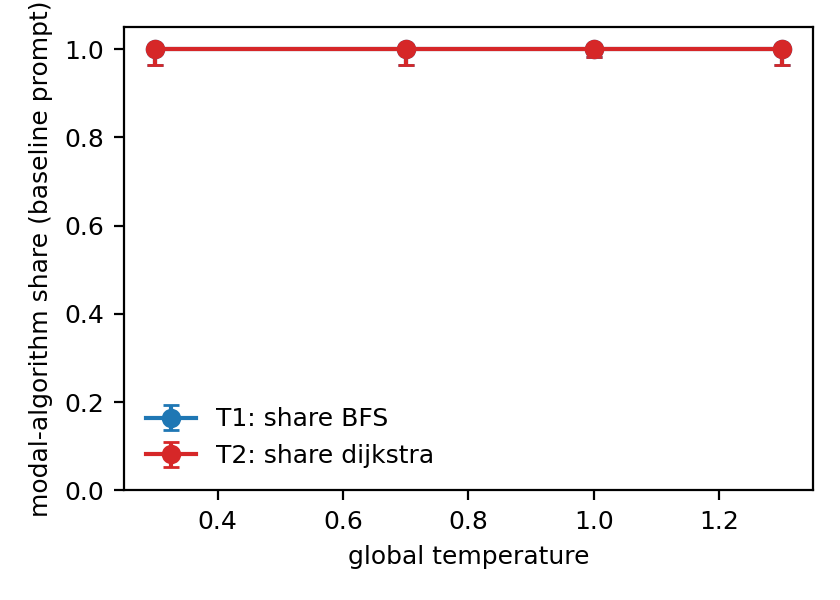

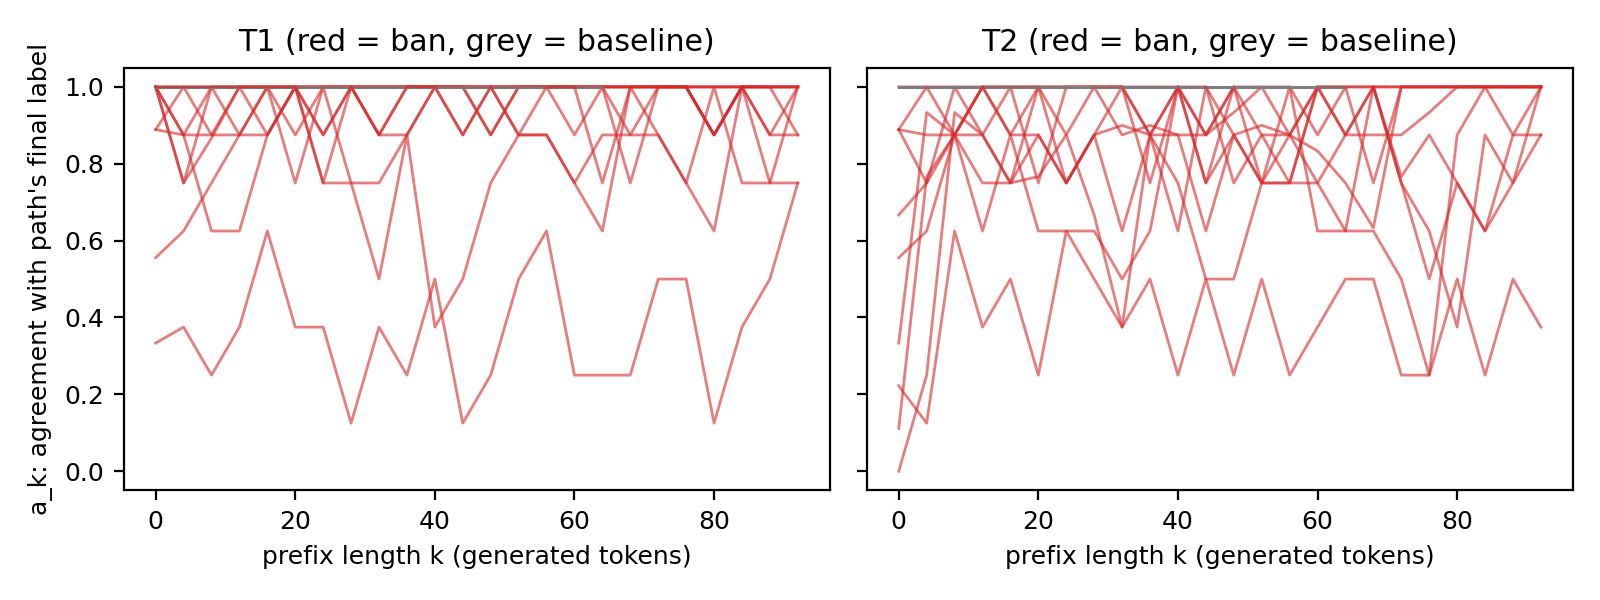

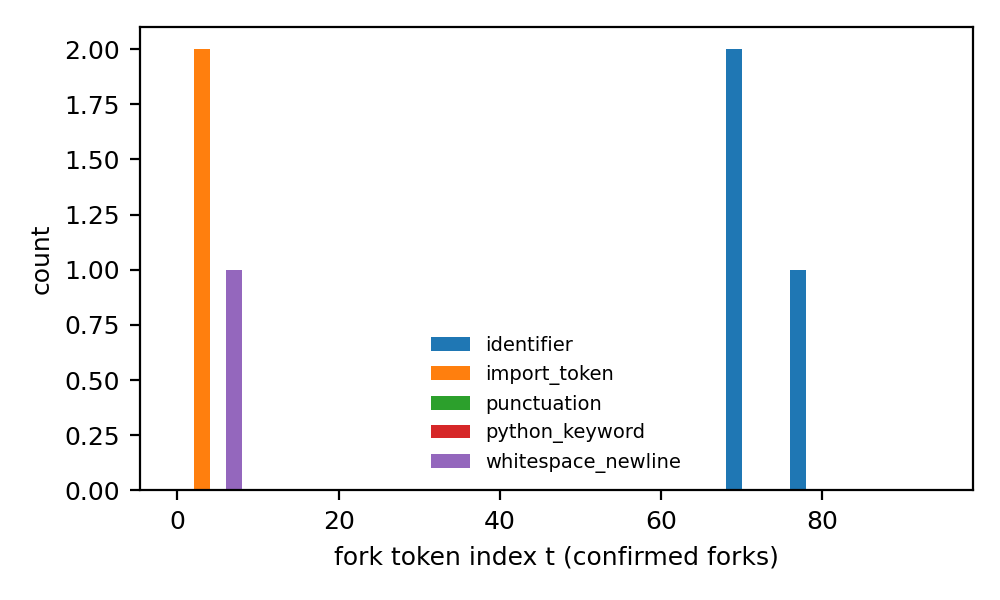

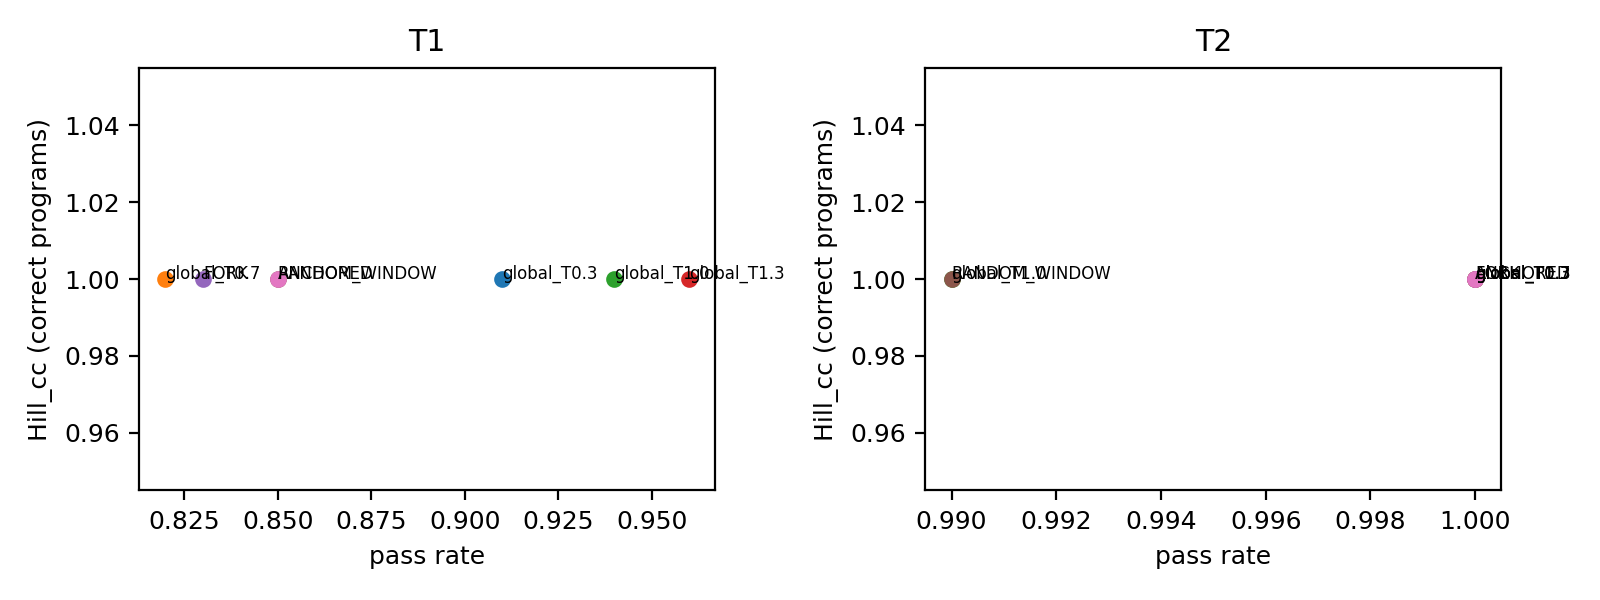

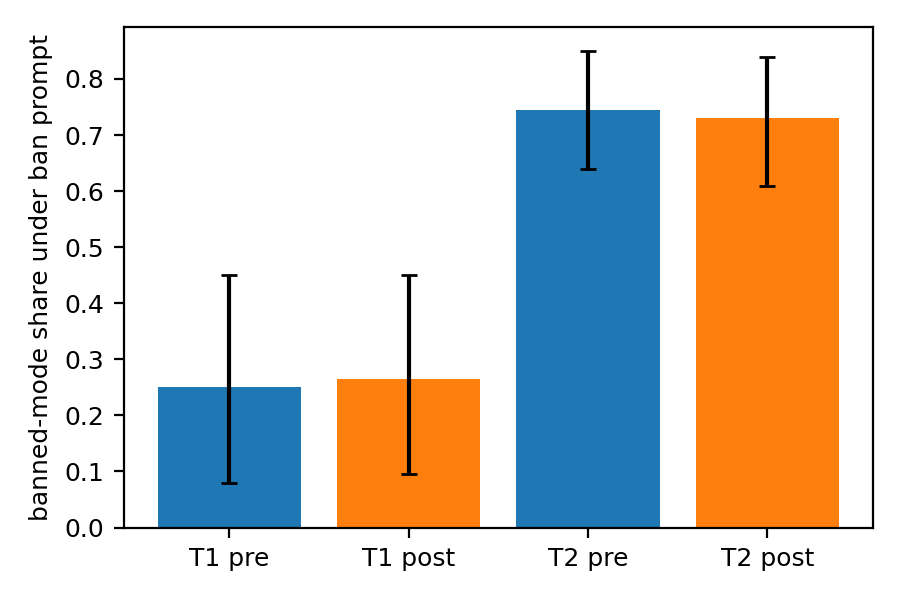

In [39]:
figs = figures(R, scr, swap, knob, pr)
(SUM_DIR / "screen.json").write_text(json.dumps({k: v for k, v in scr.items() if k != "forks"}, indent=1,
                                                default=str))
(ROOT / "forks.json").write_text(json.dumps({"forks": scr["forks"], "controls": scr["controls"]}, indent=1,
                                            default=str))
(ROOT / "swap.json").write_text(json.dumps(swap, indent=1, default=str))
(ROOT / "knob_table.json").write_text(json.dumps(knob, indent=1, default=str))
(ROOT / "probes.json").write_text(json.dumps({"summary": probe_summ, "cells": pr}, default=str))
print(figs)
for fn in figs:
    display(Image(filename=str(FIG_DIR / fn), width=640))

### 4.7 Pool summary and comparison with the recorded `method_out.json`
The pool summary is the original code. The readout dictionary uses the same expressions as the `metadata` block
`run_analysis()` writes into `method_out.json` (provenance fields such as package versions, prereg hashes and
engine tests are left out), and it is compared key by key with the recorded metadata shipped in the data.
With the original settings, everything matches except `screen_entropy` and `confirmed_forks`, for two documented
reasons. (1) The next-token distributions at fork candidates and controls were computed after the recorded
`method_out.json` was written, so the recorded file has `None` there. (2) The recorded file also predates the final
labeller revision and OpenRouter adjudication, which relabelled a few confirmation continuations. That shifts the
TVD / outcome entropy of two confirmed forks slightly. The six confirmed forks themselves (path, token index, token,
token type) are the same, as checked below.

In [40]:
pool_summ = {}
for task in ("T1", "T2"):
    for arm in ("G1", "G2", "G3_T0.3", "G3_T0.7", "G3_T1.3"):
        rows = [r for r in R["pools"] if r["task"] == task and r["arm"] == arm]
        if rows:
            pool_summ[f"{task}|{arm}"] = {"n": len(rows), "label_counts": dict(collections.Counter(
                r["label_final"] for r in rows)), "pass_rate": wilson(sum(bool(r["passed"]) for r in rows), len(rows)),
                "hill_cc": hill1([r["label_final"] for r in rows if r["passed"]]),
                "modal_share": wilson(sum(r["label_final"] == ("BFS" if task == "T1" else "dijkstra")
                                          for r in rows), len(rows))}
(SUM_DIR / "pools.json").write_text(json.dumps(pool_summ, indent=1))
meta = {
    "verdict": ver["verdict"], "verdict_trace": ver["trace"],
    "pools_summary": pool_summ, "screen_aggregate": scr["aggregate"], "screen_entropy": scr["entropy"],
    "token_type_table": scr["token_type_table"], "n_fork_candidates": len(scr["forks"]),
    "n_confirmed_forks": sum(f["confirmed"] for f in scr["forks"]),
    "confirmed_forks": [{k: f[k] for k in ("bp_id", "t", "token", "token_type", "tvd", "p_perm", "sharpness",
                                           "precedes_commit", "is_commit_token", "next_token_entropy_bits",
                                           "outcome_entropy_before_bits", "outcome_entropy_after_bits")}
                        for f in scr["forks"] if f["confirmed"]],
    "controls_summary": {"n": len(scr["controls"]), "false_positives": sum(c["false_positive"]
                                                                           for c in scr["controls"])},
    "t6_sensitivity": t6, "swap_aggregate": swap["aggregate"], "knob_table": knob["table"],
    "knob_contrasts": knob["contrasts"], "probe_summary": probe_summ,
    "row_counts": {k: len(v) for k, v in R.items()},
    "analysis_runtime_s": round(time.time() - t0, 1)}
logger.info(f"verdict {ver['verdict']}; readouts computed in {time.time() - t0:.0f}s")

recorded = data["metadata"]["recorded_method_out"]
norm = lambda o: json.loads(json.dumps(o, default=str))  # tuples -> lists, numpy -> str, as in the written file
print(f"{'readout':26s} same as recorded method_out.json?")
if (N_EXAMPLES, T6_N_SIM, CPD_N_PERM, CHI2_N_PERM, BOOT_N, BOOT_N_CONTRAST) != (40, 200, 1000, 2000, 1000, 2000):
    print("note: reduced settings in the configuration cell -> differences from the recorded run are expected")
for k in meta:
    if k in recorded and k != "analysis_runtime_s":
        print(f"{k:26s} {norm(meta[k]) == norm(recorded[k])}")
ident = lambda fs: [{k: f[k] for k in ("bp_id", "t", "token", "token_type", "precedes_commit", "is_commit_token")}
                    for f in norm(fs)]
print(f"{'confirmed forks (identity)':26s} {ident(meta['confirmed_forks']) == ident(recorded['confirmed_forks'])}"
      "   (path, t, token, token type, position relative to the commitment token)")

09:12:31|INFO   |verdict INCONCLUSIVE; readouts computed in 20s


readout                    same as recorded method_out.json?
verdict                    True
verdict_trace              True
pools_summary              True
screen_aggregate           True
screen_entropy             False
token_type_table           True
n_fork_candidates          True
n_confirmed_forks          True
confirmed_forks            False
controls_summary           True
t6_sensitivity             True
swap_aggregate             True
knob_table                 True
knob_contrasts             True
probe_summary              True
row_counts                 True
confirmed forks (identity) True   (path, t, token, token type, position relative to the commitment token)


## 5. Results at a glance

* **(a, b)** Implemented algorithm in every sampling arm. Under the baseline prompt all seven arms, global
  T = 0.3 … 1.3 and the fork-window / random-window / anchored temperature schedules, give the modal algorithm.
  The ban prompt does not remove the algorithm without replacement: it **substitutes** a neighbouring one.
* **(c)** What temperature *does* change: the number of distinct phrasings (AST-shingle clusters) of the same
  algorithm grows steeply with T, while the number of distinct algorithms stays 1.
* **(d)** Prompt swap. The banned algorithm's share when the ban prompt continues a baseline path cut just before or
  just after its commitment token.
* **(e, f)** Agreement curves a_k of the 40 base paths. Baseline paths sit at 1 from k = 0 (decided by the prompt);
  ban paths move, and the circles mark positions right after a confirmed fork.
* **(g, h)** Two ban paths with confirmed forks. At every resampled prefix length, the bars show the algorithm shares
  of the continuations (R = resampled from the prompt alone; S = 8 on the screen grid, 30 at fork candidates and
  controls). Gold = change-point bracket, red = fork token.

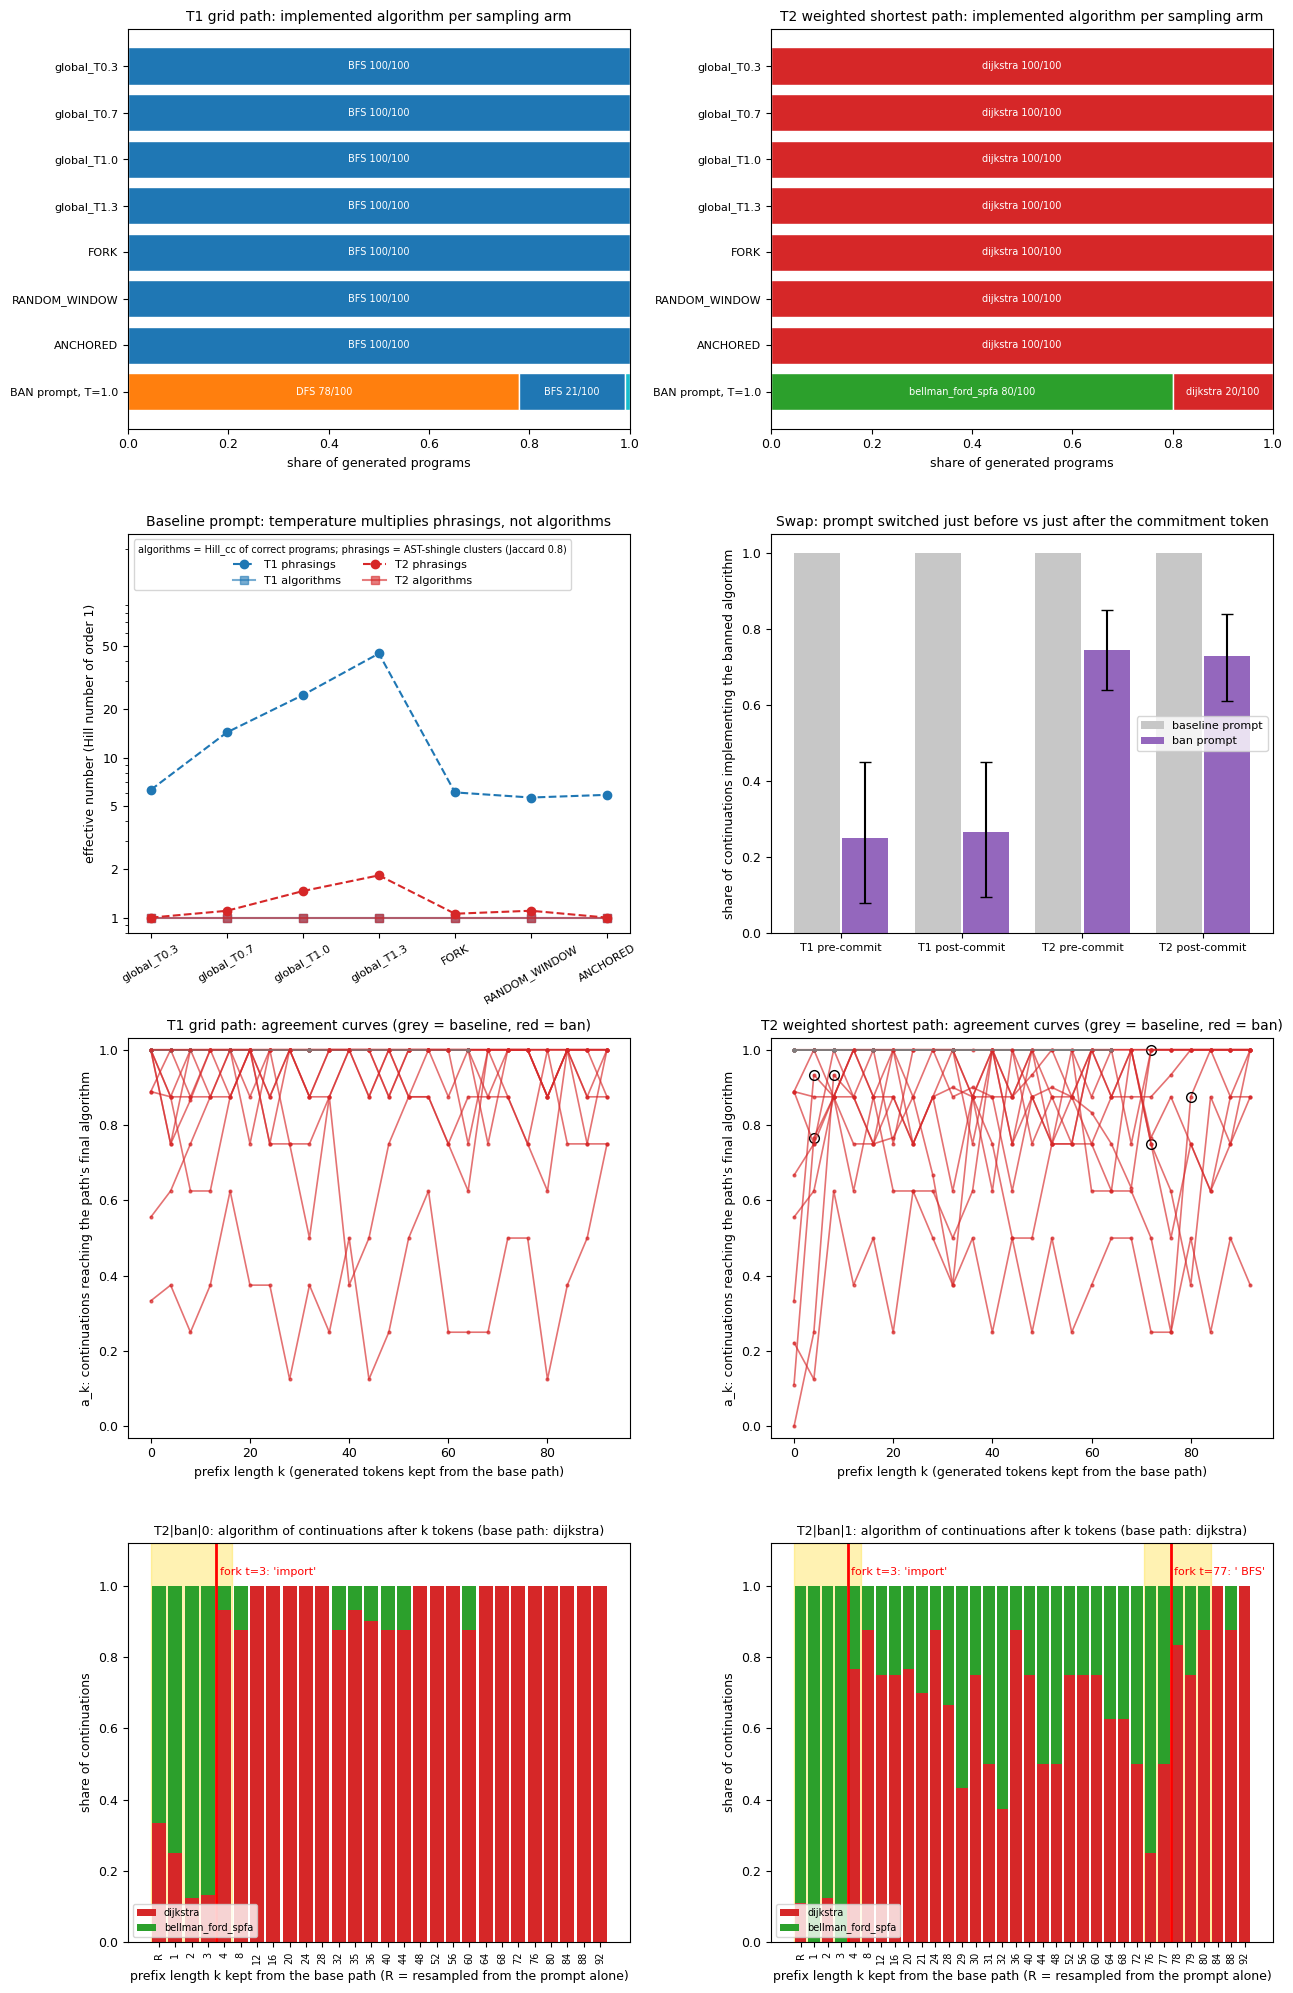

readout                                    this run                                           recorded
verdict                                    INCONCLUSIVE                                       INCONCLUSIVE
R0 decided by the prompt, T1|baseline      1.0                                                1.0
R0 decided by the prompt, T1|ban           0.8                                                0.8
R0 decided by the prompt, T2|baseline      1.0                                                1.0
R0 decided by the prompt, T2|ban           0.4                                                0.4
F1_ban_pooled                              0.294                                              0.29411764705882354
F2_ban_pooled                              1.0                                                1.0
F3_ban_pooled                              0.0                                                0.0
confirmed forks                            6                                            

In [41]:
%matplotlib inline

COL = {"BFS": "#1f77b4", "DFS": "#ff7f0e", "bidirectional_BFS": "#9467bd", "IDDFS": "#8c564b",
       "astar_greedy": "#e377c2", "unit_dijkstra": "#17becf", "dijkstra": "#d62728", "bellman_ford_spfa": "#2ca02c",
       "bidirectional_dijkstra": "#bcbd22", "floyd_warshall": "#7f7f7f", "dial": "#aec7e8", "other": "#c7c7c7",
       "no_code": "#000000"}
TASK_NAME = {"T1": "T1 grid path", "T2": "T2 weighted shortest path"}

# labels of the resampled continuations per (base path, prefix length) and o_0 per prompt, as in screen_readouts
by_pos = collections.defaultdict(list)
for fname in ("screen", "localise", "confirm"):
    for r in R[fname]:
        by_pos[(r["base_path_id"], r["prefix_len"])].append(r["label_final"])
o0 = collections.defaultdict(list)
for r in R["pools"]:
    if r["arm"] in ("G1", "G2") and r["sample_id"] != 0:
        o0[f"{r['task']}|{r['condition']}|{r['paraphrase_id']}"].append(r["label_final"])


def plot_path(ax, bp):
    """Label shares of the continuations resampled after k tokens of base path bp (R = prompt only)."""
    task = bp.split("|")[0]
    pos = [0] + sorted({p for (b, p) in by_pos if b == bp and p > 0})
    labs_at = {p: (o0[bp] + by_pos.get((bp, 0), [])) if p == 0 else by_pos[(bp, p)] for p in pos}
    bottom = np.zeros(len(pos))
    for c in [c for c in CATS[task] if any(c in v for v in labs_at.values())]:
        share = np.array([labs_at[p].count(c) / len(labs_at[p]) for p in pos])
        ax.bar(range(len(pos)), share, bottom=bottom, color=COL.get(c, "#c7c7c7"), width=0.85, label=c)
        bottom += share
    path = next(p for p in scr["paths"] if p["bp_id"] == bp)
    for cp in path["change_points"]:
        lo, hi = cp["bracket"]
        if lo in pos and hi in pos:
            ax.axvspan(pos.index(lo) - 0.5, pos.index(hi) + 0.5, color="gold", alpha=0.3, zorder=0)
    for f in scr["forks"]:
        if f["bp_id"] == bp and f["confirmed"] and f["t"] + 1 in pos:
            x = pos.index(f["t"] + 1) - 0.5
            ax.axvline(x, color="red", lw=2)
            ax.text(x + 0.25, 1.03, f"fork t={f['t']}: {f['token']!r}", color="red", fontsize=8)
    ax.set_xticks(range(len(pos)))
    ax.set_xticklabels(["R" if p == 0 else str(p) for p in pos], rotation=90, fontsize=7)
    ax.set_ylim(0, 1.12)
    ax.set_xlabel("prefix length k kept from the base path (R = resampled from the prompt alone)")
    ax.set_ylabel("share of continuations")
    ax.set_title(f"{bp}: algorithm of continuations after k tokens (base path: {path['final_label']})", fontsize=9)
    ax.legend(fontsize=7, loc="lower left")


fig, axes = plt.subplots(4, 2, figsize=(13, 20))

# (a, b) implemented algorithm per sampling arm: 7 knob arms on the baseline prompt vs the ban prompt (G2 pool)
for ax, task in zip(axes[0], ("T1", "T2")):
    arms = [(n, v["label_counts"]) for n, v in knob["table"].get(task, {}).items()]
    if f"{task}|G2" in pool_summ:
        arms.append(("BAN prompt, T=1.0", pool_summ[f"{task}|G2"]["label_counts"]))
    for i, (name, lc) in enumerate(arms):
        tot, left = sum(lc.values()), 0.0
        for lab, c in sorted(lc.items(), key=lambda kv: -kv[1]):
            ax.barh(i, c / tot, left=left, color=COL.get(lab, "#c7c7c7"), edgecolor="white")
            if c / tot >= 0.12:
                ax.text(left + c / tot / 2, i, f"{lab} {c}/{tot}", ha="center", va="center", fontsize=7, color="white")
            left += c / tot
    ax.set_yticks(range(len(arms)))
    ax.set_yticklabels([n for n, _ in arms], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of generated programs")
    ax.set_title(f"{TASK_NAME[task]}: implemented algorithm per sampling arm", fontsize=10)

# (c) algorithm diversity vs phrasing diversity per knob arm
ax = axes[1][0]
names = []
for task, colr in (("T1", "#1f77b4"), ("T2", "#d62728")):
    tb = knob["table"].get(task, {})
    names = list(tb) or names
    ax.plot(range(len(tb)), [tb[n]["phrasing"]["0.8"]["within_mode_phrasing_hill"] for n in tb], marker="o", ls="--",
            color=colr, label=f"{task} phrasings")
    ax.plot(range(len(tb)), [tb[n]["hill_cc"] for n in tb], marker="s", color=colr, alpha=0.6,
            label=f"{task} algorithms")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, fontsize=8)
ax.set_yscale("log")
ax.set_ylim(0.8, 250)  # headroom above the data for the legend
ax.set_yticks([1, 2, 5, 10, 20, 50])
ax.get_yaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.set_ylabel("effective number (Hill number of order 1)")
ax.set_title("Baseline prompt: temperature multiplies phrasings, not algorithms", fontsize=10)
ax.legend(fontsize=8, loc="upper left", ncol=2,
          title="algorithms = Hill_cc of correct programs; phrasings = AST-shingle clusters (Jaccard 0.8)",
          title_fontsize=7)

# (d) prompt swap at the commitment token: ban prompt (with bootstrap CI) vs baseline prompt on the same prefixes
ax = axes[1][1]
labels, vals, errs, base_vals = [], [], [], []
for g in ("T1", "T2"):
    a = swap["aggregate"].get(g, {})
    for side in ("pre", "post"):
        k = a.get(f"{side}_ban_banned_share")
        if k:
            labels.append(f"{g} {side}-commit")
            vals.append(k["mean"])
            errs.append([max(0.0, k["mean"] - k["ci"][0]), max(0.0, k["ci"][1] - k["mean"])])
            bs = [p[f"{side}_base_banned_share"] for p in swap["paths"]
                  if p["task"] == g and p[f"{side}_base_banned_share"] is not None]
            base_vals.append(float(np.mean(bs)) if bs else np.nan)
if labels:
    x = np.arange(len(labels))
    ax.bar(x - 0.2, base_vals, width=0.38, color="#c7c7c7", label="baseline prompt")
    ax.bar(x + 0.2, vals, width=0.38, yerr=np.array(errs).T, capsize=4, color="#9467bd", label="ban prompt")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.legend(fontsize=8, loc="center right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of continuations implementing the banned algorithm")
ax.set_title("Swap: prompt switched just before vs just after the commitment token", fontsize=10)

# (e, f) agreement curves a_k of all base paths, confirmed forks circled
conf = collections.defaultdict(list)
for f in scr["forks"]:
    if f["confirmed"]:
        conf[f["bp_id"]].append(f["t"])
for ax, task in zip(axes[2], ("T1", "T2")):
    for p in scr["paths"]:
        if p["task"] != task:
            continue
        ks = sorted(int(k) for k in p["agreement"])
        ax.plot(ks, [p["agreement"][str(k)] for k in ks], color="#d62728" if p["condition"] == "ban" else "#7f7f7f",
                alpha=0.65, lw=1.2, marker="o", ms=2)
        for t in conf.get(p["bp_id"], []):
            k_next = min([k for k in ks if k > t], default=None)
            if k_next is not None:
                ax.plot(k_next, p["agreement"][str(k_next)], "o", color="k", ms=7, mfc="none")
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel("prefix length k (generated tokens kept from the base path)")
    ax.set_ylabel("a_k: continuations reaching the path's final algorithm")
    ax.set_title(f"{TASK_NAME[task]}: agreement curves (grey = baseline, red = ban)", fontsize=10)

# (g, h) outcome composition along base paths with confirmed forks (fallback: T6 calibration of the test)
forks_c = sorted([f for f in scr["forks"] if f["confirmed"]], key=lambda f: (f["t"], f["bp_id"]))
nf = collections.Counter(f["bp_id"] for f in forks_c)
first = forks_c[0]["bp_id"] if forks_c else None
second = max((b for b in nf if b != first), key=lambda b: (nf[b], max(f["t"] for f in forks_c if f["bp_id"] == b)),
             default=None)
ban_paths = [p for p in scr["paths"] if p["condition"] == "ban"]
if first is None and ban_paths:
    first = max(ban_paths, key=lambda p: len(p["change_points"]))["bp_id"]
if first is not None:
    plot_path(axes[3][0], first)
if second is not None:
    plot_path(axes[3][1], second)
else:
    ax = axes[3][1]
    tvs = [0.0, 0.2, 0.3, 0.5]
    ax.plot(tvs, [t6[str(v)]["detect_right_bracket"] for v in tvs], "o-", label="change point at the planted position")
    ax.plot(tvs, [t6[str(v)]["any_cp"] for v in tvs], "s--", label="any change point")
    ax.set_xlabel("planted total-variation shift")
    ax.set_ylabel("share of simulated paths")
    ax.set_title("T6: power and false-positive rate of the change-point test", fontsize=10)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# key numbers: recomputed here vs recorded in the artifact's method_out.json
rec = data["metadata"]["recorded_method_out"]
rows = [("verdict", ver["verdict"], rec["verdict"])]
for g in ("T1|baseline", "T1|ban", "T2|baseline", "T2|ban"):
    if g in scr["aggregate"]:
        rows.append((f"R0 decided by the prompt, {g}", round(scr["aggregate"][g]["R0"][0], 3),
                     round(rec["screen_aggregate"][g]["R0"][0], 3)))
for k in ("F1_ban_pooled", "F2_ban_pooled", "F3_ban_pooled"):
    v = ver["trace"].get(k)
    rows.append((k, None if v is None else round(v, 3), rec["verdict_trace"].get(k)))
rows.append(("confirmed forks", meta["n_confirmed_forks"], rec["n_confirmed_forks"]))
rows.append(("control false positives", f"{meta['controls_summary']['false_positives']}/{meta['controls_summary']['n']}",
             f"{rec['controls_summary']['false_positives']}/{rec['controls_summary']['n']}"))
for task in ("T1", "T2"):
    if task in knob["contrasts"]:
        rows.append((f"K1 Hill(FORK) - Hill(RANDOM) {task}",
                     knob["contrasts"][task]["K1_fork_minus_random_window"]["diff"],
                     rec["knob_contrasts"][task]["K1_fork_minus_random_window"]["diff"]))
    for arm in ("G1", "G2"):
        if f"{task}|{arm}" in pool_summ:
            rows.append((f"{task}|{arm} algorithm counts", pool_summ[f"{task}|{arm}"]["label_counts"],
                         rec["pools_summary"][f"{task}|{arm}"]["label_counts"]))
ent = scr["entropy"]
rows.append(("next-token entropy fork / control (bits)",
             (None if ent["fork_next_token_entropy_mean_bits"] is None else round(ent["fork_next_token_entropy_mean_bits"], 3),
              None if ent["control_next_token_entropy_mean_bits"] is None else round(ent["control_next_token_entropy_mean_bits"], 3)),
             (rec["screen_entropy"]["fork_next_token_entropy_mean_bits"],
              rec["screen_entropy"]["control_next_token_entropy_mean_bits"])))
print(f"{'readout':42s} {'this run':50s} recorded")
for name, a, b in rows:
    print(f"{name:42s} {str(a):50s} {b}")

### Reading the results
* **The prompt, not the sampler, picks the algorithm.** Under the neutral prompt all 20 base paths are decided before
  the first generated token (a_0 ≥ 0.8; agreement stays at 1), and every baseline sampling arm, global T from 0.3 to
  1.3 and the three windowed-temperature schedules, implements BFS on T1 and Dijkstra on T2 in 100/100 samples
  (Hill_cc = 1.0, so K1 = K4 = 0). Temperature changes *how* the algorithm is written: the within-algorithm phrasing
  Hill number on T1 grows from ≈6 at T = 0.3 to ≈45 at T = 1.3 (T2: 1.0 → 1.8), with pass rates of 0.82–1.0.
* **A ban substitutes rather than subtracts.** "Do not use BFS" mostly yields DFS (78/100; BFS still 21/100); "Do not
  use Dijkstra's algorithm" mostly yields Bellman–Ford/SPFA (80/100; Dijkstra still 20/100).
* **Forks appear only where the prompt leaves room: early import tokens and algorithm names in comments.** All 6
  confirmed forks lie on T2 ban paths. One kind is the first code token after the opening fence: `import`, which
  leads to `import heapq`, moves continuations from 4/30 to 28/30 Dijkstra; the newline after
  `from collections import deque` works the same way. The other kind is the name written into a comment: `# Bell…`
  gives 29/30 Bellman–Ford; `# D…` ("Dijkstra's algorithm is not allowed") raises Dijkstra from 0/30 to 13/30; and
  "…so we use" + ` BFS` ("BFS with priority queue") gives 25/30 Dijkstra in disguise. Fork tokens carry about 0.9
  bits of next-token entropy against about 0.02 bits at control tokens, and no control pair was a false positive
  (F3 = 0/10). But only 5 of 17 non-fixed ban paths have a confirmed fork (F1 = 0.29 < 0.5), and the probes were not
  run (D1 false), so the pre-registered verdict is **INCONCLUSIVE**.
* **No lock-in at the commitment token.** The ban prompt removes the banned algorithm about as well after the
  commitment token as before it (banned share T1: 0.25 pre vs 0.27 post; T2: 0.75 vs 0.73), so the predicted
  pre > post effect fails on both tasks.